In [1]:
import sys
sys.version

'3.13.9 | packaged by Anaconda, Inc. | (main, Oct 21 2025, 19:09:58) [MSC v.1929 64 bit (AMD64)]'

Make sure your Python version is compatible with Python MIP package!

***
# Journal Article Analysis Notebook
by Fabian Nolz and Victor Bolbot (extended the previous version published in MOSES conference and at https://github.com/gertibrumm/nexusprime-public/)
- Clustered Operational Data -> multi scenario
- Multiple fuels
- Multiple engine and fuel cell sizes
- Updated cost values
- Novel constraints introduced

***
# Setup
- graph_v2() is the function to plot the dynamic graph visually
- optigraph_scenarios() actually creates the mathematical formulation and returns the optimal node & edge data

## Auxilliary setup

In [103]:
#%pip install mip%pip install adjustText
import numpy as np
import math
from IPython.display import IFrame
from mip import *
import matplotlib.pyplot as plt
import pandas
import time
import copy
from contextlib import contextmanager
import os
import re
print(os.cpu_count())
from scipy.interpolate import PchipInterpolator
from adjustText import adjust_text

16


In [104]:
def siground_safe(x, sig=4, cap=1e-8):
    if pandas.isna(x):
        return x
    if not isinstance(x, (int, float, np.integer, np.floating)):
        return x
    if x == 0:
        return 0.0
    order = math.floor(math.log10(abs(x)))
    rounded = round(float(x), sig - order - 1)
    return 0.0 if abs(rounded) < cap else rounded

In [105]:
def siground(x, sig=4, cap=1e-8):
    if x == 0:
        return 0.0
    order = math.floor(math.log10(abs(x)))
    rounded = round(x, sig - order - 1)
    return 0.0 if abs(rounded) < cap else rounded

In [106]:
def getvalue(cell, t=0):
    if isinstance(cell, (list, np.ndarray)):  # return the value in the cells array, case of multiple scenarios
        return cell[t]
    elif isinstance(cell, (int, float)):  # nan, int and float value in table
        return cell

## Graph code

In [107]:
def graph_v2(nodes, edges, t=0, width=800, height=500, verbose=False):
    """features:
        - all values are in lists, visualise a specific index"""
    begin = []
    with open("begin-dash-label.txt", "r") as text_file:
    #with open("begin.txt", "r") as text_file:
        begin = text_file.readlines()
    mid = ['                ],"nodes":[\n']
    end = []
    with open("end.txt", "r") as text_file:
        end = text_file.readlines()
    
    def getit(name):
        # if verbose: print(name)
        # print(name)
        return nodes.index[nodes['name'] == name][0]
    
    def stroke(edges, i):
        value = getvalue(edges.loc[i, 'value'], t)
        unit = edges.loc[i, 'unit']
        if pandas.isna(value) or value==0:
            return "", 1, 0
        else:
            maxi = edges.loc[edges["unit"]==unit, "value"].apply(lambda x: np.max(x) if isinstance(x, (list, np.ndarray)) else 0).max()
            return "{:.4g} {}".format(value, unit), value/maxi*3.4 + 0.5, 1
    
    l = ['                    {{"marker_color":"#808080","marker_start":"","marker_end":"arrow","weight":30.0,"color":"#808080","label":"{}","label_color":"#808080","label_fontsize":8,"edge_width":{},"edge_distance":100.0,"edge_style":{},"edge_weight":1,"source":{},"target":{},"source_label":"{}","target_label":"{}"}},\n'.format(
        *stroke(edges, i), getit(edges.iloc[i]['source']), getit(edges.iloc[i]['target']), edges.iloc[i]['source'], edges.iloc[i]['target'] ) for i in range(len(edges))]
    edge_string = '!'.join(l)
    edge_list = edge_string.split('!')
    
    def nodeformat(t):
        if t == "machinery":
            return "#555"
        else:
            return "#fff"
    
    l = ['                    {{"name":"{}","group":"{}","node_name":"100","node_marker":"circle","node_tooltip":"100","node_color":"#000000","node_opacity":"1.0","node_size":"8.0","node_size_edge":"1","node_color_edge":"{}","node_fontcolor":"#000000","node_fontsize":"12"}},\n'.format(
        nodes.iloc[i]['name'], nodes.iloc[i]['cluster'], nodeformat(nodes.iloc[i]['type']) ) for i in range(len(nodes))]
    node_string = '!'.join(l)
    node_list = node_string.split('!')

    with open("elasticgraph.html", "w") as text_file:
        text_file.writelines(begin+edge_list+mid+node_list+end)

    return IFrame(src="elasticgraph.html", width=width, height=height)

In [108]:
MOTOR_EFFICIENCY = 0.95

def calculate_power_loads(df, indices=slice(None)):
    """
    Decompose total DG net electrical power into:
    1. Hotel and other electrical loads
    2. Mechanical propulsion power

    DG net power is preserved.
    Propulsion power is preserved.
    Hotel load is adjusted for motor efficiency.
    """

    dg_net = df.iloc[indices]["DG net power (kW)"].to_numpy(dtype=float)
    prop = df.iloc[indices]["Net propelling power (kW)"].to_numpy(dtype=float)

    # Electrical power required by the propulsion motor
    propulsion_electrical = prop / MOTOR_EFFICIENCY

    # Residual hotel and other electrical loads
    hotel_load = dg_net - propulsion_electrical

    # Check that the decomposition is physically consistent
    if np.any(hotel_load < -1e-6):
        raise ValueError(
            "Negative hotel load detected. Check the DG net power, "
            "propulsion power and motor efficiency definitions."
        )

    return hotel_load.tolist(), prop.tolist(), dg_net.tolist()

## Optimization code

In [109]:
def get_pair_id_from_slot(slot):
    """
    slots 1,2 -> pair 1
    slots 3,4 -> pair 2
    slots 5,6 -> pair 3
    """
    return (int(slot) - 1) // 2 + 1


def add_pairwise_engine_family_constraints(
    m,
    nodes,
    install_vars,
    family_prefix,
    family_label
):
    """
    For one engine family (ICE / MICE / DICE), enforce:
    - at most one size option per slot
    - slots must be used in order
    - engine count must be in {0,2,4,6}
    - engines are activated pairwise
    - both engines in one pair must have the same size
    - lower-numbered pairs used before higher-numbered pairs

    Returns:
        count_choice : dict {0,2,4,6} -> binary var
        pair_used    : dict pair_id -> binary var
    """
    fam_nodes = nodes[
        (nodes["type"] == "machinery") &
        (nodes["name"].str.startswith(family_prefix)) &
        (nodes["slot"].notna())
    ].copy()

    if fam_nodes.empty:
        count_choice = {
            0: m.add_var(name=f"y_{family_label.lower()}_0", var_type=BINARY),
            2: m.add_var(name=f"y_{family_label.lower()}_2", var_type=BINARY),
            4: m.add_var(name=f"y_{family_label.lower()}_4", var_type=BINARY),
            6: m.add_var(name=f"y_{family_label.lower()}_6", var_type=BINARY),
        }
        m += count_choice[0] == 1, f"one_{family_label}_count_choice_empty"
        m += count_choice[2] == 0, f"{family_label}_count_2_empty"
        m += count_choice[4] == 0, f"{family_label}_count_4_empty"
        m += count_choice[6] == 0, f"{family_label}_count_6_empty"
        return count_choice, {}

    fam_nodes["pair"] = fam_nodes["slot"].apply(get_pair_id_from_slot)

    # -------------------------------------------------
    # 1) Slot exclusivity: at most one candidate per slot
    # -------------------------------------------------
    slot_values = sorted(fam_nodes["slot"].dropna().unique())
    for slot in slot_values:
        slot_node_names = fam_nodes.loc[fam_nodes["slot"] == slot, "name"].tolist()
        chosen = [install_vars[name] for name in slot_node_names if name in install_vars]
        if len(chosen) > 0:
            m += xsum(chosen) <= 1, f"slot_select_{family_label}_{slot}"

    # -------------------------------------------------
    # 2) Symmetry breaking across slots
    # -------------------------------------------------
    for s_idx in range(1, len(slot_values)):
        prev_slot = slot_values[s_idx - 1]
        curr_slot = slot_values[s_idx]

        prev_nodes = fam_nodes.loc[fam_nodes["slot"] == prev_slot, "name"].tolist()
        curr_nodes = fam_nodes.loc[fam_nodes["slot"] == curr_slot, "name"].tolist()

        prev_used = xsum(install_vars[n] for n in prev_nodes if n in install_vars)
        curr_used = xsum(install_vars[n] for n in curr_nodes if n in install_vars)

        m += prev_used >= curr_used, f"{family_label}_slot_order_{prev_slot}_{curr_slot}"

    # -------------------------------------------------
    # 3) Count choice in {0,2,4,6}
    # -------------------------------------------------
    count_choice = {
        0: m.add_var(name=f"y_{family_label.lower()}_0", var_type=BINARY),
        2: m.add_var(name=f"y_{family_label.lower()}_2", var_type=BINARY),
        4: m.add_var(name=f"y_{family_label.lower()}_4", var_type=BINARY),
        6: m.add_var(name=f"y_{family_label.lower()}_6", var_type=BINARY),
    }

    m += xsum(count_choice.values()) == 1, f"one_{family_label}_count_choice"

    fam_install = [
        install_vars[nodename]
        for nodename in install_vars
        if nodename.startswith(family_prefix)
    ]

    m += xsum(fam_install) == (
        2 * count_choice[2] +
        4 * count_choice[4] +
        6 * count_choice[6]
    ), f"{family_label}_count_choice"

    # -------------------------------------------------
    # 4) Pair usage variables
    # -------------------------------------------------
    pair_ids = sorted(fam_nodes["pair"].unique())
    pair_used = {
        p: m.add_var(name=f"y_pair_{family_label}_{p}", var_type=BINARY)
        for p in pair_ids
    }

    # number of used pairs = 0,1,2,3 corresponding to 0,2,4,6 engines
    m += xsum(pair_used[p] for p in pair_ids) == (
        count_choice[2] + 2 * count_choice[4] + 3 * count_choice[6]
    ), f"{family_label}_pair_count_link"

    # lower-numbered pairs first
    for p_idx in range(1, len(pair_ids)):
        prev_p = pair_ids[p_idx - 1]
        curr_p = pair_ids[p_idx]
        m += pair_used[prev_p] >= pair_used[curr_p], f"{family_label}_pair_order_{prev_p}_{curr_p}"

    # -------------------------------------------------
    # 5) Inside each pair:
    #    - either both slots active or none
    #    - same size in both slots
    # -------------------------------------------------
    fam_nodes_with_size = fam_nodes[fam_nodes["size_option"].notna()].copy()

    for p in pair_ids:
        pair_rows = fam_nodes_with_size[fam_nodes_with_size["pair"] == p].copy()
        pair_slots = sorted(pair_rows["slot"].unique())

        # exactly 2 selected engines if pair is used
        pair_install = [
            install_vars[row["name"]]
            for _, row in pair_rows.iterrows()
            if row["name"] in install_vars
        ]
        if len(pair_install) > 0:
            m += xsum(pair_install) == 2 * pair_used[p], f"{family_label}_pair_exact2_{p}"

        # same size in the 2 slots of the pair
        size_options = sorted(pair_rows["size_option"].unique())
        if len(pair_slots) == 2:
            for Pn in size_options:
                slot_exprs = []
                for slot in pair_slots:
                    slot_rows = pair_rows[
                        (pair_rows["slot"] == slot) &
                        (pair_rows["size_option"] == Pn)
                    ]
                    expr = xsum(
                        install_vars[row["name"]]
                        for _, row in slot_rows.iterrows()
                        if row["name"] in install_vars
                    )
                    slot_exprs.append(expr)

                if len(slot_exprs) == 2:
                    m += slot_exprs[0] == slot_exprs[1], f"{family_label}_pair_same_size_{p}_{int(Pn)}"

    return count_choice, pair_used


def add_equal_dispatch_by_pair(
    m,
    nodes,
    install_vars,
    dispatch_vars,
    n_scenarios,
    family_prefix,
    family_label,
    bigM
):
    """
    Equal dispatch only within each installed pair.
    Different pairs may dispatch differently.
    """
    fam_nodes = nodes[
        (nodes["type"] == "machinery") &
        (nodes["name"].str.startswith(family_prefix)) &
        (nodes["slot"].notna())
    ].copy()

    if fam_nodes.empty:
        return {}

    fam_nodes["pair"] = fam_nodes["slot"].apply(get_pair_id_from_slot)

    eq_dispatch_vars = {}
    pair_ids = sorted(fam_nodes["pair"].unique())

    for p in pair_ids:
        pair_rows = fam_nodes[fam_nodes["pair"] == p]
        pair_node_names = pair_rows["name"].tolist()

        for t in range(n_scenarios):
            d_common = m.add_var(
                name=f"d_common_{family_label}_pair{p}_{t}",
                lb=0,
                ub=bigM
            )
            eq_dispatch_vars[(family_label, p, t)] = d_common

            for k, nodename in enumerate(pair_node_names):
                if nodename not in install_vars:
                    continue
                z = install_vars[nodename]
                m_node = dispatch_vars[(t, nodename)]

                m += m_node - d_common <= bigM * (1 - z), f"eqdisp_up_{family_label}_p{p}_{t}_{k}"
                m += d_common - m_node <= bigM * (1 - z), f"eqdisp_lo_{family_label}_p{p}_{t}_{k}"

    return eq_dispatch_vars

In [110]:
# ============================================================
# Global counters for this notebook session
# ============================================================
if "OPTIMIZATION_RUN_COUNTER" not in globals():
    OPTIMIZATION_RUN_COUNTER = 0

if "OPTIMIZATION_TOTAL_TIME" not in globals():
    OPTIMIZATION_TOTAL_TIME = 0.0


def run_optimization_with_monitor(nodes, edges, hours, n_scenarios=1, peak_required_power=None, emissions_cap=None):
    global OPTIMIZATION_RUN_COUNTER, OPTIMIZATION_TOTAL_TIME

    OPTIMIZATION_RUN_COUNTER += 1
    current_run = OPTIMIZATION_RUN_COUNTER

    print("=" * 75, flush=True)
    print(f"Preparing optimization run #{current_run}", flush=True)
    print(f"Number of scenarios: {n_scenarios}", flush=True)
    print(f"Peak required power: {peak_required_power:,.2f} kW", flush=True)
    if emissions_cap is not None:
        print(f"Emissions cap: {emissions_cap:,.2f}", flush=True)
    print("Building model and calling solver...", flush=True)

    t0 = time.time()

    m, post_nodes, post_edges = optigraph_scenarios(
        nodes,
        edges,
        hours,
        n_scenarios=n_scenarios,
        peak_required_power=peak_required_power,
        emissions_cap=emissions_cap
    )

    elapsed = time.time() - t0
    OPTIMIZATION_TOTAL_TIME += elapsed

    print(f"Optimization run #{current_run} finished.", flush=True)
    print(f"Time spent in this run: {elapsed:.2f} s", flush=True)
    print(f"Cumulative optimization time: {OPTIMIZATION_TOTAL_TIME:.2f} s", flush=True)
    print(f"Average time per run: {OPTIMIZATION_TOTAL_TIME / OPTIMIZATION_RUN_COUNTER:.2f} s/run", flush=True)

    try:
        print(f"Solver status: {m.status}", flush=True)
    except Exception:
        print("Solver status: not available", flush=True)

    try:
        print(f"Objective value: {m.objective_value:,.2f}", flush=True)
    except Exception:
        print("Objective value: not available", flush=True)

    try:
        print(f"Variables: {len(m.vars)}", flush=True)
        print(f"Constraints: {len(m.constrs)}", flush=True)
    except Exception:
        pass

    print("=" * 75, flush=True)

    return m, post_nodes, post_edges, elapsed

In [111]:
def get_edgename(time, sourcename, targetname):
    return "_".join("x {} {} to {}".format(time, sourcename, targetname).split())

def get_connected(nodename, nodes, edges):
    in_rows = edges[edges["target"] == nodename]
    out_rows = edges[edges["source"] == nodename]

    inputs = in_rows["source"].tolist()
    outputs = out_rows["target"].tolist()
    return inputs, outputs

def get_connected_index(nodename, nodes, edges):
    inputs = [i for i in range(len(edges)) if edges.iloc[i]["target"] == nodename]
    outputs = [i for i in range(len(edges)) if edges.iloc[i]["source"] == nodename]
    return inputs, outputs

def get_x_from_name(name, df):
    return df["variable"][df.index[df["name"] == name][0]]

def get_index_from_name(name, df):
    return df.index[df["name"] == name][0]

def write_list(df, index, column, lst):
    df.loc[[index], column] = pandas.Series([lst], index=df.index[[index]])

def optigraph_scenarios(
    nodes,
    edges,
    hours,
    n_scenarios=1,
    peak_required_power=None,
    emissions_cap=None,
    forced_pathway=None,
    min_pathway_share=0.01,
    exclusive_pathway=False
):
    print(f"[optigraph] start build, scenarios={n_scenarios}", flush=True)
    m = Model()
    m.verbose = 0

    install_vars = {}
    size_vars = {}
    fc_option_vars = {}
    dispatch_vars = {}
    emission_vars = []
    maintenance_terms = []
    edge_flow_vars = {}
    
    for i in range(len(nodes)):
        nodename = nodes.iloc[i]["name"]
        machinerycost = nodes.iloc[i]["cost"]
    
        if nodes.iloc[i]["type"] == "machinery":
            machineryvar = m.add_var(name=f"max_m_{nodename}", obj=machinerycost)
            size_vars[nodename] = machineryvar
    
            is_binary_node = (
                "count_binary" in nodes.columns
                and pandas.notna(nodes.iloc[i]["count_binary"])
                and nodes.iloc[i]["count_binary"] == True
            )
    
            is_fc_node = (
                "tech" in nodes.columns
                and pandas.notna(nodes.iloc[i]["tech"])
                and str(nodes.iloc[i]["tech"]).upper() in ["PEMFC", "SOFC"]
            )
    
            # -------------------------------------------------
            # A. Fuel-cell machinery with special unit logic
            # -------------------------------------------------
            if is_fc_node:
                fixed_cost = 0
                if "fixed_cost" in nodes.columns and pandas.notna(nodes.loc[i, "fixed_cost"]):
                    fixed_cost = float(nodes.loc[i, "fixed_cost"])
            
                # Required FC option metadata from nodes dataframe
                if "fc_count_options" not in nodes.columns:
                    raise ValueError(f"fc_count_options missing for fuel-cell node {nodename}")
                if "fc_size_grid" not in nodes.columns:
                    raise ValueError(f"fc_size_grid missing for fuel-cell node {nodename}")
            
                count_options = nodes.loc[i, "fc_count_options"]
                size_grid = nodes.loc[i, "fc_size_grid"]
            
                if count_options is None or not isinstance(count_options, (list, tuple, np.ndarray)) or len(count_options) == 0:
                    raise ValueError(f"fc_count_options invalid for fuel-cell node {nodename}")
                if size_grid is None or not isinstance(size_grid, (list, tuple, np.ndarray)) or len(size_grid) == 0:
                    raise ValueError(f"fc_size_grid invalid for fuel-cell node {nodename}")
            
                count_options = list(count_options)
                size_grid = list(size_grid)
            
                # One binary per (count, unit_size) option
                # Put fixed cost on each option binary, so selecting any option pays the install cost once
                y_fc = {}
                for n_units_opt in count_options:
                    for unit_size_opt in size_grid:
                        y_fc[(n_units_opt, unit_size_opt)] = m.add_var(
                            name=f"y_fc_{nodename}_{int(n_units_opt)}_{int(unit_size_opt)}",
                            var_type=BINARY,
                            obj=fixed_cost
                        )
            
                fc_option_vars[nodename] = y_fc
            
                # Choose at most one FC option
                m += xsum(y_fc.values()) <= 1, f"fc_one_option_{nodename}"
            
                # Installed total FC capacity [kW]
                m += machineryvar == xsum(
                    n_units_opt * unit_size_opt * y_fc[(n_units_opt, unit_size_opt)]
                    for n_units_opt in count_options
                    for unit_size_opt in size_grid
                ), f"fc_capacity_{nodename}"
            
      
                
            # -------------------------------------------------
            # B. Other binary machinery (ICE engines etc.)
            # -------------------------------------------------
            elif is_binary_node:
                fixed_cost = 0
                if "fixed_cost" in nodes.columns and pandas.notna(nodes.iloc[i]["fixed_cost"]):
                    fixed_cost = nodes.iloc[i]["fixed_cost"]
    
                z = m.add_var(name=f"z_{nodename}", var_type=BINARY, obj=fixed_cost)
                install_vars[nodename] = z
    
                # optional minimum installed size when selected
                LB_if_selected = 0.0
                if "lb_if_selected" in nodes.columns and pandas.notna(nodes.iloc[i]["lb_if_selected"]):
                    LB_if_selected = float(nodes.iloc[i]["lb_if_selected"])
                
                # fixed-size binary machinery: exact on/off size, no extra cap-link constraints needed
                if "size_option" in nodes.columns and pandas.notna(nodes.iloc[i]["size_option"]):
                    Pn = float(nodes.iloc[i]["size_option"])
                    m += machineryvar == Pn * z, f"fixed_size_option_{nodename}"
                
                # variable-size binary machinery: keep upper/lower linking constraints
                else:
                    if "ub" in nodes.columns and pandas.notna(nodes.iloc[i]["ub"]):
                        UB = float(nodes.iloc[i]["ub"])
                    else:
                        raise ValueError(
                            f"Binary machinery node {nodename} needs either 'size_option' or 'ub'."
                        )
                
                    m += machineryvar <= UB * z, f"binary_cap_ub_{nodename}"
                    if LB_if_selected > 0:
                        m += machineryvar >= LB_if_selected * z, f"binary_cap_lb_{nodename}"
    
            # -------------------------------------------------
            # C. Continuous machinery (always available)
            # -------------------------------------------------
            else:
                # no install binary needed
                pass
    for t in range(n_scenarios):
        print(f"[optigraph] building scenario {t+1}/{n_scenarios}", flush=True)

        x = []

        for i in range(len(edges)):
            source = edges.iloc[i]["source"]
            target = edges.iloc[i]["target"]
            edgename = get_edgename(t, source, target)

            edgecost = 0 if pandas.isna(edges.iloc[i]["cost"]) else getvalue(edges.iloc[i]["cost"], t)
            lb = 0 if pandas.isna(edges.iloc[i]["lb"]) else getvalue(edges.iloc[i]["lb"], t)
            ub = float("inf") if pandas.isna(edges.iloc[i]["ub"]) else getvalue(edges.iloc[i]["ub"], t)

            var = m.add_var(name=edgename, obj=edgecost, lb=lb, ub=ub)
            x.append(var)
            edge_flow_vars[(t, source, target)] = var

            # collect total WtW emissions variable(s)
            if source == "WtW" and target == "environment":
                emission_vars.append(var)

        variabledf = pandas.DataFrame(np.array([x, [x[i].name for i in range(len(x))]]).transpose(), columns=["variable", "name"])


        print(f"[optigraph] scenario {t+1}: edge vars created", flush=True)

        # every machinery node splits into its significant flow variable with its in- and out-ratios
        
        for n in range(len(nodes)):
            nodename = nodes.iloc[n]["name"]
            if nodes.iloc[n]["type"] == "machinery":
                machineryvar = m.add_var(name='m_{}_{}'.format(t, nodename))
                dispatch_vars[(t, nodename)] = machineryvar


                
                maint_coeff = 0.0
                if "maint_cost_per_kwh" in nodes.columns and pandas.notna(nodes.iloc[n]["maint_cost_per_kwh"]):
                    maint_coeff = float(nodes.iloc[n]["maint_cost_per_kwh"])

                if maint_coeff > 0:
                    maintenance_terms.append(maint_coeff * hours[t] * machineryvar)

                
                

                # if isinstance(nodes.loc[n, "SOS2"], (list, np.ndarray)):  # nonlinear machinery
                discontinuous = False
                sos2 = nodes.iloc[n]["SOS2"]
                nonlinear = False
                                
                if isinstance(sos2, (list, np.ndarray)):
                    sos2 = list(sos2)
                    nonlinear = True
                    D = len(sos2)
                    if sos2[0] > 0:
                        discontinuous = True
                        sos2 = [0, sos2[0] / 2] + sos2
                        D += 2
                        w = [m.add_var() for _ in range(D)]
                        m += w[1] == 0
                    else:
                        w = [m.add_var() for _ in range(D)]
                
                    m += xsum(w) == size_vars[nodename]
                    m += machineryvar == xsum(sos2[k] * w[k] for k in range(D))
                    m.add_sos([(w[k], sos2[k]) for k in range(D)], 2)
                else:
                    m += machineryvar <= size_vars[nodename], f"max_{machineryvar.name}"
                inp, out = get_connected(nodename, nodes, edges)
                inpi, outi = get_connected_index(nodename, nodes, edges)

                for i in range(len(inp)):
                    edgename = get_edgename(t, inp[i], nodename)
                    edgeratio = edges.iloc[inpi[i]]["inratio"]
                
                    if isinstance(edgeratio, (list, np.ndarray)):
                        edgeratio = list(edgeratio)
                
                        if nonlinear:
                            if discontinuous:
                                edgeratio = [0, 0] + edgeratio
                            m += x[get_index_from_name(edgename, variabledf)] == xsum(
                                edgeratio[k] * w[k] * sos2[k] for k in range(D)
                            ), f"nonlinear_in_{t}_{'_'.join(edgename.split())}"
                        else:
                            m += x[get_index_from_name(edgename, variabledf)] == edgeratio[t] * machineryvar, \
                                 f"inratio_{t}_{'_'.join(edgename.split())}"
                    else:
                        m += x[get_index_from_name(edgename, variabledf)] == edgeratio * machineryvar, \
                             f"inratio_{t}_{'_'.join(edgename.split())}"
                for i in range(len(out)):
                    edgename = get_edgename(t, nodename, out[i])
                    edgeratio = edges.iloc[outi[i]]["outratio"]
                
                    if isinstance(edgeratio, (list, np.ndarray)):
                        edgeratio = list(edgeratio)
                
                        if nonlinear:
                            if discontinuous:
                                edgeratio = [0, 0] + edgeratio
                            m += x[get_index_from_name(edgename, variabledf)] == xsum(
                                edgeratio[k] * w[k] * sos2[k] for k in range(D)
                            ), f"nonlinear_out_{t}_{'_'.join(edgename.split())}"
                        else:
                            m += x[get_index_from_name(edgename, variabledf)] == edgeratio[t] * machineryvar, \
                                 f"outratio_{t}_{'_'.join(edgename.split())}"
                    else:
                        m += x[get_index_from_name(edgename, variabledf)] == edgeratio * machineryvar, \
                             f"outratio_{t}_{'_'.join(edgename.split())}"
        print(f"[optigraph] scenario {t+1}: node constraints created", flush=True)
        # every commodity node preserves its flow quantity
        for n in range(len(nodes)):
            nodename = nodes.iloc[n]["name"]
            inp, out = get_connected(nodename, nodes, edges)
            if nodes.iloc[n]["type"] == "commodity":
                m += xsum(x[get_index_from_name(get_edgename(t, node, nodename), variabledf)] for node in inp) - xsum(x[get_index_from_name(get_edgename(t, nodename, node), variabledf)] for node in out) == 0, "constrain_{}_{}".format(t, "_".join(nodename.split()))

        # every source/demand node has prescribed in/out-flow quantity
        for n in range(len(nodes)):
            nodename = nodes.iloc[n]["name"]
            inp, out = get_connected(nodename, nodes, edges)
        
            if nodes.iloc[n]["type"] == "source":
                m += xsum(
                    x[get_index_from_name(get_edgename(t, nodename, node), variabledf)]
                    for node in out
                ) == getvalue(nodes.iloc[n]["sourcevalue"], t), f"source_{t}_{'_'.join(nodename.split())}"
        
            if nodes.iloc[n]["type"] == "demand":
                m += xsum(
                    x[get_index_from_name(get_edgename(t, node, nodename), variabledf)]
                    for node in inp
                ) == getvalue(nodes.iloc[n]["sinkvalue"], t), f"demand_{t}_{'_'.join(nodename.split())}"
    
    # choose ICE engine count from pairs
    ice_count_choice, ice_pair_used = add_pairwise_engine_family_constraints(
        m=m,
        nodes=nodes,
        install_vars=install_vars,
        family_prefix="engine_ICE_",
        family_label="ICE"
    )

    # choose MICE engine count from pairs
    mice_count_choice, mice_pair_used = add_pairwise_engine_family_constraints(
        m=m,
        nodes=nodes,
        install_vars=install_vars,
        family_prefix="engine_MICE_",
        family_label="MICE"
    )

    # choose DICE engine count from pairs
    dice_count_choice, dice_pair_used = add_pairwise_engine_family_constraints(
        m=m,
        nodes=nodes,
        install_vars=install_vars,
        family_prefix="engine_DICE_",
        family_label="DICE"
    )

        # -------------------------------------------------
    # Maximum number of installed prime-mover units
    # -------------------------------------------------

    MAX_PRIME_MOVER_UNITS = 8

    # Count individual ICE, DICE and MICE engines.
    # Each selected engine slot contributes exactly one unit.
    engine_unit_count = xsum(
        install_vars[name]
        for name in install_vars
        if (
            name.startswith("engine_ICE_")
            or name.startswith("engine_DICE_")
            or name.startswith("engine_MICE_")
        )
    )

    # Count individual fuel-cell modules.
    # Each selected FC option contributes its selected number of units.
    fuel_cell_unit_count = xsum(
        n_units_opt * y_fc[(n_units_opt, unit_size_opt)]
        for nodename, y_fc in fc_option_vars.items()
        for (n_units_opt, unit_size_opt) in y_fc
    )

    # Global limit across all prime-mover technologies.
    m += (
        engine_unit_count + fuel_cell_unit_count
        <= MAX_PRIME_MOVER_UNITS
    ), "maximum_total_prime_mover_units"

    BIGM_ICE = max(ICE_SIZE_GRID)
    BIGM_MICE = max(MICE_SIZE_GRID)
    BIGM_DICE = max(DICE_SIZE_GRID)
    
    eq_dispatch_vars = {}
    
    eq_dispatch_vars.update(
        add_equal_dispatch_by_pair(
            m=m,
            nodes=nodes,
            install_vars=install_vars,
            dispatch_vars=dispatch_vars,
            n_scenarios=n_scenarios,
            family_prefix="engine_ICE_",
            family_label="ICE",
            bigM=BIGM_ICE
        )
    )
    
    eq_dispatch_vars.update(
        add_equal_dispatch_by_pair(
            m=m,
            nodes=nodes,
            install_vars=install_vars,
            dispatch_vars=dispatch_vars,
            n_scenarios=n_scenarios,
            family_prefix="engine_MICE_",
            family_label="MICE",
            bigM=BIGM_MICE
        )
    )
    
    eq_dispatch_vars.update(
        add_equal_dispatch_by_pair(
            m=m,
            nodes=nodes,
            install_vars=install_vars,
            dispatch_vars=dispatch_vars,
            n_scenarios=n_scenarios,
            family_prefix="engine_DICE_",
            family_label="DICE",
            bigM=BIGM_DICE
        )
    )



    # -------------------------------------------------
    # N-1 spinning reserve / single-unit outage reserve
    # -------------------------------------------------
    THRESHOLD = 1.2   # post-contingency loading limit

    # Total installed prime-mover capacity [kW]
    supply_capacity = xsum(
        size_vars[nodename]
        for nodename in size_vars
        if (
            nodename.startswith("engine_ICE_")
            or nodename.startswith("engine_MICE_")
            or nodename.startswith("engine_DICE_")
            or nodename.startswith("PEMFC_")
            or nodename.startswith("SOFC_")
        )
    )

    # Variable representing the largest single contingency [kW]
    largest_outage = m.add_var(name="largest_single_outage", lb=0)

    # 1) Engine outage candidates: losing one engine = losing that node's installed size
    for nodename in size_vars:
        if (
            nodename.startswith("engine_ICE_")
            or nodename.startswith("engine_MICE_")
            or nodename.startswith("engine_DICE_")
        ):
            m += largest_outage >= size_vars[nodename], f"outage_engine_{nodename}"

    # 2) Fuel-cell outage candidates: losing one FC unit = unit_size of selected option
    for nodename, y_fc in fc_option_vars.items():
        unit_outage_expr = xsum(
            unit_size_opt * y_fc[(n_units_opt, unit_size_opt)]
            for (n_units_opt, unit_size_opt) in y_fc
        )
        m += largest_outage >= unit_outage_expr, f"outage_fc_unit_{nodename}"

    # N-1 adequacy:
    # after losing the largest installed engine or one FC unit,
    # remaining capacity must still cover peak demand within loading threshold
    if peak_required_power is not None:
        m += peak_required_power <= THRESHOLD * (supply_capacity - largest_outage), "system_loading_threshold_Nminus1"

    # -------------------------------------------------
    # Additional normal-operation power reserve constraint
    # Maximum peak loading limited to 85% of installed capacity
    # -------------------------------------------------
    MAX_NORMAL_LOADING = 0.85
    
    if peak_required_power is not None:
        m += (
            peak_required_power <= MAX_NORMAL_LOADING * supply_capacity
        ), "normal_operation_loading_limit"

        


    # =========================================================
    # FORCED PATHWAY CONSTRAINTS - REVIEWER M7
    # =========================================================
    
    if forced_pathway is not None:
    
        fuel_edge = forced_pathway["fuel_edge"]
        internal_edge = forced_pathway["internal_edge"]
    
        lhv_mj_kg = forced_pathway["lhv_mj_kg"]
    
        # Annual propulsion + electrical energy demand [kWh]
        annual_demand_kwh = 0.0
    
        for demand_name in [
            "propulsiondemand",
            "electricitydemand"
        ]:
    
            demand_row = nodes.loc[
                nodes["name"] == demand_name
            ].iloc[0]
    
            annual_demand_kwh += sum(
                hours[t] * getvalue(demand_row["sinkvalue"], t)
                for t in range(n_scenarios)
            )
    
        required_energy = (
            min_pathway_share * annual_demand_kwh
        )
    
        # -----------------------------------------------------
        # 1. Force the selected fuel source
        # -----------------------------------------------------
    
        if fuel_edge not in [
            (source, target)
            for _, source, target in edge_flow_vars
        ]:
            raise ValueError(
                f"Fuel edge not found: {fuel_edge}"
            )
    
        annual_fuel_energy = xsum(
            edge_flow_vars[(t, fuel_edge[0], fuel_edge[1])] *
            lhv_mj_kg / 3.6
            for t in range(n_scenarios)
        )
    
        m += (
            annual_fuel_energy >= required_energy
        ), "forced_fuel_energy"
    
        # -----------------------------------------------------
        # 2. Force the selected fuel-to-technology connection
        # -----------------------------------------------------
    
        if internal_edge not in [
            (source, target)
            for _, source, target in edge_flow_vars
        ]:
            raise ValueError(
                f"Internal pathway edge not found: {internal_edge}"
            )
    
        annual_internal_energy = xsum(
            hours[t] *
            edge_flow_vars[
                (t, internal_edge[0], internal_edge[1])
            ]
            for t in range(n_scenarios)
        )
    
        m += (
            annual_internal_energy >= required_energy
        ), "forced_internal_pathway"
    
        # -----------------------------------------------------
        # 3. Require the corresponding prime mover
        # -----------------------------------------------------
    
        technology_node = forced_pathway.get(
            "technology_node"
        )
    
        technology_prefix = forced_pathway.get(
            "technology_prefix"
        )
    
        if technology_node is not None:
    
            if technology_node not in size_vars:
                raise ValueError(
                    f"Technology not found: {technology_node}"
                )
    
            m += (
                size_vars[technology_node] >= 1.0
            ), "forced_technology_installation"
    
        elif technology_prefix is not None:
    
            matching_nodes = [
                name for name in install_vars
                if name.startswith(technology_prefix)
            ]
    
            if not matching_nodes:
                raise ValueError(
                    f"No installation variables for "
                    f"{technology_prefix}"
                )
    
            m += (
                xsum(install_vars[name]
                     for name in matching_nodes) >= 1
            ), "forced_engine_family"
    
        # -----------------------------------------------------
        # 4. Exclude competing fuel sources where required
        # -----------------------------------------------------
    
        for excluded_edge in forced_pathway.get(
            "exclude_fuel_edges", []
        ):
    
            for t in range(n_scenarios):
    
                key = (t, excluded_edge[0], excluded_edge[1])
    
                if key in edge_flow_vars:
    
                    m += (
                        edge_flow_vars[key] == 0
                    ), f"exclude_competing_fuel_{t}_{excluded_edge[0]}"

    # =========================================================
    # EXCLUSIVE PROPULSION + ELECTRICAL PATHWAY
    # Option A: retain independent auxiliary energy systems
    # =========================================================
    
    if exclusive_pathway:
    
        if forced_pathway is None:
            raise ValueError(
                "exclusive_pathway=True requires forced_pathway."
            )
    
        pathway_name = forced_pathway["pathway"]
        fuel_edge = tuple(forced_pathway["fuel_edge"])
        internal_edge = tuple(forced_pathway["internal_edge"])
    
        print(
            f"[exclusive pathway] Enforcing exclusive architecture: "
            f"{pathway_name}"
        )
    
        # -----------------------------------------------------
        # 1. Identify the selected prime mover
        # -----------------------------------------------------
    
        selected_technology = forced_pathway.get("technology_node")
        technology_prefix = forced_pathway.get("technology_prefix")
    
        if selected_technology == "PEMFC_1":
            selected_family = "PEMFC"
    
        elif selected_technology == "SOFC_1":
            selected_family = "SOFC"
    
        elif technology_prefix == "engine_DICE_":
            selected_family = "DICE"
    
        elif technology_prefix == "engine_MICE_":
            selected_family = "MICE"
    
        else:
            raise ValueError(
                f"Unsupported exclusive pathway: {pathway_name}"
            )
    
        # -----------------------------------------------------
        # 2. Disable competing propulsion prime movers
        #
        # Engine families:
        #   ICE, DICE, MICE
        #
        # Fuel cells:
        #   PEMFC, SOFC
        # -----------------------------------------------------
    
        engine_families = [
            "engine_ICE_",
            "engine_DICE_",
            "engine_MICE_"
        ]
    
        for name in list(size_vars.keys()):
    
            disable = False
    
            # Disable all non-selected engine families.
            if name.startswith("engine_"):
    
                family = next(
                    (
                        prefix for prefix in engine_families
                        if name.startswith(prefix)
                    ),
                    None
                )
    
                if family is not None:
    
                    if selected_family == "DICE":
                        disable = family != "engine_DICE_"
    
                    elif selected_family == "MICE":
                        disable = family != "engine_MICE_"
    
                    else:
                        # Fuel-cell architecture:
                        # no ICE/DICE/MICE prime movers.
                        disable = True
    
            # Disable the non-selected fuel-cell technology.
            if name in ["PEMFC_1", "SOFC_1"]:
    
                if selected_family == "PEMFC":
                    disable = name != "PEMFC_1"
    
                elif selected_family == "SOFC":
                    disable = name != "SOFC_1"
    
                else:
                    disable = True
    
            if disable:
    
                m += (
                    size_vars[name] == 0
                ), f"exclusive_disable_{name}"
    
        # -----------------------------------------------------
        # 3. Restrict fuel input to the selected converter
        #
        # Important:
        # Auxiliary boiler fuel branches are NOT disabled.
        # -----------------------------------------------------
    
        if selected_family == "PEMFC":
    
            allowed_internal_edges = {
                ("LH2_PEMFC_LHV", "PEMFC_LHV"),
                ("reLH2_PEMFC_LHV", "PEMFC_LHV")
            }
    
            # Only the selected hydrogen pathway may supply PEMFC.
            for edge in allowed_internal_edges:
    
                if edge != internal_edge:
    
                    for t in range(n_scenarios):
    
                        key = (t, edge[0], edge[1])
    
                        if key in edge_flow_vars:
    
                            m += (
                                edge_flow_vars[key] == 0
                            ), (
                                f"exclusive_PEMFC_input_{t}_"
                                f"{edge[0]}"
                            )
    
            # Exclude the alternative upstream hydrogen source.
            alternative_hydrogen_edges = [
                ("LH2", "LH2conv_PEMFC"),
                ("reLH2", "reLH2conv_PEMFC")
            ]
    
            for edge in alternative_hydrogen_edges:
    
                if edge != fuel_edge:
    
                    for t in range(n_scenarios):
    
                        key = (t, edge[0], edge[1])
    
                        if key in edge_flow_vars:
    
                            m += (
                                edge_flow_vars[key] == 0
                            ), (
                                f"exclusive_PEMFC_fuel_{t}_"
                                f"{edge[0]}"
                            )
    
        elif selected_family == "SOFC":
    
            # All possible inputs to the shared SOFC fuel commodity.
            allowed_sofc_inputs = {
                ("LH2_SOFC_LHV", "SOFC_LHV"),
                ("reLH2_SOFC_LHV", "SOFC_LHV"),
                ("LNG_SOFC_LHV", "SOFC_LHV"),
                ("bioLNG_SOFC_LHV", "SOFC_LHV"),
                ("NH3_LHV", "SOFC_LHV")
            }
    
            # Exclude all other fuel-to-SOFC connections.
            # For NH3/reNH3, the source commodity is shared,
            # so source-specific restrictions are also applied below.
            for edge in allowed_sofc_inputs:
    
                if edge != internal_edge:
    
                    for t in range(n_scenarios):
    
                        key = (t, edge[0], edge[1])
    
                        if key in edge_flow_vars:
    
                            m += (
                                edge_flow_vars[key] == 0
                            ), (
                                f"exclusive_SOFC_input_{t}_"
                                f"{edge[0]}"
                            )
    
            # All possible direct fuel-source branches to SOFC.
            sofc_fuel_source_edges = [
                ("LH2", "LH2conv_SOFC"),
                ("reLH2", "reLH2conv_SOFC"),
                ("LNG", "LNGconv_SOFC"),
                ("bioLNG", "bioLNGconv_SOFC"),
                ("NH3", "NH3conv"),
                ("reNH3", "reNH3conv")
            ]
    
            for edge in sofc_fuel_source_edges:
    
                if edge != fuel_edge:
    
                    for t in range(n_scenarios):
    
                        key = (t, edge[0], edge[1])
    
                        if key in edge_flow_vars:
    
                            m += (
                                edge_flow_vars[key] == 0
                            ), (
                                f"exclusive_SOFC_fuel_{t}_"
                                f"{edge[0]}"
                            )
    
        elif selected_family == "DICE":
    
            # DICE uses a shared gas_LHV commodity.
            # Only the selected LNG or bioLNG branch may feed it.
            dice_gas_inputs = [
                ("LNG_DICE_LHV", "gas_LHV"),
                ("bioLNG_DICE_LHV", "gas_LHV")
            ]
    
            for edge in dice_gas_inputs:
    
                if edge != internal_edge:
    
                    for t in range(n_scenarios):
    
                        key = (t, edge[0], edge[1])
    
                        if key in edge_flow_vars:
    
                            m += (
                                edge_flow_vars[key] == 0
                            ), (
                                f"exclusive_DICE_gas_{t}_"
                                f"{edge[0]}"
                            )
    
            dice_fuel_source_edges = [
                ("LNG", "LNGconv_DICE"),
                ("bioLNG", "bioLNGconv_DICE")
            ]
    
            for edge in dice_fuel_source_edges:
    
                if edge != fuel_edge:
    
                    for t in range(n_scenarios):
    
                        key = (t, edge[0], edge[1])
    
                        if key in edge_flow_vars:
    
                            m += (
                                edge_flow_vars[key] == 0
                            ), (
                                f"exclusive_DICE_fuel_{t}_"
                                f"{edge[0]}"
                            )
    
        elif selected_family == "MICE":
    
            # MICE uses methanol as its main fuel.
            # The model retains the 7.6% oil pilot contribution.
            if internal_edge != ("MOH_LHV", "fuel_MICE"):
    
                raise ValueError(
                    "Unexpected MICE internal pathway edge."
                )
    
            if fuel_edge != ("MOH", "MOHconv"):
    
                raise ValueError(
                    "Unexpected MICE fuel-source edge."
                )
    
        print(
            f"[exclusive pathway] Selected prime mover: "
            f"{selected_family}"
        )

    # emissions cap
    if emissions_cap is not None:
        m += xsum(emission_vars) <= emissions_cap, "emissions_cap"

    m.objective = minimize(
        xsum(v.obj * v for v in m.vars if v.obj is not None) + xsum(maintenance_terms)
    )    
    # m.write('model.lp')
    print(f"[optigraph] model built: vars={len(m.vars)}, constrs={len(m.constrs)}", flush=True)
    m.verbose = 1
    m.max_seconds = 600
    m.threads = 16
    status = m.optimize()
    if m.num_solutions == 0:
        raise RuntimeError(
            f"No feasible solution. Solver status: {status}"
        )
    print(status, m.objective_value)
    print("[optigraph] solver finished", flush=True)
    
    varlist = lambda t: list(filter(None, [(i, v.name) if v.name.startswith("x_{}".format(t)) else None for i, v in enumerate(m.vars)]))
    post_edges = edges.copy()
    for i in post_edges.index:
        # post_edges.loc[i, 'value'] = [0,0]
        scenariovalues = [siground(m.vars[varlist(t)[i][0]].x) for t in range(n_scenarios)]
        post_edges.loc[[i], 'value'] = pandas.Series([scenariovalues], index=post_edges.index[[i]])  # https://stackoverflow.com/questions/48000225/must-have-equal-len-keys-and-value-when-setting-with-an-iterable
    # post_edges.fillna('')
    
    mlist = list(filter(None, [(i, v.name) if v.name.startswith("max_m") else None for i, v in enumerate(m.vars)]))
    # mlist
    post_nodes = nodes.copy()
    for i in range(len(mlist)):
        machineryvalue = siground(m.vars[mlist[i][0]].x)
        post_nodes.loc[post_nodes['name']==mlist[i][1].replace('max_m_',''), 'installed'] = machineryvalue
    # post_nodes.fillna('')
    for nodename, zvar in install_vars.items():
        post_nodes.loc[post_nodes["name"] == nodename, "selected"] = int(round(zvar.x))
    
    for nodename, y_fc in fc_option_vars.items():
        selected = 0
        selected_pair = None
    
        for (n_units_opt, unit_size_opt), y in y_fc.items():
            if y.x is not None and round(y.x) == 1:
                selected = 1
                selected_pair = (n_units_opt, unit_size_opt)
                break
    
        post_nodes.loc[post_nodes["name"] == nodename, "selected"] = selected
    
        if selected_pair is not None:
            n_units_sel, unit_size_sel = selected_pair
            post_nodes.loc[post_nodes["name"] == nodename, "n_units"] = int(n_units_sel)
            post_nodes.loc[post_nodes["name"] == nodename, "unit_size_kW"] = float(unit_size_sel)
        else:
            post_nodes.loc[post_nodes["name"] == nodename, "n_units"] = 0
            post_nodes.loc[post_nodes["name"] == nodename, "unit_size_kW"] = 0.0
  
    return m, post_nodes, post_edges

## Sfoc and eta

### ICE sfoc and eta

In [112]:
# Trivyza based efficiency update

def sfoc_trivyza_diesel(L, Pn, allow_extrapolation=False):
    """
    Trivyza et al. diesel SFC model.

    Parameters
    ----------
    L : float
        Load fraction P/Pn, expected in [0, 1]
    Pn : float
        Nominal engine power in kW
    allow_extrapolation : bool
        If True, allows Pn outside the paper's stated validity range.
        Useful if you want to include 5000 kW in the grid.

    Returns
    -------
    float
        sfc in g/kWh
    """
    if not (0 <= L <= 1):
        raise ValueError(f"L must be between 0 and 1, got {L}")

    if not allow_extrapolation and not (5500 <= Pn <= 42390):
        raise ValueError(f"Pn must be between 5500 and 42390 kW, got {Pn}")

    # Table 8 coefficients from Trivyza et al.
    if L < 0.2:
        a1, a2, a3, a4 = 140.0, 0.0, 206.88, -196.2e-6
    elif L < 0.6:
        a1, a2, a3, a4 = -25.042, 18e-7, 183.996, -196.7e-6
    elif L < 0.7:
        a1, a2, a3, a4 = -8.179, -3.61e-6, 174.797, -193.3e-6
    elif L < 0.8:
        a1, a2, a3, a4 = 4.862, -2.781e-6, 165.364, -193.71e-6
    else:  # 0.8 <= L <= 1.0
        a1, a2, a3, a4 = 17.623, 4.56e-7, 154.974, -190.8e-6

    return (a1 + a2 * Pn) * L + a3 + a4 * Pn


def eta_from_sfoc(sfoc_g_per_kWh, LHV_MJ_per_kg):
    """
    Convert SFC [g/kWh] to efficiency [-].
    """
    return 3600.0 / (sfoc_g_per_kWh * LHV_MJ_per_kg)


def eta_trivyza_diesel(L, Pn, LHV_MJ_per_kg, allow_extrapolation=False):
    """
    Diesel efficiency as a function of load and nominal engine size.
    """
    sfoc = sfoc_trivyza_diesel(L, Pn, allow_extrapolation=allow_extrapolation)
    return eta_from_sfoc(sfoc, LHV_MJ_per_kg=LHV_MJ_per_kg)


def build_eta_ICE_by_size(size_grid, load_grid, LHV_MJ_per_kg, allow_extrapolation=False):
    """
    Build the size-dependent efficiency curves used in the SOS2 formulation.

    Returns
    -------
    dict
        key   -> nominal size Pn
        value -> list of eta values at the requested load grid
    """
    return {
        Pn: [
            eta_trivyza_diesel(
                L, Pn,
                LHV_MJ_per_kg=LHV_MJ_per_kg,
                allow_extrapolation=allow_extrapolation
            )
            for L in load_grid
        ]
        for Pn in size_grid
    }


def build_inratio_ICE_by_size(size_grid, load_grid, LHV_MJ_per_kg, allow_extrapolation=False):
    """
    Fuel input ratio for each size option.
    inratio = 1 / eta
    """
    eta_by_size = build_eta_ICE_by_size(
        size_grid=size_grid,
        load_grid=load_grid,
        LHV_MJ_per_kg=LHV_MJ_per_kg,
        allow_extrapolation=allow_extrapolation
    )
    return {
        Pn: list(1 / np.array(eta_by_size[Pn]))
        for Pn in size_grid
    }


def build_exhaustratio_ICE_by_size(size_grid, load_grid, LHV_MJ_per_kg, allow_extrapolation=False):
    """
    Exhaust heat ratio using the current notebook structure:
    exhaust = 0.904 * (1 - eta) / eta
    """
    eta_by_size = build_eta_ICE_by_size(
        size_grid=size_grid,
        load_grid=load_grid,
        LHV_MJ_per_kg=LHV_MJ_per_kg,
        allow_extrapolation=allow_extrapolation
    )
    return {
        Pn: list(0.904 * (1 - np.array(eta_by_size[Pn])) / np.array(eta_by_size[Pn]))
        for Pn in size_grid
    }



### DICE sfoc and eta

In [113]:
#DF LNG engines according to Trivyza


def sec_trivyza_df(L, Pn, allow_extrapolation=False):
    """
    Trivyza et al. DF engine SEC model [kJ/kWh].
    Valid in paper for 3060 <= Pn <= 20000 kW.
    If allow_extrapolation=True:
      - Pn < 3060 uses the 3060–6000 correlation
      - Pn > 20000 uses the 6000–20000 correlation
    """
    if not (0 <= L <= 1):
        raise ValueError(f"L must be between 0 and 1, got {L}")

    if not allow_extrapolation and not (3060 <= Pn <= 20000):
        raise ValueError(f"Pn must be between 3060 and 20000 kW, got {Pn}")

    if Pn <= 6000:
        d1, d2, d3 = 24060.0, -36460.0, 20650.0
    else:
        d1, d2, d3 = 4145.0, -7544.0, 10610.0

    return d1 * L**2 + d2 * L + d3


def eta_trivyza_df(L, Pn, allow_extrapolation=False):
    """
    DF engine efficiency [-] from SEC [kJ/kWh].
    """
    sec = sec_trivyza_df(L, Pn, allow_extrapolation=allow_extrapolation)
    return 3600.0 / sec


def build_eta_DICE_by_size(size_grid, load_grid, allow_extrapolation=False):
    return {
        Pn: [
            eta_trivyza_df(L, Pn, allow_extrapolation=allow_extrapolation)
            for L in load_grid
        ]
        for Pn in size_grid
    }


def build_inratio_DICE_by_size(size_grid, load_grid, allow_extrapolation=False):
    eta_by_size = build_eta_DICE_by_size(
        size_grid=size_grid,
        load_grid=load_grid,
        allow_extrapolation=allow_extrapolation
    )
    return {
        Pn: list(1 / np.array(eta_by_size[Pn]))
        for Pn in size_grid
    }


def build_exhaustratio_DICE_by_size(size_grid, load_grid, allow_extrapolation=False):
    eta_by_size = build_eta_DICE_by_size(
        size_grid=size_grid,
        load_grid=load_grid,
        allow_extrapolation=allow_extrapolation
    )
    return {
        Pn: list(0.904 * (1 - np.array(eta_by_size[Pn])) / np.array(eta_by_size[Pn]))
        for Pn in size_grid
    }

### MICE sfoc and eta

In [114]:
def eta_MICE(load_frac, rated_power_kw=None):
    """
    Methanol 4-stroke brake efficiency.
    Uses two classes:
      - small_4s_methanol: ~1–2 MW
      - w32_class_4s_methanol: ~3–5.2 MW
    """

    if rated_power_kw is None:
        rated_power_kw = 4000.0

    if rated_power_kw < 2500:   # small methanol 4S engines
        loads = np.array([0.10, 0.20, 0.50, 0.75, 0.85, 1.00])
        etas  = np.array([0.22, 0.30, 0.40, 0.46, 0.47, 0.46])
        eta_cap = 0.48
    else:                       # Wärtsilä 32 class / large 4S methanol
        loads = np.array([0.10, 0.20, 0.50, 0.75, 0.85, 1.00])
        etas  = np.array([0.24, 0.32, 0.42, 0.47, 0.48, 0.47])
        eta_cap = 0.48

    L = np.asarray(load_frac, dtype=float)
    L = np.clip(L, loads.min(), loads.max())

    f = PchipInterpolator(loads, etas)
    eta = f(L)

    return np.minimum(eta, eta_cap)


def sfoc_from_eta(eta, LHV_MJ_per_kg):
    eta = np.asarray(eta, dtype=float)
    return 3.6 / (eta * LHV_MJ_per_kg) * 1000.0


def sfoc_MICE(load_pct, rated_power_kw=None):
    load_frac = np.asarray(load_pct, dtype=float) / 100.0
    eta = eta_MICE(load_frac, rated_power_kw=rated_power_kw)
    return sfoc_from_eta(eta, LHV_MOH)
def build_eta_MICE_by_size(
    size_grid,
    load_grid,
    LHV_MJ_per_kg=None,
    ref_size_kw=None,
    allow_extrapolation=False
):
    """
    Methanol efficiency map by engine size.
    Extra arguments kept only for compatibility with old calls.
    """
    return {
        P: [float(eta_MICE(L, rated_power_kw=P)) for L in load_grid]
        for P in size_grid
    }


def build_inratio_MICE_by_size(
    size_grid,
    load_grid,
    LHV_MJ_per_kg=None,
    ref_size_kw=None,
    allow_extrapolation=False
):
    eta_by_size = build_eta_MICE_by_size(
        size_grid=size_grid,
        load_grid=load_grid,
        LHV_MJ_per_kg=LHV_MJ_per_kg,
        ref_size_kw=ref_size_kw,
        allow_extrapolation=allow_extrapolation
    )
    return {
        P: list(1 / np.array(eta_by_size[P], dtype=float))
        for P in size_grid
    }


def build_exhaustratio_MICE_by_size(
    size_grid,
    load_grid,
    LHV_MJ_per_kg=None,
    ref_size_kw=None,
    allow_extrapolation=False
):
    eta_by_size = build_eta_MICE_by_size(
        size_grid=size_grid,
        load_grid=load_grid,
        LHV_MJ_per_kg=LHV_MJ_per_kg,
        ref_size_kw=ref_size_kw,
        allow_extrapolation=allow_extrapolation
    )
    return {
        P: list(0.904 * (1 - np.array(eta_by_size[P], dtype=float)) / np.array(eta_by_size[P], dtype=float))
        for P in size_grid
    }


def fuel_flow_MICE_kg_per_h(power_kw, rated_power_kw):
    power_kw = np.asarray(power_kw, dtype=float)
    load_pct = 100.0 * power_kw / rated_power_kw
    sfoc = sfoc_MICE(load_pct, rated_power_kw=rated_power_kw)  # g/kWh
    return sfoc * power_kw / 1000.0  # kg/h


***
## Model Setup
- first cell: all the main coefficients used from fuel prices to engine efficiency
- second cell: the actual ship model definition

In [115]:
GHG_CH4 = 25  # https://eur-lex.europa.eu/legal-content/EN/TXT/HTML/?uri=CELEX:32018L2001
GHG_N2O = 298  # CO2eq 100 year GHG values

cost_HFO = 0.5366  # €/kg
cost_VLSFO = 0.59846  # €/kg
LHV_HFO = 40.5  # MJ/kg
LHV_VLSFO = 42.5  # MJ/kg
WtT_HFO = 13.2e-3  # kgCO2eq/MJ well to tank FuelEU
CO2_HFO = 3.114  # gCO2/gFuel
CH4_HFO = 0.00005  # gCH4/gFuel
N2O_HFO = 0.00018  # gN2O/gFuel
TtW_HFO = (CO2_HFO+CH4_HFO*GHG_CH4+N2O_HFO*GHG_N2O)/LHV_HFO  # kgCO2eq/MJ tank to wake FuelEU
print(f"HFO {cost_HFO/LHV_HFO*3.6:.4f} €/kWh, WtW {(WtT_HFO+TtW_HFO)*3.6:.4f} kgCO2eq/kWh")
print(f"VLSFO {cost_VLSFO/LHV_VLSFO*3.6:.4f} €/kWh, WtW {(WtT_HFO+TtW_HFO)*3.6:.4f} kgCO2eq/kWh")

cost_MGO = 1.23014  # €/kg
# cost_LSF = 0.85  # €/kg
LHV_MGO = 42.7  # MJ/kg
WtT_MGO = 14.4e-3  # kgCO2eq/MJ well to tank FuelEU
# WtT_LSF = 13.2e-3  # kgCO2eq/MJ my estimation ################# its a HFO type, not MDO/MGO
CO2_MGO = 3.206  # gCO2/gFuel
CH4_MGO = 0.00005  # gCH4/gFuel
N2O_MGO = 0.00018  # gN2O/gFuel
TtW_MGO = (CO2_MGO+CH4_MGO*GHG_CH4+N2O_MGO*GHG_N2O)/LHV_MGO  # kgCO2eq/MJ well to tank FuelEU
print(f"MGO {cost_MGO/LHV_MGO*3.6:.4f} €/kWh, WtW {(WtT_MGO+TtW_MGO)*3.6:.4f} kgCO2eq/kWh")

cost_LNG = 1.23735  # €/kg
cost_bioLNG = 2.36729  # €/kg
LHV_LNG = 49.1  # MJ/kg # can be as low as 45% due to mixing with butane/propane?
WtT_LNG = 18.6e-3  # kgCO2eq/MJ well to tank FuelEU
# WtT_bioLNG = -60e-3  # kgCO2eq/MJ well to tank FuelEU
WtT_bioLNG = 0  # kgCO2eq/MJ well to tank FuelEU ########################################### cannot process negative yet
# WtT_bioLNG = -60e-3  # kgCO2eq/MJ well to tank FuelEU ########################################### cannot process negative yet
CO2_LNG = 2.75  # gCO2/gFuel
CH4_LNG = 0.031  # gCH4/gFuel
N2O_LNG = 0.00011  # gN2O/gFuel
TtW_LNG = (CO2_LNG+CH4_LNG*GHG_CH4+N2O_LNG*GHG_N2O)/LHV_LNG  # kgCO2eq/MJ well to tank FuelEU
TtW_bioLNG = (CO2_LNG+CH4_LNG*GHG_CH4+N2O_LNG*GHG_N2O)/LHV_LNG -60.0e-3 # kgCO2eq/MJ well to tank FuelEU 
print(f"LNG {cost_LNG/LHV_LNG*3.6:.4f} €/kWh, WtW {(WtT_LNG+TtW_LNG)*3.6:.4f} kgCO2eq/kWh")
print(f"bioLNG {cost_bioLNG/LHV_LNG*3.6:.4f} €/kWh, WtW {(WtT_bioLNG+TtW_bioLNG)*3.6:.4f} kgCO2eq/kWh")

cost_LH2 = 4.39  # €/kg
cost_reLH2 = 7.86  # €/kg
LHV_LH2 = 120  # MJ/kg
WtT_LH2 = 132e-3  # kgCO2eq/MJ well to tank FuelEU
WtT_reLH2 = 20e-3  # kgCO2eq/MJ well to tank FuelEU
TtW_LH2 = 0  # kgCO2eq/MJ tank to wake FuelEU
print(f"LH2 {cost_LH2/LHV_LH2*3.6:.4f} €/kWh, WtW {(WtT_LH2+TtW_LH2)*3.6:.4f} kgCO2eq/kWh")
print(f"reLH2 {cost_reLH2/LHV_LH2*3.6:.4f} €/kWh, WtW {(WtT_reLH2+TtW_LH2)*3.6:.4f} kgCO2eq/kWh")

cost_NH3 = 0.44020  # €/kg
cost_reNH3 = 0.60457  # 
LHV_NH3 = 18.6  # MJ/kg
WtT_NH3 = 121e-3  # kgCO2eq/MJ well to tank FuelEU
WtT_reNH3 = 26.4e-3  # kgCO2eq/MJ own estimate from reH2 plus H-B's reEL 0,095
CO2_NH3 = 0  # gCO2/gFuel
CH4_NH3 = 0  # gCH4/gFuel
N2O_NH3 = 0  # gN2O/gFuel
TtW_NH3 = (CO2_NH3+CH4_NH3*GHG_CH4+N2O_NH3*GHG_N2O)/LHV_NH3  # kgCO2eq/MJ well to tank FuelEU
print(f"NH3 {cost_NH3/LHV_NH3*3.6:.4f} €/kWh, WtW {(WtT_NH3+TtW_NH3)*3.6:.4f} kgCO2eq/kWh")
print(f"reNH3 {cost_reNH3/LHV_NH3*3.6:.4f} €/kWh, WtW {(WtT_reNH3+TtW_NH3)*3.6:.4f} kgCO2eq/kWh")

cost_MOH = 0.56884  # €/kg
LHV_MOH = 19.9  # MJ/kg
WtT_MOH = 31.3e-3  # kgCO2eq/MJ well to tank FuelEU
CO2_MOH = 1.375  # gCO2/gFuel
CH4_MOH = 0  # gCH4/gFuel
N2O_MOH = 0  # gN2O/gFuel
TtW_MOH = (CO2_MOH+CH4_MOH*GHG_CH4+N2O_MOH*GHG_N2O)/LHV_MOH  # kgCO2eq/MJ well to tank FuelEU
print(f"MOH {cost_MOH/LHV_MOH*3.6:.4f} €/kWh, WtW {(WtT_MOH+TtW_MOH)*3.6:.4f} kgCO2eq/kWh")

cost_mixEL = 0.18  # €/kWh
WtT_mixEL = 504e-3  # kgCO2eq/kWh well to tank FuelEU
print(f"mixEL {cost_mixEL:.4f} €/kWh, WtW {WtT_mixEL:.4f} kgCO2eq/kWh")
cost_reEL = 0.197  # €/kWh
WtT_reEL = 15e-3  # kgCO2eq/kWh well to tank FuelEU
print(f"reEL {cost_reEL:.4f} €/kWh, WtW {WtT_reEL:.4f} kgCO2eq/kWh")

cost_luboil = 7  # €/kg
carbontax = 66e-3  # €/gCO2eq

r = 0.05  # interest rate
t = 20  # lifeyears
CRF = r*(1+r)**t/((1+r)**t-1)  # capital recovery factor

# ==============================================================================
# 2. 5-Year Fuel Cell Stack Replacement Approximation
# ==============================================================================
t_replace = 5  # Stack replacement interval (years)
f_replace = 0.50  # Stack replacement cost factor (50% of initial CAPEX)

# Discounted Present Value Factor (PV_factor) for replacements at Y5, Y10, Y15
replacement_years = [5, 10, 15]
pv_replacements = sum(f_replace / ((1 + r) ** yr) for yr in replacement_years)
PV_factor_FC = 1.0 + pv_replacements  # PV_factor_FC ≈ 1.9392

# SOS_ICE = [0.2, 0.362, 0.5202, 0.6806, 0.8399, 1.0]
# eta_ICE = np.array([0.4066, 0.4315, 0.4505, 0.4625, 0.466, 0.4606])
# SOS_ICE = [0.2, 0.4809, 0.7379, 1.0]






SOS_ICE = [0.1, 0.5, 0.75, 1.0]
ICE_SIZE_GRID = list(range(2000, 15501, 1500))
LHV_DIESEL = 42.7

SOS_DICE = [0.1, 0.5, 0.75, 1.0]
DICE_SIZE_GRID = ICE_SIZE_GRID.copy()

SOS_MICE = [0.1, 0.5, 0.75, 1.0]
MICE_SIZE_GRID = ICE_SIZE_GRID.copy()


eta_ICE_by_size = build_eta_ICE_by_size(
    size_grid=ICE_SIZE_GRID,
    load_grid=SOS_ICE,
    LHV_MJ_per_kg=LHV_DIESEL,
    allow_extrapolation=True   # needed because your grid includes 5000
)

inratio_ICE_by_size = build_inratio_ICE_by_size(
    size_grid=ICE_SIZE_GRID,
    load_grid=SOS_ICE,
    LHV_MJ_per_kg=LHV_DIESEL,
    allow_extrapolation=True
)

exhaustratio_ICE_by_size = build_exhaustratio_ICE_by_size(
    size_grid=ICE_SIZE_GRID,
    load_grid=SOS_ICE,
    LHV_MJ_per_kg=LHV_DIESEL,
    allow_extrapolation=True
)

eta_DICE_by_size = build_eta_DICE_by_size(
    DICE_SIZE_GRID, SOS_DICE, allow_extrapolation=True
)
inratio_DICE_by_size = build_inratio_DICE_by_size(
    DICE_SIZE_GRID, SOS_DICE, allow_extrapolation=True
)
exhaustratio_DICE_by_size = build_exhaustratio_DICE_by_size(
    DICE_SIZE_GRID, SOS_DICE, allow_extrapolation=True
)

MICE_REF_SIZE = 4000    # kW, reference size for normalization

# -----------------------------
# MICE by-size performance maps
# -----------------------------
eta_MICE_by_size = build_eta_MICE_by_size(
    size_grid=MICE_SIZE_GRID,
    load_grid=SOS_MICE,
    LHV_MJ_per_kg=LHV_MOH,
    ref_size_kw=MICE_REF_SIZE,
    allow_extrapolation=True
)

inratio_MICE_by_size = build_inratio_MICE_by_size(
    size_grid=MICE_SIZE_GRID,
    load_grid=SOS_MICE,
    LHV_MJ_per_kg=LHV_MOH,
    ref_size_kw=MICE_REF_SIZE,
    allow_extrapolation=True
)

exhaustratio_MICE_by_size = build_exhaustratio_MICE_by_size(
    size_grid=MICE_SIZE_GRID,
    load_grid=SOS_MICE,
    LHV_MJ_per_kg=LHV_MOH,
    ref_size_kw=MICE_REF_SIZE,
    allow_extrapolation=True
)

FC_SIZE_GRID = ICE_SIZE_GRID.copy()
FC_COUNT_OPTIONS = [2, 4, 6]

# eta_ICE = np.array([0.4133, 0.4541, 0.4728, 0.4681])
capex_ICE = 240*CRF # €/kW # 343
capex_DICE = 470*CRF # 525
capex_MICE = 265*CRF # 525
capex_SCRUBBER = 107*CRF
capex_SCR = 39.5*CRF
capex_EGR = 80*CRF

# SOS_PEMFC = [0.15, 0.85, 0.97, 1.0]
# eta_PEMFC = np.array([0.7143, 0.5603, 0.5149, 0.4804])
SOS_PEMFC = [0.17, 0.33, 1.0]
eta_PEMFC = np.array([0.6, 0.6, 0.47]) # Yuksel25
capex_PEMFC = 1450*CRF* PV_factor_FC

SOS_SOFC = [0.2, 1.0]
eta_SOFC = np.array([0.65, 0.6])
capex_SOFC = 2620*CRF* PV_factor_FC

capex_BOIL = 111*CRF
capex_EGB = 111*CRF

capex_MOT = 138*CRF
capex_DCDC = 168*CRF
capex_DCAC = 290*CRF
# capex_ACAC = 111*CRF
capex_GRBX = 72*CRF
capex_SHAFT = 80*CRF
capex_PROP = 30*CRF
capex_RO = 22000*CRF

fixed_cost_ICE = 0  # or a nonzero fixed cost if desired
fixed_cost_DICE = 0
fixed_cost_MICE = 0
size_ub = 30000

PEMFC_STACK_KW = 500 #kW
SOFC_STACK_KW  = 500

# ===== Maintenance coefficients from literature =====
# units: €/kWh_output

maint_ICE = 0.012      # <-- replace with literature value
maint_DICE = 0.012    # <-- replace with literature value
maint_MICE = 0.012     # <-- replace with literature value
maint_PEMFC = 0.025    # <-- replace with literature value
maint_SOFC = 0.025     # <-- replace with literature value

print(
    f"ICE:\n"
    f"  eta @ 5000 kW        = {eta_ICE_by_size[5000]}\n"
    f"  eta @ 10000 kW       = {eta_ICE_by_size[11000]}\n"
    f"  inlet ratio @ 12000  = {inratio_ICE_by_size[11000]}\n"
    f"  exhaust ratio @ 12000= {exhaustratio_ICE_by_size[11000]}\n\n"
    f"DICE:\n"
    f"  eta @ 5000 kW        = {eta_DICE_by_size[5000]}\n"
    f"  eta @ 10000 kW       = {eta_DICE_by_size[11000]}\n"
    f"  inlet ratio @ 12000  = {inratio_DICE_by_size[11000]}\n"
    f"  exhaust ratio @ 12000= {exhaustratio_DICE_by_size[11000]}\n\n"
    f"MICE:\n"
    f"  eta @ 5000 kW        = {eta_MICE_by_size[5000]}\n"
    f"  eta @ 10000 kW       = {eta_MICE_by_size[11000]}\n"
    f"  inlet ratio @ 12000  = {inratio_MICE_by_size[11000]}\n"
    f"  exhaust ratio @ 12000= {exhaustratio_MICE_by_size[11000]}"
)

HFO 0.0477 €/kWh, WtW 0.3292 kgCO2eq/kWh
VLSFO 0.0507 €/kWh, WtW 0.3292 kgCO2eq/kWh
MGO 0.1037 €/kWh, WtW 0.3268 kgCO2eq/kWh
LNG 0.0907 €/kWh, WtW 0.3278 kgCO2eq/kWh
bioLNG 0.1736 €/kWh, WtW 0.0449 kgCO2eq/kWh
LH2 0.1317 €/kWh, WtW 0.4752 kgCO2eq/kWh
reLH2 0.2358 €/kWh, WtW 0.0720 kgCO2eq/kWh
NH3 0.0852 €/kWh, WtW 0.4356 kgCO2eq/kWh
reNH3 0.1170 €/kWh, WtW 0.0950 kgCO2eq/kWh
MOH 0.1029 €/kWh, WtW 0.3614 kgCO2eq/kWh
mixEL 0.1800 €/kWh, WtW 0.5040 kgCO2eq/kWh
reEL 0.1970 €/kWh, WtW 0.0150 kgCO2eq/kWh
ICE:
  eta @ 5000 kW        = [0.38339934919877466, 0.4944933223621748, 0.5017459394658749, 0.4911823586961515]
  eta @ 10000 kW       = [0.38546287333709467, 0.49792426163682607, 0.5052785406141292, 0.49447239452340513]
  inlet ratio @ 12000  = [np.float64(2.5942835722222224), np.float64(2.008337566666667), np.float64(1.979106412840278), np.float64(2.0223575897777777)]
  exhaust ratio @ 12000= [np.float64(1.4412323492888892), np.float64(0.9115371602666669), np.float64(0.8851121972076113), n

In [116]:
def shipmodel(ELcases, ROTcases, WATERcases, STEAMcases, hours, portmode, carbontax):#, trajectory):
    nodes_list = [
        {"name": "luboil",            "type": "boundary",   "cluster": "bunkering"},
        {"name": "luboilconv",        "type": "machinery",  "cluster": "tank",         "cost": 0},
        
        {"name": "tankheater",        "type": "machinery",  "cluster": "steamsystem",  "cost": 0},
        {"name": "tankheat",          "type": "commodity",  "cluster": "tank"},
        
        # {"name": "HFO",               "type": "boundary",   "cluster": "bunkering"},
        # {"name": "HFOconv",           "type": "machinery",  "cluster": "tank",         "cost": 0},
        {"name": "VLSFO",             "type": "boundary",   "cluster": "bunkering"},
        {"name": "VLSFOconv",         "type": "machinery",  "cluster": "tank",         "cost": 0},
        {"name": "FO_LHV",            "type": "commodity",  "cluster": "tank"},
        
        {"name": "MGO",               "type": "boundary",   "cluster": "bunkering"},
        {"name": "MGOconv",           "type": "machinery",  "cluster": "tank",         "cost": 0},
        {"name": "GO_LHV",            "type": "commodity",  "cluster": "tank"},
        
        # =========================================================
        # LNG and bioLNG: destination-specific conversion branches
        # =========================================================
        
        {"name": "LNG",                  "type": "boundary",  "cluster": "bunkering"},
        {"name": "bioLNG",               "type": "boundary",  "cluster": "bunkering"},
        
        # LNG converters
        {"name": "LNGconv_DICE",         "type": "machinery", "cluster": "tank", "cost": 0},
        {"name": "LNGconv_SOFC",         "type": "machinery", "cluster": "tank", "cost": 0},
        {"name": "LNGconv_boiler",       "type": "machinery", "cluster": "tank", "cost": 0},
        
        # bioLNG converters
        {"name": "bioLNGconv_DICE",      "type": "machinery", "cluster": "tank", "cost": 0},
        {"name": "bioLNGconv_SOFC",      "type": "machinery", "cluster": "tank", "cost": 0},
        {"name": "bioLNGconv_boiler",    "type": "machinery", "cluster": "tank", "cost": 0},
        
        # Destination-specific energy commodities
        {"name": "LNG_DICE_LHV",         "type": "commodity", "cluster": "tank"},
        {"name": "bioLNG_DICE_LHV",      "type": "commodity", "cluster": "tank"},
        
        {"name": "LNG_SOFC_LHV",         "type": "commodity", "cluster": "tank"},
        {"name": "bioLNG_SOFC_LHV",      "type": "commodity", "cluster": "tank"},
        
        {"name": "LNG_boiler_LHV",       "type": "commodity", "cluster": "tank"},
        {"name": "bioLNG_boiler_LHV",    "type": "commodity", "cluster": "tank"},
        
        {"name": "NH3",               "type": "boundary",   "cluster": "bunkering"},
        {"name": "NH3conv",           "type": "machinery",  "cluster": "tank",         "cost": 0},
        {"name": "reNH3",             "type": "boundary",   "cluster": "bunkering"},
        {"name": "reNH3conv",         "type": "machinery",  "cluster": "tank",         "cost": 0},
        {"name": "NH3_LHV",           "type": "commodity",  "cluster": "tank"},
        
        {"name": "MOH",               "type": "boundary",   "cluster": "bunkering"},
        {"name": "MOHconv",           "type": "machinery",  "cluster": "tank",         "cost": 0},
        {"name": "MOH_LHV",           "type": "commodity",  "cluster": "tank"},
        
        # =========================================================
        # LH2 and reLH2: separate PEMFC and SOFC pathways
        # =========================================================
        
        {"name": "LH2",                 "type": "boundary",  "cluster": "bunkering"},
        {"name": "reLH2",               "type": "boundary",  "cluster": "bunkering"},
        
        {"name": "LH2conv_PEMFC",       "type": "machinery", "cluster": "tank", "cost": 0},
        {"name": "LH2conv_SOFC",        "type": "machinery", "cluster": "tank", "cost": 0},
        
        {"name": "reLH2conv_PEMFC",     "type": "machinery", "cluster": "tank", "cost": 0},
        {"name": "reLH2conv_SOFC",      "type": "machinery", "cluster": "tank", "cost": 0},
        
        {"name": "LH2_PEMFC_LHV",       "type": "commodity", "cluster": "tank"},
        {"name": "LH2_SOFC_LHV",        "type": "commodity", "cluster": "tank"},
        
        {"name": "reLH2_PEMFC_LHV",     "type": "commodity", "cluster": "tank"},
        {"name": "reLH2_SOFC_LHV",      "type": "commodity", "cluster": "tank"},
        
        {"name": "gas_LHV",           "type": "commodity",  "cluster": "tank"},
        {"name": "oil_LHV",           "type": "commodity",  "cluster": "tank"},
        {"name": "PEMFC_LHV",         "type": "commodity",  "cluster": "tank"},
        {"name": "SOFC_LHV",          "type": "commodity",  "cluster": "tank"},

    
        {"name": "reEL",              "type": "boundary",   "cluster": "coldironing"},
        {"name": "reELconv",          "type": "machinery",  "cluster": "coldironing",  "cost": 0},
        {"name": "mixEL",             "type": "boundary",   "cluster": "coldironing"},
        {"name": "mixELconv",         "type": "machinery",  "cluster": "coldironing",  "cost": 0},
        {"name": "EL",                "type": "commodity",  "cluster": "coldironing"},
        {"name": "shoreconnection",   "type": "machinery",  "cluster": "coldironing",  "cost": 0},
        
        {"name": "WtT",               "type": "commodity",  "cluster": "emissions"},
        {"name": "TtW",               "type": "commodity",  "cluster": "emissions"},
        {"name": "WtW",               "type": "commodity",  "cluster": "emissions"},
        {"name": "environment",       "type": "boundary",   "cluster": "emissions"},

        
        {"name": "luboil_engines",        "type": "commodity",  "cluster": "engineroom"},
        {"name": "fuel_DICE",         "type": "machinery",  "cluster": "engineroom",   "cost": 0},
        {"name": "main_LHV_ICE",      "type": "commodity",  "cluster": "engineroom"},
        {"name": "main_LHV_DICE",     "type": "commodity",  "cluster": "engineroom"},
        {"name": "fuel_MICE",      "type": "machinery", "cluster": "engineroom", "cost": 0},
        {"name": "main_LHV_MICE",  "type": "commodity", "cluster": "engineroom"},
        {"name": "exhaustheat",       "type": "commodity",  "cluster": "engineroom"},
        {"name": "engine_rotation",   "type": "commodity",  "cluster": "engineroom"},

        
        {"name": "EGB",               "type": "machinery",  "cluster": "steamsystem",   "cost": capex_EGB},
        {"name": "boiler_LHV",        "type": "commodity",  "cluster": "steamsystem"},
        {"name": "boiler",            "type": "machinery",  "cluster": "steamsystem",   "cost": capex_BOIL},
        {"name": "steam",             "type": "commodity",  "cluster": "steamsystem"},
        {"name": "steamdemand",       "type": "demand",     "cluster": "steamsystem",   "sinkvalue": STEAMcases},
        {"name": "steamdumping",      "type": "boundary",   "cluster": "steamsystem"},
    
        {"name": "PEMFC_1", "type": "machinery", "cluster": "fuelcellroom",
         "cost": capex_PEMFC, "SOS2": SOS_PEMFC,
         "tech": "PEMFC",
         "fc_size_grid": FC_SIZE_GRID,
         "fc_count_options": FC_COUNT_OPTIONS,
         "fixed_cost": 0,
         "maint_cost_per_kwh": maint_PEMFC},
        
        {"name": "SOFC_1", "type": "machinery", "cluster": "fuelcellroom",
         "cost": capex_SOFC, "SOS2": SOS_SOFC,
         "tech": "SOFC",
         "fc_size_grid": FC_SIZE_GRID,
         "fc_count_options": FC_COUNT_OPTIONS,
         "fixed_cost": 0,
         "maint_cost_per_kwh": maint_SOFC},

        
        {"name": "DC_electricity",    "type": "commodity",  "cluster": "fuelcellroom"},
        {"name": "DCAC",              "type": "machinery",  "cluster": "fuelcellroom", "cost": capex_DCAC},
        {"name": "electricity",       "type": "commodity",  "cluster": "power"},
        
        {"name": "shaft",             "type": "machinery",  "cluster": "power",   "cost": capex_SHAFT},
        # {"name": "motor_PTI",         "type": "machinery",  "cluster": "power",   "cost": 113*CRF},
        {"name": "motor",             "type": "machinery",  "cluster": "power",   "cost": capex_MOT},
        {"name": "generator",         "type": "machinery",  "cluster": "power",   "cost": capex_MOT},
        {"name": "rotation",          "type": "commodity",  "cluster": "power"},
        {"name": "propulsiondemand",  "type": "demand",     "cluster": "power",   "sinkvalue": ROTcases},  # a sink (source) should connect with one edge exactly, more means double sinking?
        {"name": "electricitydemand", "type": "demand",     "cluster": "power",   "sinkvalue": ELcases},
        
        {"name": "reverseosmosis",    "type": "machinery",  "cluster": "freshwater",   "cost": capex_RO},
        {"name": "freshwater",        "type": "commodity",  "cluster": "freshwater"},
        {"name": "waterdemand",       "type": "demand",     "cluster": "freshwater",   "sinkvalue": WATERcases},
        ]

    # add ICE size-option nodes
    for slot in range(1, 7):
        for Pn in ICE_SIZE_GRID:
            nodes_list.append({
                "name": f"engine_ICE_{slot}_{Pn}",
                "type": "machinery",
                "cluster": "engineroom",
                "cost": capex_ICE,
                "SOS2": SOS_ICE,
                "count_binary": True,
                "size_option": Pn,
                "slot": slot,
                "fixed_cost": fixed_cost_ICE,
                "maint_cost_per_kwh": maint_ICE
            })

    for slot in range(1, 7):
        for Pn in DICE_SIZE_GRID:
            nodes_list.append({
                "name": f"engine_DICE_{slot}_{Pn}",
                "type": "machinery",
                "cluster": "engineroom",
                "cost": capex_DICE,
                "SOS2": SOS_DICE,
                "count_binary": True,
                "size_option": Pn,
                "slot": slot,
                "fixed_cost": fixed_cost_DICE,
                "maint_cost_per_kwh": maint_DICE
            })

    for slot in range(1, 7):
        for Pn in MICE_SIZE_GRID:
            nodes_list.append({
                "name": f"engine_MICE_{slot}_{Pn}",
                "type": "machinery",
                "cluster": "engineroom",
                "cost": capex_MICE,
                "SOS2": SOS_MICE,
                "count_binary": True,
                "size_option": Pn,
                "slot": slot,
                "fixed_cost": fixed_cost_MICE,
                "maint_cost_per_kwh": maint_MICE
            })
        
 
    euro = "\\u20AC"
    
    edges_list = [
        {"source": "luboil",      "target": "luboilconv",      "unit": "kg", "inratio": 1,  "cost": cost_luboil},
        {"source": "luboilconv",  "target": "luboil_engines",      "unit": "kg/h", "outratio": 1/hours},
        
        {"source": "steam",       "target": "tankheater",      "unit": "kW", "inratio": 1},
        {"source": "tankheater",  "target": "tankheat",        "unit": "kWh", "outratio": hours},
        # {"source": "tankheat",    "target": "HFOconv",         "unit": "kWh", "inratio": 1.9/3600*(140-30)}, # 2kJ/kgK / 3600kJ/kWh * deltaT °C
        {"source": "tankheat",    "target": "VLSFOconv",       "unit": "kWh", "inratio": 2/3600*(120-30)}, # 2kJ/kgK / 3600kJ/kWh * deltaT °C
        {"source": "tankheat",    "target": "MGOconv",         "unit": "kWh", "inratio": 2.1/3600*(60-30)}, # 2kJ/kgK / 3600kJ/kWh * deltaT °C
    
        # {"source": "HFO",         "target": "HFOconv",         "unit": "kg", "inratio": 1,  "cost": cost_HFO},
        # {"source": "HFOconv",     "target": "FO_LHV",          "unit": "kW", "outratio": LHV_HFO/3.6/hours},
        # # {"source": "HFOconv",     "target": "powersum",        "unit": "kW", "outratio": LHV_HFO/3.6/hours},
        # {"source": "HFOconv",     "target": "WtT",             "unit": "kgCO2eq", "outratio": WtT_HFO*LHV_HFO}, # kgCO2eq/MJ * MJ/kg
        # {"source": "HFOconv",     "target": "TtW",             "unit": "kgCO2eq", "outratio": TtW_HFO*LHV_HFO},
        
        {"source": "VLSFO",       "target": "VLSFOconv",       "unit": "kg", "inratio": 1,  "cost": cost_VLSFO},
        {"source": "VLSFOconv",   "target": "FO_LHV",          "unit": "kW", "outratio": LHV_VLSFO/3.6/hours},
        # {"source": "VLSFOconv",   "target": "powersum",        "unit": "kW", "outratio": LHV_HFO/3.6/hours},
        {"source": "VLSFOconv",   "target": "WtT",             "unit": "kgCO2eq", "outratio": WtT_HFO*LHV_VLSFO},
        {"source": "VLSFOconv",   "target": "TtW",             "unit": "kgCO2eq", "outratio": TtW_HFO*LHV_VLSFO},
        
        {"source": "MGO",         "target": "MGOconv",         "unit": "kg", "inratio": 1,  "cost": cost_MGO},
        {"source": "MGOconv",     "target": "GO_LHV",          "unit": "kW", "outratio": LHV_MGO/3.6/hours},
        # {"source": "MGOconv",     "target": "powersum",        "unit": "kW", "outratio": LHV_MGO/3.6/hours},
        {"source": "MGOconv",     "target": "WtT",             "unit": "kgCO2eq", "outratio": WtT_MGO*LHV_MGO},
        {"source": "MGOconv",     "target": "TtW",             "unit": "kgCO2eq", "outratio": TtW_MGO*LHV_MGO},
        
        # =========================================================
        # LNG -> DICE
        # =========================================================
        
        {"source": "LNG", "target": "LNGconv_DICE",
         "unit": "kg", "inratio": 1, "cost": cost_LNG},
        
        {"source": "LNGconv_DICE", "target": "LNG_DICE_LHV",
         "unit": "kW", "outratio": LHV_LNG/3.6/hours},
        
        {"source": "LNGconv_DICE", "target": "WtT",
         "unit": "kgCO2eq", "outratio": WtT_LNG*LHV_LNG},
        
        {"source": "LNGconv_DICE", "target": "TtW",
         "unit": "kgCO2eq", "outratio": TtW_LNG*LHV_LNG},
        
        
        # =========================================================
        # LNG -> SOFC
        # =========================================================
        
        {"source": "LNG", "target": "LNGconv_SOFC",
         "unit": "kg", "inratio": 1, "cost": cost_LNG},
        
        {"source": "LNGconv_SOFC", "target": "LNG_SOFC_LHV",
         "unit": "kW", "outratio": LHV_LNG/3.6/hours},
        
        {"source": "LNGconv_SOFC", "target": "WtT",
         "unit": "kgCO2eq", "outratio": WtT_LNG*LHV_LNG},
        
        {"source": "LNGconv_SOFC", "target": "TtW",
         "unit": "kgCO2eq", "outratio": TtW_LNG*LHV_LNG},
        
        
        # =========================================================
        # LNG -> Boiler
        # =========================================================
        
        {"source": "LNG", "target": "LNGconv_boiler",
         "unit": "kg", "inratio": 1, "cost": cost_LNG},
        
        {"source": "LNGconv_boiler", "target": "LNG_boiler_LHV",
         "unit": "kW", "outratio": LHV_LNG/3.6/hours},
        
        {"source": "LNGconv_boiler", "target": "WtT",
         "unit": "kgCO2eq", "outratio": WtT_LNG*LHV_LNG},
        
        {"source": "LNGconv_boiler", "target": "TtW",
         "unit": "kgCO2eq", "outratio": TtW_LNG*LHV_LNG},
        
        
        # =========================================================
        # bioLNG -> DICE
        # =========================================================
        
        {"source": "bioLNG", "target": "bioLNGconv_DICE",
         "unit": "kg", "inratio": 1, "cost": cost_bioLNG},
        
        {"source": "bioLNGconv_DICE", "target": "bioLNG_DICE_LHV",
         "unit": "kW", "outratio": LHV_LNG/3.6/hours},
        
        {"source": "bioLNGconv_DICE", "target": "WtT",
         "unit": "kgCO2eq", "outratio": WtT_bioLNG*LHV_LNG},
        
        {"source": "bioLNGconv_DICE", "target": "TtW",
         "unit": "kgCO2eq", "outratio": TtW_bioLNG*LHV_LNG},
        
        
        # =========================================================
        # bioLNG -> SOFC
        # =========================================================
        
        {"source": "bioLNG", "target": "bioLNGconv_SOFC",
         "unit": "kg", "inratio": 1, "cost": cost_bioLNG},
        
        {"source": "bioLNGconv_SOFC", "target": "bioLNG_SOFC_LHV",
         "unit": "kW", "outratio": LHV_LNG/3.6/hours},
        
        {"source": "bioLNGconv_SOFC", "target": "WtT",
         "unit": "kgCO2eq", "outratio": WtT_bioLNG*LHV_LNG},
        
        {"source": "bioLNGconv_SOFC", "target": "TtW",
         "unit": "kgCO2eq", "outratio": TtW_bioLNG*LHV_LNG},
        
        
        # =========================================================
        # bioLNG -> Boiler
        # =========================================================
        
        {"source": "bioLNG", "target": "bioLNGconv_boiler",
         "unit": "kg", "inratio": 1, "cost": cost_bioLNG},
        
        {"source": "bioLNGconv_boiler", "target": "bioLNG_boiler_LHV",
         "unit": "kW", "outratio": LHV_LNG/3.6/hours},
        
        {"source": "bioLNGconv_boiler", "target": "WtT",
         "unit": "kgCO2eq", "outratio": WtT_bioLNG*LHV_LNG},
        
        {"source": "bioLNGconv_boiler", "target": "TtW",
         "unit": "kgCO2eq", "outratio": TtW_bioLNG*LHV_LNG},
        
        {"source": "NH3",         "target": "NH3conv",         "unit": "kg", "inratio": 1,  "cost": cost_NH3},
        {"source": "NH3conv",     "target": "NH3_LHV",         "unit": "kW", "outratio": LHV_NH3/3.6/hours},
        # {"source": "NH3conv",     "target": "powersum",        "unit": "kW", "outratio": LHV_NH3/3.6/hours},
        {"source": "NH3conv",     "target": "WtT",             "unit": "kgCO2eq", "outratio": WtT_NH3*LHV_NH3},
        {"source": "NH3conv",     "target": "TtW",             "unit": "kgCO2eq", "outratio": TtW_NH3*LHV_NH3},
        
        {"source": "reNH3",         "target": "reNH3conv",     "unit": "kg", "inratio": 1,  "cost": cost_reNH3},
        {"source": "reNH3conv",     "target": "NH3_LHV",       "unit": "kW", "outratio": LHV_NH3/3.6/hours},
        # {"source": "reNH3conv",     "target": "powersum",      "unit": "kW", "outratio": LHV_NH3/3.6/hours},
        {"source": "reNH3conv",     "target": "WtT",           "unit": "kgCO2eq", "outratio": WtT_reNH3*LHV_NH3},
        {"source": "reNH3conv",     "target": "TtW",           "unit": "kgCO2eq", "outratio": TtW_NH3*LHV_NH3},
        
        {"source": "MOH",         "target": "MOHconv",         "unit": "kg", "inratio": 1,  "cost": cost_MOH},
        {"source": "MOHconv",     "target": "MOH_LHV",         "unit": "kW", "outratio": LHV_MOH/3.6/hours},
        # {"source": "MOHconv",     "target": "powersum",        "unit": "kW", "outratio": LHV_MOH/3.6/hours},
        {"source": "MOHconv",     "target": "WtT",             "unit": "kgCO2eq", "outratio": WtT_MOH*LHV_MOH},
        {"source": "MOHconv",     "target": "TtW",             "unit": "kgCO2eq", "outratio": TtW_MOH*LHV_MOH},
        
        # =========================================================
        # LH2 -> PEMFC
        # =========================================================
        
        {"source": "LH2", "target": "LH2conv_PEMFC",
         "unit": "kg", "inratio": 1, "cost": cost_LH2},
        
        {"source": "LH2conv_PEMFC", "target": "LH2_PEMFC_LHV",
         "unit": "kW", "outratio": LHV_LH2/3.6/hours},
        
        {"source": "LH2conv_PEMFC", "target": "WtT",
         "unit": "kgCO2eq", "outratio": WtT_LH2*LHV_LH2},
        
        {"source": "LH2conv_PEMFC", "target": "TtW",
         "unit": "kgCO2eq", "outratio": TtW_LH2*LHV_LH2},
        
        
        # =========================================================
        # LH2 -> SOFC
        # =========================================================
        
        {"source": "LH2", "target": "LH2conv_SOFC",
         "unit": "kg", "inratio": 1, "cost": cost_LH2},
        
        {"source": "LH2conv_SOFC", "target": "LH2_SOFC_LHV",
         "unit": "kW", "outratio": LHV_LH2/3.6/hours},
        
        {"source": "LH2conv_SOFC", "target": "WtT",
         "unit": "kgCO2eq", "outratio": WtT_LH2*LHV_LH2},
        
        {"source": "LH2conv_SOFC", "target": "TtW",
         "unit": "kgCO2eq", "outratio": TtW_LH2*LHV_LH2},
        
        
        # =========================================================
        # reLH2 -> PEMFC
        # =========================================================
        
        {"source": "reLH2", "target": "reLH2conv_PEMFC",
         "unit": "kg", "inratio": 1, "cost": cost_reLH2},
        
        {"source": "reLH2conv_PEMFC", "target": "reLH2_PEMFC_LHV",
         "unit": "kW", "outratio": LHV_LH2/3.6/hours},
        
        {"source": "reLH2conv_PEMFC", "target": "WtT",
         "unit": "kgCO2eq", "outratio": WtT_reLH2*LHV_LH2},
        
        {"source": "reLH2conv_PEMFC", "target": "TtW",
         "unit": "kgCO2eq", "outratio": TtW_LH2*LHV_LH2},
        
        
        # =========================================================
        # reLH2 -> SOFC
        # =========================================================
        
        {"source": "reLH2", "target": "reLH2conv_SOFC",
         "unit": "kg", "inratio": 1, "cost": cost_reLH2},
        
        {"source": "reLH2conv_SOFC", "target": "reLH2_SOFC_LHV",
         "unit": "kW", "outratio": LHV_LH2/3.6/hours},
        
        {"source": "reLH2conv_SOFC", "target": "WtT",
         "unit": "kgCO2eq", "outratio": WtT_reLH2*LHV_LH2},
        
        {"source": "reLH2conv_SOFC", "target": "TtW",
         "unit": "kgCO2eq", "outratio": TtW_LH2*LHV_LH2},
        
        {"source": "reEL",        "target": "reELconv",        "unit": "kWh", "inratio": 1,  "cost": cost_reEL},
        {"source": "reELconv",    "target": "EL",              "unit": "kWh", "outratio": 1},
        {"source": "reELconv",    "target": "WtT",             "unit": "kgCO2eq", "outratio": WtT_reEL},
        {"source": "mixEL",       "target": "mixELconv",       "unit": "kWh", "inratio": 1,  "cost": cost_mixEL},
        {"source": "mixELconv",   "target": "EL",              "unit": "kWh", "outratio": 1},
        {"source": "mixELconv",   "target": "WtT",             "unit": "kgCO2eq", "outratio": WtT_mixEL},
        {"source": "EL",          "target": "shoreconnection", "unit": "kWh", "inratio": hours},
        {"source": "shoreconnection", "target": "electricity", "unit": "kW", "outratio": portmode},
    
        {"source": "WtT",         "target": "WtW",             "unit": "kgCO2eq"},
        {"source": "TtW",         "target": "WtW",             "unit": "kgCO2eq"},
        {"source": "WtW",         "target": "environment",     "unit": "kgCO2eq", "cost": carbontax},
        # {"source": "WtW",         "target": "environment",     "unit": "kgCO2eq", "cost": carbontax, "value": trajectory},
        
        # {"source": "WtW",         "target": "negWtW",          "unit": "kgCO2eq", "inratio": 1, "cost": carbontax},
        # {"source": "GHGcomm",     "target": "negWtW",          "unit": "kgCO2eq", "inratio": 1},
        # {"source": "negWtW",      "target": "WtWdump",         "unit": "kgCO2eq", "outratio": 1},
        # {"source": "powersum",    "target": "refWtW",          "unit": "kW", "inratio": 1},
        # {"source": "refWtW",      "target": "GHGcomm",         "unit": "kgCO2eq", "outratio": trajectory*hours*91.14*3.6/1000},#list()},
        # {"source": "GHGcomm",     "target": "GHGsurplus",      "unit": "kgCO2eq"}, # must be greater than zero -> constrains WtW to less than 91.14gCO2eq/MJ
        

        # =========================================================
        # DICE: gas (90%) + oil (10%)
        # =========================================================
        
        {"source": "LNG_DICE_LHV", "target": "gas_LHV", "unit": "kW"},
        {"source": "bioLNG_DICE_LHV", "target": "gas_LHV", "unit": "kW"},
        
        {"source": "gas_LHV", "target": "fuel_DICE",
         "unit": "kW", "inratio": 0.9},
        
        {"source": "FO_LHV", "target": "oil_LHV", "unit": "kW"},
        {"source": "GO_LHV", "target": "oil_LHV", "unit": "kW"},
        
        {"source": "oil_LHV", "target": "fuel_DICE",
         "unit": "kW", "inratio": 0.1},
        
        {"source": "oil_LHV", "target": "main_LHV_ICE", "unit": "kW"},
        
        {"source": "fuel_DICE", "target": "main_LHV_DICE",
         "unit": "kW", "outratio": 1},
        
        
        # =========================================================
        # MICE: methanol (92.4%) + oil (7.6%)
        # =========================================================
        
        {"source": "MOH_LHV", "target": "fuel_MICE",
         "unit": "kW", "inratio": 0.924},
        
        {"source": "oil_LHV", "target": "fuel_MICE",
         "unit": "kW", "inratio": 0.076},
        
        {"source": "fuel_MICE", "target": "main_LHV_MICE",
         "unit": "kW", "outratio": 1},
        
        
        # =========================================================
        # PEMFC: LH2 and reLH2
        # =========================================================
        
        {"source": "LH2_PEMFC_LHV", "target": "PEMFC_LHV", "unit": "kW"},
        {"source": "reLH2_PEMFC_LHV", "target": "PEMFC_LHV", "unit": "kW"},
        
        {"source": "PEMFC_LHV", "target": "PEMFC_1",
         "unit": "kW", "inratio": list(1/eta_PEMFC)},
        
        {"source": "PEMFC_1", "target": "DC_electricity",
         "unit": "kW", "outratio": 1},
        
        
        # =========================================================
        # SOFC: LNG, bioLNG, LH2, reLH2 and ammonia
        # =========================================================
        
        {"source": "LH2_SOFC_LHV", "target": "SOFC_LHV", "unit": "kW"},
        {"source": "reLH2_SOFC_LHV", "target": "SOFC_LHV", "unit": "kW"},
        
        {"source": "LNG_SOFC_LHV", "target": "SOFC_LHV", "unit": "kW"},
        {"source": "bioLNG_SOFC_LHV", "target": "SOFC_LHV", "unit": "kW"},
        

        
        {"source": "NH3_LHV",     "target": "SOFC_LHV",        "unit": "kW"},
        {"source": "SOFC_LHV",    "target": "SOFC_1",          "unit": "kW",  "inratio": list(1/eta_SOFC)},
        {"source": "SOFC_1",      "target": "DC_electricity",  "unit": "kW",  "outratio": 1},
        
        {"source": "DC_electricity", "target": "DCAC",         "unit": "kW",  "inratio": 1},
        {"source": "DCAC",        "target": "electricity",     "unit": "kW",  "outratio": 0.95},
        
        {"source": "engine_rotation", "target": "shaft",       "unit": "kW",  "inratio": 1},
        {"source": "shaft",       "target": "rotation",        "unit": "kW",  "outratio": 0.98},
        # {"source": "electricity", "target": "motor_PTI",       "unit": "kW",  "inratio": 1},
        # {"source": "motor_PTI",   "target": "engine_rotation", "unit": "kW",  "outratio": 0.95},
        
        {"source": "electricity", "target": "motor",           "unit": "kW",  "inratio": 1},
        {"source": "motor",       "target": "rotation",        "unit": "kW",  "outratio": 0.95},
        {"source": "rotation",    "target": "propulsiondemand","unit": "kW",  "value": ROTcases},
        {"source": "engine_rotation", "target": "generator",   "unit": "kW",  "inratio": 1},
        {"source": "generator",   "target": "electricity",     "unit": "kW",  "outratio": 0.95},
        {"source": "electricity","target": "electricitydemand","unit": "kW",  "value": ELcases},
        
        {"source": "electricity", "target": "reverseosmosis",  "unit": "kW",  "inratio": 2.8},
        {"source": "reverseosmosis", "target": "freshwater",   "unit": "m3/h",  "outratio": 1},
        {"source": "freshwater",  "target": "waterdemand",     "unit": "m3/h",  "value": WATERcases},
        
        {"source": "exhaustheat", "target": "EGB",             "unit": "kW",  "inratio": 1}, # recovered heat = 1.06kJ/kgK(300-160°C)exhaustgasflow kg/3600s
        {"source": "EGB",         "target": "steam",           "unit": "kW",  "outratio": 0.4}, # around 40% of engine MCR power can be transformed into steam (no WHR)
        # =========================================================
        # BOILER: LNG, bioLNG, VLSFO and MGO
        # =========================================================
        
        {"source": "LNG_boiler_LHV", "target": "boiler_LHV", "unit": "kW"},
        {"source": "bioLNG_boiler_LHV", "target": "boiler_LHV", "unit": "kW"},
        
        {"source": "FO_LHV", "target": "boiler_LHV", "unit": "kW"},
        {"source": "GO_LHV", "target": "boiler_LHV", "unit": "kW"},
        


        
        {"source": "boiler_LHV",  "target": "boiler",          "unit": "kW",  "inratio": 1},
        {"source": "boiler",      "target": "steam",           "unit": "kW",  "outratio": 0.9},
        {"source": "steam",       "target": "steamdemand",     "unit": "kW",  "value": STEAMcases},
        {"source": "steam",       "target": "steamdumping",    "unit": "kW", "cost": 1},
        ]

    # add ICE size-option edges
    for slot in range(1, 7):
        for Pn in ICE_SIZE_GRID:
            eta_curve = np.array(eta_ICE_by_size[Pn])
    
            edges_list.append({
                "source": "luboil_engines",
                "target": f"engine_ICE_{slot}_{Pn}",
                "unit": "kg/h",
                "inratio": 0.00037
            })
    
            edges_list.append({
                "source": "main_LHV_ICE",
                "target": f"engine_ICE_{slot}_{Pn}",
                "unit": "kW",
                "inratio": list(1 / eta_curve)
            })
            
            edges_list.append({
                "source": f"engine_ICE_{slot}_{Pn}",
                "target": "engine_rotation",
                "unit": "kW",
                "outratio": 1
            })
    
            edges_list.append({
                "source": f"engine_ICE_{slot}_{Pn}",
                "target": "exhaustheat",
                "unit": "kW",
                "outratio": list(0.904 * (1 - eta_curve) / eta_curve)
            })

    for slot in range(1, 7):
        for Pn in DICE_SIZE_GRID:
            eta_curve = np.array(eta_DICE_by_size[Pn])
    
            edges_list.append({
                "source": "luboil_engines",
                "target": f"engine_DICE_{slot}_{Pn}",
                "unit": "kg/h",
                "inratio": 0.00037
            })
    
            edges_list.append({
                "source": "main_LHV_DICE",
                "target": f"engine_DICE_{slot}_{Pn}",
                "unit": "kW",
                "inratio": list(1 / eta_curve)
            })
    
            edges_list.append({
                "source": f"engine_DICE_{slot}_{Pn}",
                "target": "engine_rotation",
                "unit": "kW",
                "outratio": 1
            })
    
            edges_list.append({
                "source": f"engine_DICE_{slot}_{Pn}",
                "target": "exhaustheat",
                "unit": "kW",
                "outratio": list(0.904 * (1 - eta_curve) / eta_curve)
            })

    for slot in range(1, 7):
        for Pn in MICE_SIZE_GRID:
            eta_curve = np.array(eta_MICE_by_size[Pn])
    
            edges_list.append({
                "source": "luboil_engines",
                "target": f"engine_MICE_{slot}_{Pn}",
                "unit": "kg/h",
                "inratio": 0.00037
            })
    
            edges_list.append({
                "source": "main_LHV_MICE",
                "target": f"engine_MICE_{slot}_{Pn}",
                "unit": "kW",
                "inratio": list(1 / eta_curve)
            })
    
            edges_list.append({
                "source": f"engine_MICE_{slot}_{Pn}",
                "target": "engine_rotation",
                "unit": "kW",
                "outratio": 1
            })
    
            edges_list.append({
                "source": f"engine_MICE_{slot}_{Pn}",
                "target": "exhaustheat",
                "unit": "kW",
                "outratio": list(exhaustratio_MICE_by_size[Pn])
            })
    
    nodes = pandas.DataFrame(nodes_list, columns=[
        "name", "type", "cluster", "cost", "sinkvalue", "sourcevalue", "installed",
        "SOS2", "SOS1", "count_binary", "size_option", "slot", "fixed_cost", "size_ub",
        "tech", "fc_size_grid", "fc_count_options", "maint_cost_per_kwh"
    ])

    edges = pandas.DataFrame(edges_list, columns=[
        "source", "target", "unit", "inratio", "outratio", "lb", "ub", "value", "cost",
    ])


    return nodes, edges

***
# Single Scenario Run
- first cell: definition of the boundary conditions

In [117]:
DG_net = 19500
ROTcases = [6000]
ELcases = [DG_net - ROTcases[0] / MOTOR_EFFICIENCY]
DGcases = [DG_net]
WATERcases = [24]
STEAMcases = [4000]
hours = np.array([8*365])
portmode = [0]
carbontax = 000.0 # €/kg
# trajectory = 0.70*np.array([4.204e7]) # 1 is full 91.14gCO2eq/MJ, 0 is no emission allowed

nodes, edges = shipmodel(ELcases, ROTcases, WATERcases, STEAMcases, hours, portmode, carbontax)

In [118]:
edges.head(10)  # print top most 10 table entries

,source,target,unit,inratio,outratio,lb,ub,value,cost
0,luboil,luboilconv,kg,1,NaN,NaN,NaN,NaN,7.00000
1,luboilconv,luboil_engines,kg/h,NaN,[0.00034246575342465754],NaN,NaN,NaN,NaN
2,steam,tankheater,kW,1,NaN,NaN,NaN,NaN,NaN
3,tankheater,tankheat,kWh,NaN,[2920],NaN,NaN,NaN,NaN
4,tankheat,VLSFOconv,kWh,0.05,NaN,NaN,NaN,NaN,NaN
5,tankheat,MGOconv,kWh,0.0175,NaN,NaN,NaN,NaN,NaN
6,VLSFO,VLSFOconv,kg,1,NaN,NaN,NaN,NaN,0.59846
7,VLSFOconv,FO_LHV,kW,NaN,[0.0040429984779299846],NaN,NaN,NaN,NaN
8,VLSFOconv,WtT,kgCO2eq,NaN,0.561,NaN,NaN,NaN,NaN
9,VLSFOconv,TtW,kgCO2eq,NaN,3.325378,NaN,NaN,NaN,NaN


In [119]:
node_names = set(nodes["name"].astype(str))
edge_names = set(edges["source"].astype(str)).union(set(edges["target"].astype(str)))

missing_in_nodes = sorted(edge_names - node_names)
print("Names used in edges but missing in nodes:")
print(missing_in_nodes)
graph_v2(nodes, edges, t=0, verbose=False)  # plot input graph

Names used in edges but missing in nodes:
[]


In [120]:

# =============================================================================
# SUMMARY OF OPTIMAL CONFIGURATION
# =============================================================================

# -----------------------------------------------------------------------------
# 0) Run optimisation
# -----------------------------------------------------------------------------
peak_required_power = max(
    el + rot / MOTOR_EFFICIENCY
    for el, rot in zip(ELcases, ROTcases)
)

m, post_nodes, post_edges = optigraph_scenarios(
    nodes,
    edges,
    hours,
    n_scenarios=1,
    peak_required_power=peak_required_power
)

# -----------------------------------------------------------------------------
# 1) Helper functions
# -----------------------------------------------------------------------------
def get_var_value(model, varname, default=np.nan):
    """Return the value of a variable, or default if it does not exist."""
    vals = [v.x for v in model.vars if v.name == varname]

    if not vals or vals[0] is None:
        return default

    return vals[0]


def machinery_unit(name, cluster):
    """Return the appropriate unit for a machinery component."""
    if name == "reverseosmosis":
        return "m3/h"
    return "kW"


def identify_engine_family(row):
    """Identify ICE, MICE or DICE from engine machinery node names."""

    name = str(row.get("name", "")).upper()

    if name.startswith("ENGINE_ICE_"):
        return "ICE"
    elif name.startswith("ENGINE_DICE_"):
        return "DICE"
    elif name.startswith("ENGINE_MICE_"):
        return "MICE"

    return None


# -----------------------------------------------------------------------------
# 2) Summarise active edge flows
# -----------------------------------------------------------------------------
edges_summary = post_edges.copy()

edges_summary["flow_t0"] = edges_summary["value"].apply(
    lambda x: x[0] if isinstance(x, (list, np.ndarray)) else x
)


# -----------------------------------------------------------------------------
# 3) Extract selected machinery
# -----------------------------------------------------------------------------
machinery_selected = post_nodes[
    (post_nodes["type"] == "machinery") &
    (post_nodes["installed"].fillna(0) > 1e-6)
].copy()

machinery_rows = []

for _, row in machinery_selected.iterrows():

    name = row["name"]
    installed = row["installed"]

    actual_load = get_var_value(
        m,
        f"m_0_{name}",
        default=np.nan
    )

    if (
        pandas.notna(installed)
        and installed > 1e-9
        and pandas.notna(actual_load)
    ):
        loading_factor = actual_load / installed
    else:
        loading_factor = np.nan

    machinery_rows.append({
        "name": name,
        "cluster": row.get("cluster", np.nan),
        "installed": installed,
        "load": actual_load,
        "loading_factor": loading_factor,
        "unit": machinery_unit(name, row.get("cluster", "")),
        "size_option_kW": row.get("size_option", np.nan),
        "n_units": row.get("n_units", np.nan),
        "unit_size_kW": row.get("unit_size_kW", np.nan),
        "tech": row.get("tech", np.nan)
    })

machinery_columns = [
    "name", "cluster", "installed", "load", "loading_factor",
    "unit", "size_option_kW", "n_units", "unit_size_kW", "tech"
]

machinery_table = pandas.DataFrame(
    machinery_rows,
    columns=machinery_columns
)


# -----------------------------------------------------------------------------
# 4) Extract engine counts and individual engine sizes
# -----------------------------------------------------------------------------
engine_configuration_rows = []

for _, row in machinery_selected.iterrows():

    family = identify_engine_family(row)

    if family is None:
        continue

    # Prefer size_option; use unit_size_kW only as a fallback.
    engine_size = row.get("size_option", np.nan)

    if pandas.isna(engine_size):
        engine_size = row.get("unit_size_kW", np.nan)

    engine_configuration_rows.append({
        "family": family,
        "engine_node": row["name"],
        "slot": row.get("slot", np.nan),
        "size_kW": engine_size,
        "installed_capacity_kW": row["installed"],
        "operating_load_kW": get_var_value(
            m,
            f"m_0_{row['name']}",
            default=np.nan
        )
    })

engine_configuration = pandas.DataFrame(
    engine_configuration_rows,
    columns=[
        "family",
        "engine_node",
        "slot",
        "size_kW",
        "installed_capacity_kW",
        "operating_load_kW"
    ]
)

# Summarise engine families
engine_family_summary_rows = []

for family in ["ICE", "MICE", "DICE"]:

    family_data = engine_configuration[
        engine_configuration["family"] == family
    ]

    if family_data.empty:
        continue

    engine_sizes = family_data["size_kW"].dropna()

    engine_family_summary_rows.append({
        "family": family,
        "number_of_engines": len(family_data),
        "engine_sizes_kW": ", ".join(
            f"{x:,.0f}" for x in engine_sizes
        ) if len(engine_sizes) > 0 else "Not available",
        "total_installed_capacity_kW":
            family_data["installed_capacity_kW"].sum(),
        "total_operating_load_kW":
            family_data["operating_load_kW"].sum()
    })

engine_family_summary = pandas.DataFrame(
    engine_family_summary_rows,
    columns=[
        "family",
        "number_of_engines",
        "engine_sizes_kW",
        "total_installed_capacity_kW",
        "total_operating_load_kW"
    ]
)


# -----------------------------------------------------------------------------
# 5) Extract selected fuels
# -----------------------------------------------------------------------------
fuel_candidates = [
    "VLSFO", "MGO", "LNG", "bioLNG", "NH3", "reNH3",
    "MOH", "LH2", "reLH2", "reEL", "mixEL"
]

fuel_rows = []

for fuel in fuel_candidates:

    used_rows = edges_summary[
        (edges_summary["source"] == fuel) &
        (edges_summary["flow_t0"].fillna(0) > 1e-6)
    ]

    for _, row in used_rows.iterrows():

        fuel_rows.append({
            "fuel": fuel,
            "amount": row["flow_t0"],
            "unit": row["unit"],
            "target": row["target"]
        })

fuel_table = pandas.DataFrame(
    fuel_rows,
    columns=["fuel", "amount", "unit", "target"]
)


# -----------------------------------------------------------------------------
# 6) Calculate CAPEX and OPEX
# -----------------------------------------------------------------------------
capex = 0.0
opex_edges = 0.0
maintenance_opex = 0.0

for v in m.vars:

    val = 0.0 if v.x is None else v.x
    obj = 0.0 if v.obj is None else v.obj

    if v.name.startswith("max_m_"):
        capex += obj * val

    elif v.name.startswith("x_0"):
        opex_edges += obj * val


# Maintenance OPEX
for _, row in post_nodes.iterrows():

    if row["type"] != "machinery":
        continue

    maint_coeff = 0.0

    if (
        "maint_cost_per_kwh" in post_nodes.columns
        and pandas.notna(row["maint_cost_per_kwh"])
    ):
        maint_coeff = float(row["maint_cost_per_kwh"])

    if maint_coeff <= 0:
        continue

    load = get_var_value(
        m,
        f"m_0_{row['name']}",
        default=np.nan
    )

    if pandas.notna(load):
        maintenance_opex += maint_coeff * hours[0] * load

opex = opex_edges + maintenance_opex
lifecycle_cost = m.objective_value


# -----------------------------------------------------------------------------
# 7) Calculate electrical loads
# -----------------------------------------------------------------------------
total_el_load = (
    float(ELcases[0] + ROTcases[0] / MOTOR_EFFICIENCY)
    if len(ELcases) > 0 and len(ROTcases) > 0
    else np.nan
)

hotel_el_load = (
    float(ELcases[0]) if len(ELcases) > 0 else np.nan
)

prop_el_load = (
    float(ROTcases[0] / MOTOR_EFFICIENCY) if len(ROTcases) > 0 else np.nan
)


# -----------------------------------------------------------------------------
# 8) Print optimal configuration summary
# -----------------------------------------------------------------------------
print("\nOptimal configuration summary")
print("=" * 75)

print("\nENGINE CONFIGURATION")

if engine_family_summary.empty:
    print("  No conventional engines selected.")
else:

    for _, row in engine_family_summary.iterrows():

        print(f"\n  {row['family']}:")
        print(f"    Number of engines: {int(row['number_of_engines'])}")
        print(f"    Individual sizes: {row['engine_sizes_kW']} kW")

        print(
            f"    Total installed capacity: "
            f"{row['total_installed_capacity_kW']:,.2f} kW"
        )

        print(
            f"    Total operating load: "
            f"{row['total_operating_load_kW']:,.2f} kW"
        )


print("\nELECTRICAL LOAD")
print(f"  Total DG net electrical power: {total_el_load:,.2f} kW")
print(f"  Hotel and auxiliary electrical load: {hotel_el_load:,.2f} kW")
print(f"  Propulsion motor electrical input:  {prop_el_load:,.2f} kW")


print("\nECONOMIC RESULTS")
print(f"  Annualised lifecycle cost: {lifecycle_cost:,.2f} €")
print(f"  Annualised CAPEX contribution: {capex:,.2f} €")
print(f"  Annualised OPEX contribution: {opex:,.2f} €")
print(f"    Edge-based OPEX: {opex_edges:,.2f} €")
print(f"    Maintenance OPEX: {maintenance_opex:,.2f} €")


print("\nSELECTED FUELS")

if fuel_table.empty:
    print("  None detected.")
else:
    for _, row in fuel_table.iterrows():
        print(
            f"  - {row['fuel']}: "
            f"{row['amount']:.2f} {row['unit']} "
            f"-> {row['target']}"
        )


print("\nSELECTED MACHINERY SYSTEM")

if machinery_table.empty:
    print("  No machinery selected.")
else:

    for _, row in machinery_table.iterrows():

        extra = ""

        if pandas.notna(row["size_option_kW"]):
            extra += (
                f" | size option: "
                f"{row['size_option_kW']:,.0f} kW"
            )

        if pandas.notna(row["load"]):
            extra += (
                f" | load: "
                f"{row['load']:.2f} {row['unit']}"
            )

        if pandas.notna(row["loading_factor"]):
            extra += (
                f" | loading: "
                f"{100 * row['loading_factor']:.1f}%"
            )

        if pandas.notna(row["tech"]):
            extra += f" | tech: {row['tech']}"

        if pandas.notna(row["n_units"]):
            extra += (
                f" | units: "
                f"{int(round(row['n_units']))}"
            )

        if pandas.notna(row["unit_size_kW"]):
            extra += (
                f" | unit size: "
                f"{row['unit_size_kW']:,.1f} kW"
            )

        print(
            f"  - {row['name']}: "
            f"{row['installed']:.2f} {row['unit']}{extra}"
        )


# -----------------------------------------------------------------------------
# 9) Display result tables
# -----------------------------------------------------------------------------
print("\nFUEL TABLE")
display(fuel_table)

print("\nMACHINERY TABLE")
display(machinery_table)

print("\nENGINE CONFIGURATION TABLE")
display(engine_configuration)

print("\nENGINE FAMILY SUMMARY")
display(engine_family_summary)




[optigraph] start build, scenarios=1
[optigraph] building scenario 1/1
[optigraph] scenario 1: edge vars created
[optigraph] scenario 1: node constraints created
[optigraph] model built: vars=2624, constrs=2308
OptimizationStatus.OPTIMAL 7670906.514764988
[optigraph] solver finished

Optimal configuration summary

ENGINE CONFIGURATION

  ICE:
    Number of engines: 4
    Individual sizes: 9,500, 9,500, 3,500, 3,500 kW
    Total installed capacity: 26,000.00 kW
    Total operating load: 20,071.30 kW

ELECTRICAL LOAD
  Total DG net electrical power: 19,500.00 kW
  Hotel and auxiliary electrical load: 13,184.21 kW
  Propulsion motor electrical input:  6,315.79 kW

ECONOMIC RESULTS
  Annualised lifecycle cost: 7,670,906.51 €
  Annualised CAPEX contribution: 897,027.40 €
  Annualised OPEX contribution: 6,773,879.12 €
    Edge-based OPEX: 6,070,580.69 €
    Maintenance OPEX: 703,298.43 €

SELECTED FUELS
  - VLSFO: 9885000.00 kg -> VLSFOconv

SELECTED MACHINERY SYSTEM
  - luboilconv: 21690.00

,fuel,amount,unit,target
0,VLSFO,9885000.0,kg,VLSFOconv



MACHINERY TABLE


,name,cluster,installed,load,loading_factor,unit,size_option_kW,n_units,unit_size_kW,tech
0,luboilconv,tank,21690.0,2.168503e+04,0.999771,kW,NaN,NaN,NaN,NaN
1,tankheater,steamsystem,169.3,1.692632e+02,0.999783,kW,NaN,NaN,NaN,NaN
2,VLSFOconv,tank,9885000.0,9.884973e+06,0.999997,kW,NaN,NaN,NaN,NaN
3,EGB,steamsystem,17980.0,1.798384e+04,1.000214,kW,NaN,NaN,NaN,NaN
4,shaft,power,6122.0,6.122449e+03,1.000073,kW,NaN,NaN,NaN,NaN
5,generator,power,13950.0,1.394885e+04,0.999918,kW,NaN,NaN,NaN,NaN
6,reverseosmosis,freshwater,24.0,2.400000e+01,1.000000,m3/h,NaN,NaN,NaN,NaN
7,engine_ICE_1_9500,engineroom,9500.0,7.410651e+03,0.780069,kW,9500.0,NaN,NaN,NaN
8,engine_ICE_2_9500,engineroom,9500.0,7.410651e+03,0.780069,kW,9500.0,NaN,NaN,NaN
9,engine_ICE_3_3500,engineroom,3500.0,2.625000e+03,0.750000,kW,3500.0,NaN,NaN,NaN



ENGINE CONFIGURATION TABLE


,family,engine_node,slot,size_kW,installed_capacity_kW,operating_load_kW
0,ICE,engine_ICE_1_9500,1.0,9500.0,9500.0,7410.651083
1,ICE,engine_ICE_2_9500,2.0,9500.0,9500.0,7410.651083
2,ICE,engine_ICE_3_3500,3.0,3500.0,3500.0,2625.000000
3,ICE,engine_ICE_4_3500,4.0,3500.0,3500.0,2625.000000



ENGINE FAMILY SUMMARY


,family,number_of_engines,engine_sizes_kW,total_installed_capacity_kW,total_operating_load_kW
0,ICE,4,"9,500, 9,500, 3,500, 3,500",26000.0,20071.302165


In [121]:
# keep only selected/installed machinery and all non-machinery nodes that are connected to active flows
nodes_plot = post_nodes.copy()
edges_plot = post_edges.copy()

# convert scenario values to a scalar flow for scenario t=0
edges_plot["flow_t0"] = edges_plot["value"].apply(
    lambda x: x[0] if isinstance(x, list) else x
)

# keep only active edges
edges_plot = edges_plot[edges_plot["flow_t0"].fillna(0) > 1e-6].copy()

# nodes that appear in active edges
active_node_names = set(edges_plot["source"]).union(set(edges_plot["target"]))

# keep relevant nodes
nodes_plot = nodes_plot[
    nodes_plot["name"].isin(active_node_names) |
    (nodes_plot.get("installed", 0).fillna(0) > 1e-6) |
    (nodes_plot.get("selected", 0).fillna(0) > 0.5)
].copy()

# IMPORTANT
nodes_plot = nodes_plot.reset_index(drop=True)
edges_plot = edges_plot.reset_index(drop=True)

graph_v2(nodes_plot, edges_plot, t=0, verbose=False)

***
# Multiple operational scenarios run
- same as previous analysis but now with multiple operational scenarios
- demand data is for mid-sized cruise ship

json_text = '{"count":{"0":158,"1":452,"2":243,"3":100,"4":1177,"5":409,"6":211,"7":25,"8":71},"cooling (kW)":{"0":1206.6917954949,"1":1319.0756745803,"2":1212.1508610101,"3":1370.0132450867,"4":1285.039725404,"5":1234.0554127588,"6":1223.386900843,"7":1236.3426000977,"8":1303.088436073},"engineroomaux (kW)":{"0":2474.6877466676,"1":3251.5727585649,"2":2762.8721339222,"3":3545.9305950928,"4":2002.2365850245,"5":2980.3441773953,"6":2558.3140929163,"7":2139.4289489746,"8":3194.3357823332},"Transverse relative wind speed (m\\/s)":{"0":1.6138835941,"1":4.0376193875,"2":-0.5371644388,"3":-5.2822733116,"4":1.0649710152,"5":1.2396195952,"6":5.1552935476,"7":3.6267576197,"8":-5.3207419758},"Net propelling power (kW)":{"0":1269.1239914066,"1":17944.6091783911,"2":10125.0834016525,"3":25288.9179296875,"4":230.5497457512,"5":14102.143822108,"6":6178.3880331754,"7":749.8940220451,"8":21570.0977662852},"Net thruster power (kW)":{"0":1088.2253691315,"1":0.0,"2":10.4632154394,"3":-0.0,"4":7.8130215943,"5":-0.0,"6":73.1281864383,"7":6.5933018494,"8":0.0},"DG net power (kW)":{"0":7378.8569678045,"1":23599.5487935564,"2":15394.8518880208,"3":31308.2931445312,"4":5224.5080015121,"5":19583.732512607,"6":11361.8431113004,"7":5663.2542773438,"8":27076.9225902289},"Net accomodation power (kW)":{"0":1908.3168066717,"1":2029.7854093028,"2":2009.0370259854,"3":2204.8046398926,"4":2143.2718182549,"5":2049.6617419702,"6":1937.6301176966,"7":2027.0358935547,"8":1890.0316402811},"Potable water consumption (m3\\/h)":{"0":26.9135797069,"1":24.3888099679,"2":21.9270426962,"3":24.2868710041,"4":25.2726670238,"5":26.6180047709,"6":26.7075871585,"7":24.4142343521,"8":21.0861572279},"heat (kW)":{"0":1484.3378237949,"1":5848.6316965829,"2":4569.9853216729,"3":6559.6314453125,"4":3858.8744033593,"5":5591.3007269302,"6":3786.2582352986,"7":-4147.5521606445,"8":7287.366288306}}'

In [122]:
json_text = {
  "count": {
    "0": 1308,
    "1": 4066,
    "2": 2438,
    "3": 948
  },
  "Net propelling power (kW)": {
    "0": 20293.94495412844,
    "1": 0.0,
    "2": 4636.151005334427,
    "3": 13530.0
  },
  "DG net power (kW)": {
    "0": 25127.064220183485,
    "1": 4230.0,
    "2": 9176.696758309397,
    "3": 17640.0
  },
  "Potable water consumption (m3/h)": {
    "0": 26.0,
    "1": 22.0,
    "2": 23.549446040213375,
    "3": 25.0
  },
  "heat (kW)": {
    "0": 5423.730886850153,
    "1": 2870.0,
    "2": 3705.5970455478046,
    "3": 4570.0
  }
}

In [123]:
from io import StringIO
df = pandas.DataFrame(json_text)

cols = df.columns.difference(['count'])
df[cols] = df[cols].apply(lambda s: s.map(siground_safe))

mode = np.array([0,1,0,0])  # example (4 values)
df['mode'] = mode


df.head(30)

,count,Net propelling power (kW),DG net power (kW),Potable water consumption (m3/h),heat (kW),mode
0,1308,20290.0,25130.0,26.00,5424.0,0
1,4066,0.0,4230.0,22.00,2870.0,1
2,2438,4636.0,9177.0,23.55,3706.0,0
3,948,13530.0,17640.0,25.00,4570.0,0


In [124]:
print(df.columns.tolist())

['count', 'Net propelling power (kW)', 'DG net power (kW)', 'Potable water consumption (m3/h)', 'heat (kW)', 'mode']


In [125]:
n_scenarios = len(df.index)
indices = range(n_scenarios)

ELcases, ROTcases, DGcases = calculate_power_loads(df, indices)
WATERcases = df['Potable water consumption (m3/h)'].to_list()
STEAMcases = np.abs(df['heat (kW)']).to_list()
hours = np.array((df['count']/sum(df['count'])*24*365).to_list())
portmode = np.array(df['mode'].to_list())

carbontax = carbontax
# trajectory = 0.8*np.array([2688000, 23920000, 8421000, 7089000, 5139000, 18000000, 5431000, 148300, 4312000])
# trajectory = 0.8 # 1 is full 91.14gCO2eq/MJ, 0 is no emission allowed

nodes, edges = shipmodel(ELcases, ROTcases, WATERcases, STEAMcases, hours, portmode, carbontax)

In [126]:
def get_total_wtw_from_post_edges(post_edges):
    """
    Total annual WtW emissions from solved post_edges.
    Looks first for WtW -> environment edge, then falls back to WtT/TtW -> WtW.
    """
    mask = (post_edges["source"] == "WtW") & (post_edges["target"] == "environment")
    if mask.any():
        val = post_edges.loc[mask, "value"].iloc[0]
        if isinstance(val, (list, tuple, np.ndarray, pandas.Series)):
            return float(np.nansum(np.array(val, dtype=float)))
        return float(val)

    total = 0.0
    for s, t in [("WtT", "WtW"), ("TtW", "WtW")]:
        mask = (post_edges["source"] == s) & (post_edges["target"] == t)
        if mask.any():
            val = post_edges.loc[mask, "value"].iloc[0]
            if isinstance(val, (list, tuple, np.ndarray, pandas.Series)):
                total += float(np.nansum(np.array(val, dtype=float)))
            else:
                total += float(val)
    return total

In [127]:
def build_optimal_solution_column(
    lifecycle_cost,
    capex,
    opex,
    opex_edges,
    maintenance_opex,
    post_edges
):
    total_co2 = get_total_wtw_from_post_edges(post_edges)

    return {
        "Total annualised cost": lifecycle_cost,
        "Annualised CAPEX": capex,
        "Annualised OPEX": opex,
        "Fuel cost": opex_edges,
        "Maintenance cost": maintenance_opex,
        "Total CO2 emissions": total_co2,
    }

In [128]:
# -----------------------------
# 0) Start / progress messages
# -----------------------------
n_scenarios_run = 4
print("=" * 70, flush=True)
print("Preparing optimization run...", flush=True)

peak_required_power = max(
    el + rot / MOTOR_EFFICIENCY
    for el, rot in zip(ELcases, ROTcases)
)
print(f"Number of scenarios: {n_scenarios_run}", flush=True)
print(f"Peak required power across scenarios: {peak_required_power:,.2f} kW", flush=True)
print("Calling optigraph_scenarios(...) now...", flush=True)

t0 = time.time()

m, post_nodes, post_edges, solve_time = run_optimization_with_monitor(
    nodes=nodes,
    edges=edges,
    hours=hours,
    n_scenarios=n_scenarios_run,
    peak_required_power=peak_required_power
)

t1 = time.time()

print("Optimization call finished.", flush=True)
print(f"Elapsed time: {t1 - t0:.2f} s", flush=True)

print(f"Optimization runs executed in this session: {OPTIMIZATION_RUN_COUNTER}")
print(f"Total optimization time spent in this session: {OPTIMIZATION_TOTAL_TIME:.2f} s")
print(f"Time spent for this solution: {solve_time:.2f} s")

# -----------------------------
# 0.1) Solver outcome messages
# -----------------------------
try:
    print(f"Solver status: {m.status}", flush=True)
except Exception:
    print("Solver status: not available", flush=True)

try:
    print(f"Objective value: {m.objective_value:,.2f}", flush=True)
except Exception:
    print("Objective value: not available", flush=True)

try:
    print(f"Number of variables: {len(m.vars)}", flush=True)
    print(f"Number of constraints: {len(m.constrs)}", flush=True)
except Exception:
    pass

print("=" * 70, flush=True)



Preparing optimization run...
Number of scenarios: 4
Peak required power across scenarios: 25,130.00 kW
Calling optigraph_scenarios(...) now...
Preparing optimization run #4
Number of scenarios: 4
Peak required power: 25,130.00 kW
Building model and calling solver...
[optigraph] start build, scenarios=4
[optigraph] building scenario 1/4
[optigraph] scenario 1: edge vars created
[optigraph] scenario 1: node constraints created
[optigraph] building scenario 2/4
[optigraph] scenario 2: edge vars created
[optigraph] scenario 2: node constraints created
[optigraph] building scenario 3/4
[optigraph] scenario 3: edge vars created
[optigraph] scenario 3: node constraints created
[optigraph] building scenario 4/4
[optigraph] scenario 4: edge vars created
[optigraph] scenario 4: node constraints created
[optigraph] model built: vars=9077, constrs=7684
OptimizationStatus.OPTIMAL 11821364.758155301
[optigraph] solver finished
Optimization run #4 finished.
Time spent in this run: 382.73 s
Cumulativ

In [129]:
# -----------------------------
# Helpers
# -----------------------------
def get_var_value(model, varname, default=np.nan):
    vals = [v.x for v in model.vars if v.name == varname]
    if len(vals) == 0 or vals[0] is None:
        return default
    return vals[0]

def machinery_unit(name, cluster):
    if name == "reverseosmosis":
        return "m3/h"
    return "kW"

def get_scenario_flow(value_cell, t):
    if isinstance(value_cell, (list, np.ndarray)):
        return value_cell[t]
    return value_cell


# -----------------------------
# 1) Engine count and engine sizes
# -----------------------------
# Engine node names follow the convention:
# engine_ICE_1_8000
# engine_DICE_1_5000
# engine_MICE_1_6500

engine_families = ["ICE", "MICE", "DICE"]

engine_configuration_rows = []

# Select installed engine machinery nodes
selected_engine_nodes = post_nodes[
    (post_nodes["type"] == "machinery") &
    (post_nodes["installed"].fillna(0) > 1e-6) &
    (post_nodes["name"].astype(str).str.startswith("engine_"))
].copy()

for _, row in selected_engine_nodes.iterrows():

    name = str(row["name"])
    parts = name.split("_")

    # Expected format: engine_FAMILY_SLOT_SIZE
    if len(parts) < 4:
        print(f"Warning: unrecognised engine node name: {name}")
        continue

    family = parts[1].upper()

    if family not in engine_families:
        continue

    try:
        slot = int(parts[2])
    except ValueError:
        slot = np.nan

    # Prefer size_option from the original node attributes.
    # Extract from the node name if necessary.
    size_kW = row.get("size_option", np.nan)

    if pandas.isna(size_kW):
        try:
            size_kW = float(parts[3])
        except ValueError:
            size_kW = np.nan

    engine_configuration_rows.append({
        "family": family,
        "engine_node": name,
        "slot": slot,
        "size_kW": size_kW,
        "installed_capacity_kW": float(row["installed"])
    })


engine_configuration = pandas.DataFrame(
    engine_configuration_rows,
    columns=[
        "family",
        "engine_node",
        "slot",
        "size_kW",
        "installed_capacity_kW"
    ]
)

# Family-level summary
engine_family_summary_rows = []

for family in engine_families:

    family_data = engine_configuration[
        engine_configuration["family"] == family
    ].copy()

    if family_data.empty:
        continue

    sizes = family_data["size_kW"].dropna()

    engine_family_summary_rows.append({
        "family": family,
        "number_of_engines": len(family_data),
        "engine_sizes_kW": ", ".join(
            f"{int(round(x))}" for x in sizes
        ),
        "total_installed_capacity_kW":
            family_data["installed_capacity_kW"].sum()
    })

engine_family_summary = pandas.DataFrame(
    engine_family_summary_rows,
    columns=[
        "family",
        "number_of_engines",
        "engine_sizes_kW",
        "total_installed_capacity_kW"
    ]
)

# Print engine configuration
print("\nSelected engine configuration:")

if engine_configuration.empty:
    print("  No conventional engines selected.")
else:
    for family in engine_families:

        family_data = engine_configuration[
            engine_configuration["family"] == family
        ]

        if family_data.empty:
            continue

        print(f"\n  {family}:")
        print(f"    Number of engines: {len(family_data)}")

        for _, row in family_data.iterrows():
            print(
                f"    - Slot {row['slot']}: "
                f"{row['size_kW']:,.0f} kW"
            )

        print(
            f"    Total installed capacity: "
            f"{family_data['installed_capacity_kW'].sum():,.0f} kW"
        )

print()


# Print engine configuration
print("\nSelected engine configuration:")

if engine_configuration.empty:
    print("  No ICE, MICE or DICE engines selected.")
else:
    for family in engine_families:

        family_data = engine_configuration[
            engine_configuration["family"] == family
        ]

        if family_data.empty:
            continue

        print(f"\n  {family}:")
        print(f"    Number of engines: {len(family_data)}")

        for _, row in family_data.iterrows():
            print(
                f"    - {row['engine_node']}: "
                f"{row['size_kW']} kW"
            )

        print(
            f"    Total installed capacity: "
            f"{family_data['installed_capacity_kW'].sum():,.2f} kW"
        )

print()
# -----------------------------
# 2) Per-scenario fuel tables
# -----------------------------
fuel_candidates = ["VLSFO", "MGO", "LNG", "bioLNG", "NH3", "reNH3", "MOH", "LH2", "reLH2", "reEL", "mixEL"]

fuel_rows = []
for t in range(n_scenarios_run):
    for fuel in fuel_candidates:
        used_rows = post_edges[(post_edges["source"] == fuel)].copy()

        for _, r in used_rows.iterrows():
            amt = get_scenario_flow(r["value"], t)
            if pandas.notna(amt) and amt > 1e-6:
                fuel_rows.append({
                    "scenario": t,
                    "fuel": fuel,
                    "amount": amt,
                    "unit": r["unit"],
                    "target": r["target"]
                })

fuel_table = pandas.DataFrame(fuel_rows)

if len(fuel_table) > 0:
    fuel_table_total = (
        fuel_table.groupby(["fuel", "unit", "target"], as_index=False)["amount"]
        .sum()
        .sort_values(["fuel", "target"])
        .reset_index(drop=True)
    )
else:
    fuel_table_total = pandas.DataFrame(columns=["fuel", "amount", "unit", "target"])


# Scenario-wise fuel cost summary
scenario_fuel_cost = {t: 0.0 for t in range(n_scenarios_run)}

for v in m.vars:
    val = 0.0 if v.x is None else v.x
    obj = 0.0 if v.obj is None else v.obj

    if not v.name.startswith("x_"):
        continue

    parts = v.name.split("_")
    if len(parts) < 3:
        continue

    try:
        t = int(parts[1])
    except Exception:
        continue

    if t not in scenario_fuel_cost:
        continue

    # If variable name contains one of the candidate fuels, count it as fuel-related cost
    vname_low = v.name.lower()
    if any(fuel.lower() in vname_low for fuel in fuel_candidates):
        scenario_fuel_cost[t] += obj * val

# -----------------------------
# 3) Machinery table with scenario loads
# -----------------------------
machinery_selected = post_nodes[
    (post_nodes["type"] == "machinery") &
    (post_nodes["installed"].fillna(0) > 1e-6)
].copy()

machinery_rows = []
for _, row in machinery_selected.iterrows():
    name = row["name"]
    installed = row["installed"]

    scenario_loads = []
    scenario_loading = []

    for t in range(n_scenarios_run):
        actual_load = get_var_value(m, f"m_{t}_{name}", default=np.nan)

        if pandas.notna(installed) and installed > 1e-9 and pandas.notna(actual_load):
            loading_factor = actual_load / installed
        else:
            loading_factor = np.nan

        scenario_loads.append(actual_load)
        scenario_loading.append(loading_factor)

    valid_loads = [x for x in scenario_loads if pandas.notna(x)]
    valid_loading = [x for x in scenario_loading if pandas.notna(x)]

    machinery_rows.append({
        "name": name,
        "cluster": row["cluster"] if "cluster" in row.index else np.nan,
        "tech": row["tech"] if "tech" in row.index else np.nan,
        "installed": installed,
        "unit": machinery_unit(name, row["cluster"] if "cluster" in row.index else None),
        "size_option_kW": row["size_option"] if "size_option" in row.index else np.nan,
        "n_units": row["n_units"] if "n_units" in row.index else np.nan,
        "unit_size_kW": row["unit_size_kW"] if "unit_size_kW" in row.index else np.nan,
        "stack_size_kW": row["stack_size"] if "stack_size" in row.index else np.nan,
        "n_stacks": row["n_stacks"] if "n_stacks" in row.index else np.nan,
        "max_load": max(valid_loads) if len(valid_loads) > 0 else np.nan,
        "max_loading_factor": max(valid_loading) if len(valid_loading) > 0 else np.nan,
        "avg_load": np.mean(valid_loads) if len(valid_loads) > 0 else np.nan,
        "loads_by_scenario": scenario_loads,
        "loading_by_scenario": scenario_loading
    })

machinery_table = pandas.DataFrame(machinery_rows)


# Total installed generation capacity
generation_keywords = ["ice", "mice", "dice", "pemfc", "sofc", "battery", "batt"]

generation_capacity_total = 0.0

for _, r in machinery_table.iterrows():
    name_low = str(r["name"]).lower() if pandas.notna(r["name"]) else ""
    tech_low = str(r["tech"]).lower() if pandas.notna(r["tech"]) else ""
    cluster_low = str(r["cluster"]).lower() if pandas.notna(r["cluster"]) else ""

    is_generation = any(k in name_low for k in generation_keywords) or \
                    any(k in tech_low for k in generation_keywords) or \
                    any(k in cluster_low for k in generation_keywords)

    if is_generation and pandas.notna(r["installed"]):
        generation_capacity_total += float(r["installed"])
        
# -----------------------------
# 4) CAPEX / OPEX / lifecycle cost
# -----------------------------

capex = 0.0
opex_edges = 0.0

# Scenario-wise OPEX trackers
scenario_edge_opex = {t: 0.0 for t in range(n_scenarios_run)}
scenario_maintenance_opex = {t: 0.0 for t in range(n_scenarios_run)}

for v in m.vars:
    val = 0.0 if v.x is None else v.x
    obj = 0.0 if v.obj is None else v.obj

    if v.name.startswith("max_m_"):
        capex += obj * val

    elif v.name.startswith("x_"):
        this_cost = obj * val
        opex_edges += this_cost

        # Try to attribute edge OPEX to a scenario from variable name: x_<scenario>_...
        parts = v.name.split("_")
        if len(parts) >= 3:
            try:
                t = int(parts[1])
                if t in scenario_edge_opex:
                    scenario_edge_opex[t] += this_cost
            except Exception:
                pass

# maintenance OPEX from machinery dispatch
maintenance_opex = 0.0

for _, row in machinery_selected.iterrows():
    name = row["name"]
    maint_coeff = 0.0 if pandas.isna(row.get("maint_cost_per_kwh", np.nan)) else float(row["maint_cost_per_kwh"])

    if maint_coeff <= 0:
        continue

    for t in range(n_scenarios_run):
        actual_load = get_var_value(m, f"m_{t}_{name}", default=0.0)
        if pandas.notna(actual_load):
            this_maint = maint_coeff * hours[t] * actual_load
            maintenance_opex += this_maint
            scenario_maintenance_opex[t] += this_maint

scenario_total_opex = {
    t: scenario_edge_opex[t] + scenario_maintenance_opex[t]
    for t in range(n_scenarios_run)
}

opex = opex_edges + maintenance_opex
lifecycle_cost = m.objective_value

# -----------------------------
# 6) Print summary
# -----------------------------
print("\nOptimal configuration summary")
print("-" * 70)

print("Engine configuration summary:")

if engine_family_summary.empty:
    print("  No conventional engines selected.")
else:
    for _, row in engine_family_summary.iterrows():
        print(
            f"  {row['family']}: "
            f"{int(row['number_of_engines'])} engines | "
            f"sizes: {row['engine_sizes_kW']} kW | "
            f"total capacity: "
            f"{row['total_installed_capacity_kW']:,.0f} kW"
        )

print(
    f"Peak required power across scenarios: "
    f"{peak_required_power:,.2f} kW"
)
print(f"Peak required power across scenarios: {peak_required_power:,.2f} kW")
print(f"Annualised lifecycle cost (objective): {lifecycle_cost:,.2f} €")
print(f"Annualised CAPEX contribution: {capex:,.2f} €")
print(f"Annualised OPEX contribution: {opex:,.2f} €")
print(f"  - edge-based OPEX: {opex_edges:,.2f} €")
print(f"  - maintenance OPEX: {maintenance_opex:,.2f} €")
print()

# -----------------------------
# Total installed generation capacity
# -----------------------------

generation_families = ["ICE", "MICE", "DICE", "PEMFC", "SOFC"]

generation_capacity_total = 0.0

for _, r in machinery_table.iterrows():

    name = str(r["name"]).upper()

    if name.startswith("ENGINE_"):
        parts = name.split("_")
        family = parts[1] if len(parts) > 1 else ""

        if family in generation_families:
            generation_capacity_total += float(r["installed"])

    elif name.startswith("PEMFC") or name.startswith("SOFC"):
        generation_capacity_total += float(r["installed"])

# -----------------------------
# Scenario load table
# -----------------------------
scenario_rows = []

for t in range(n_scenarios_run):
    hotel_el = ELcases[t] if t < len(ELcases) else np.nan
    prop_mechanical = ROTcases[t] if t < len(ROTcases) else np.nan

    prop_electrical = (
        prop_mechanical / MOTOR_EFFICIENCY
        if pandas.notna(prop_mechanical)
        else np.nan
    )

    total_el = (
        hotel_el + prop_electrical
        if pandas.notna(hotel_el) and pandas.notna(prop_electrical)
        else np.nan
    )

    scenario_rows.append({
        "scenario": t,
        "hotel_el_load_kW": hotel_el,
        "prop_mechanical_kW": prop_mechanical,
        "prop_el_load_kW": prop_electrical,
        "total_el_load_kW": total_el,
        "hours": hours[t] if t < len(hours) else np.nan
    })

scenario_table = pandas.DataFrame(scenario_rows)

print("Scenario electrical loads:")
for _, r in scenario_table.iterrows():
    print(
        f"  - Scenario {int(r['scenario'])}: "
        f"total={r['total_el_load_kW']:,.2f} kW | "
        f"hotel={r['hotel_el_load_kW']:,.2f} kW | "
        f"propulsion electrical={r['prop_el_load_kW']:,.2f} kW"
    )
print()

print("Scenario cost breakdown:")
for t in range(n_scenarios_run):
    other_opex = scenario_edge_opex[t] - scenario_fuel_cost[t]
    print(
        f"  - Scenario {t}: "
        f"fuel cost={scenario_fuel_cost[t]:,.2f} € | "
        f"other edge OPEX={other_opex:,.2f} € | "
        f"maintenance cost={scenario_maintenance_opex[t]:,.2f} € | "
        f"total OPEX={scenario_total_opex[t]:,.2f} €"
    )
print()

print("Scenario-based machinery dispatch:")
if len(machinery_table) == 0:
    print("  No machinery selected")
else:
    for t in range(n_scenarios_run):
        print(f"  - Scenario {t}:")

        rows_printed = 0

        for _, r in machinery_table.iterrows():
            name_low = str(r["name"]).lower() if pandas.notna(r["name"]) else ""
            tech_low = str(r["tech"]).lower() if pandas.notna(r["tech"]) else ""
            cluster_low = str(r["cluster"]).lower() if pandas.notna(r["cluster"]) else ""

            if "mice" in name_low or "mice" in tech_low or "mice" in cluster_low:
                family = "MICE"
            elif "dice" in name_low or "dice" in tech_low or "dice" in cluster_low:
                family = "DICE"
            elif "ice" in name_low or "ice" in tech_low or "ice" in cluster_low:
                family = "ICE"
            elif "pemfc" in name_low or "pemfc" in tech_low or "pemfc" in cluster_low:
                family = "PEMFC"
            elif "sofc" in name_low or "sofc" in tech_low or "sofc" in cluster_low:
                family = "SOFC"
            elif "battery" in name_low or "batt" in name_low or "battery" in tech_low:
                family = "Battery"
            else:
                family = r["name"]

            load_t = r["loads_by_scenario"][t]
            lf_t = r["loading_by_scenario"][t]

            if pandas.isna(load_t):
                continue
            if abs(load_t) <= 1e-6:
                continue

            extra = ""
            if pandas.notna(r["n_units"]):
                extra += f" | units={int(round(r['n_units']))}"
            if pandas.notna(r["unit_size_kW"]):
                extra += f" | unit size={r['unit_size_kW']:.1f} kW"
            if pandas.notna(r["n_stacks"]):
                extra += f" | stacks={int(round(r['n_stacks']))}"
            if pandas.notna(r["stack_size_kW"]):
                extra += f" | stack size={r['stack_size_kW']:.1f} kW"

            lf_txt = f"{100 * lf_t:.1f}%" if pandas.notna(lf_t) else "nan"

            print(
                f"      {family}: installed={r['installed']:.2f} {r['unit']} | "
                f"load={load_t:.2f} {r['unit']} | loading={lf_txt}{extra}"
            )
            rows_printed += 1

        if rows_printed == 0:
            print("      No active machinery dispatch")
print()

print("Selected fuels (aggregated across scenarios):")
if len(fuel_table_total) == 0:
    print("  None detected")
else:
    for _, r in fuel_table_total.iterrows():
        print(f"  - {r['fuel']}: {r['amount']:.2f} {r['unit']} -> {r['target']}")
print()

print("Selected fuels by scenario:")
if len(fuel_table) == 0:
    print("  None detected")
else:
    for t in range(n_scenarios_run):
        rows_t = fuel_table[fuel_table["scenario"] == t]
        if len(rows_t) == 0:
            print(f"  - Scenario {t}: none")
        else:
            print(f"  - Scenario {t}:")
            for _, r in rows_t.iterrows():
                print(f"      {r['fuel']}: {r['amount']:.2f} {r['unit']} -> {r['target']}")
print()

print("Selected machinery system:")
print(f"  Total installed generation capacity: {generation_capacity_total:,.2f} kW")
if len(machinery_table) == 0:
    print("  No machinery selected")
else:
    for _, r in machinery_table.iterrows():
        extra = ""

        if pandas.notna(r["size_option_kW"]):
            extra += f" | size option: {int(r['size_option_kW'])} kW"

        if pandas.notna(r["tech"]):
            extra += f" | tech: {r['tech']}"

        if pandas.notna(r["n_units"]):
            extra += f" | units: {int(round(r['n_units']))}"

        if pandas.notna(r["unit_size_kW"]):
            extra += f" | unit size: {r['unit_size_kW']:.1f} kW"

        if pandas.notna(r["n_stacks"]):
            extra += f" | stacks: {int(round(r['n_stacks']))}"

        if pandas.notna(r["stack_size_kW"]):
            extra += f" | stack size: {r['stack_size_kW']:.1f} kW"

        if pandas.notna(r["max_load"]):
            extra += f" | max load: {r['max_load']:.2f} {r['unit']}"

        if pandas.notna(r["max_loading_factor"]):
            extra += f" | max loading: {100 * r['max_loading_factor']:.1f}%"

        print(f"  - {r['name']}: {r['installed']:.2f} {r['unit']}{extra}")
print()

print("Machinery loading by scenario:")
if len(machinery_table) == 0:
    print("  No machinery selected")
else:
    for _, r in machinery_table.iterrows():
        print(f"  - {r['name']}:")
        for t in range(n_scenarios_run):
            load_t = r["loads_by_scenario"][t]
            lf_t = r["loading_by_scenario"][t]
            if pandas.notna(load_t):
                lf_txt = f"{100 * lf_t:.1f}%" if pandas.notna(lf_t) else "nan"
                print(f"      Scenario {t}: load={load_t:.2f} {r['unit']} | loading={lf_txt}")


scenario_cost_table = pandas.DataFrame([
    {
        "scenario": t,
        "fuel_cost_eur": scenario_fuel_cost[t],
        "maintenance_cost_eur": scenario_maintenance_opex[t],
        "edge_opex_eur": scenario_edge_opex[t],
        "total_opex_eur": scenario_total_opex[t]
    }
    for t in range(n_scenarios_run)
])
# -----------------------------
# 7) Optional tables
# -----------------------------
print("\nScenario load table:")
display(scenario_table)

print("\nFuel table by scenario:")
display(
    fuel_table if len(fuel_table) > 0
    else pandas.DataFrame(columns=["scenario", "fuel", "amount", "unit", "target"])
)

print("\nAggregated fuel table:")
display(
    fuel_table_total if len(fuel_table_total) > 0
    else pandas.DataFrame(columns=["fuel", "amount", "unit", "target"])
)

print("\nMachinery table:")
display(
    machinery_table[
        [
            "name", "cluster", "tech", "installed", "unit",
            "size_option_kW", "n_units", "unit_size_kW",
            "n_stacks", "stack_size_kW",
            "avg_load", "max_load", "max_loading_factor",
            "loads_by_scenario", "loading_by_scenario"
        ]
    ] if len(machinery_table) > 0 else pandas.DataFrame(
        columns=[
            "name", "cluster", "tech", "installed", "unit",
            "size_option_kW", "n_units", "unit_size_kW",
            "n_stacks", "stack_size_kW",
            "avg_load", "max_load", "max_loading_factor",
            "loads_by_scenario", "loading_by_scenario"
        ]
    )
)
print("\nScenario cost table:")
display(scenario_cost_table)

print(f"Variables: {len(m.vars)}")
print(f"Constraints: {len(m.constrs)}")


Selected engine configuration:

  ICE:
    Number of engines: 6
    - Slot 1: 6,500 kW
    - Slot 2: 6,500 kW
    - Slot 3: 3,500 kW
    - Slot 4: 3,500 kW
    - Slot 5: 5,000 kW
    - Slot 6: 5,000 kW
    Total installed capacity: 30,000 kW


Selected engine configuration:

  ICE:
    Number of engines: 6
    - engine_ICE_1_6500: 6500.0 kW
    - engine_ICE_2_6500: 6500.0 kW
    - engine_ICE_3_3500: 3500.0 kW
    - engine_ICE_4_3500: 3500.0 kW
    - engine_ICE_5_5000: 5000.0 kW
    - engine_ICE_6_5000: 5000.0 kW
    Total installed capacity: 30,000.00 kW


Optimal configuration summary
----------------------------------------------------------------------
Engine configuration summary:
  ICE: 6 engines | sizes: 6500, 6500, 3500, 3500, 5000, 5000 kW | total capacity: 30,000 kW
Peak required power across scenarios: 25,130.00 kW
Peak required power across scenarios: 25,130.00 kW
Annualised lifecycle cost (objective): 11,821,364.76 €
Annualised CAPEX contribution: 1,020,821.09 €
Annualised

,scenario,hotel_el_load_kW,prop_mechanical_kW,prop_el_load_kW,total_el_load_kW,hours
0,0,3772.105263,20290.0,21357.894737,25130.0,1308.0
1,1,4230.000000,0.0,0.000000,4230.0,4066.0
2,2,4297.000000,4636.0,4880.000000,9177.0,2438.0
3,3,3397.894737,13530.0,14242.105263,17640.0,948.0



Fuel table by scenario:


,scenario,fuel,amount,unit,target
0,0,VLSFO,5506000.0,kg,VLSFOconv
1,1,VLSFO,3608000.0,kg,VLSFOconv
2,2,VLSFO,3937000.0,kg,VLSFOconv
3,3,VLSFO,2794000.0,kg,VLSFOconv



Aggregated fuel table:


,fuel,unit,target,amount
0,VLSFO,kg,VLSFOconv,15845000.0



Machinery table:


,name,cluster,tech,installed,unit,size_option_kW,n_units,unit_size_kW,n_stacks,stack_size_kW,avg_load,max_load,max_loading_factor,loads_by_scenario,loading_by_scenario
0,luboilconv,tank,NaN,11980.0,kW,NaN,NaN,NaN,NaN,NaN,8.326991e+03,1.197866e+04,0.999888,"[11978.663506052348, 6796.17776, 8410.06835152...","[0.9998884395703128, 0.5672936360601001, 0.702..."
1,tankheater,steamsystem,NaN,210.5,kW,NaN,NaN,NaN,NaN,NaN,1.207326e+02,2.104679e+02,0.999847,"[210.46785848863206, 44.36187873925941, 80.744...","[0.9998473087345942, 0.21074526716987843, 0.38..."
2,VLSFOconv,tank,NaN,5506000.0,kW,NaN,NaN,NaN,NaN,NaN,3.961081e+06,5.505839e+06,0.999971,"[5505839.178062615, 3607507.9790765755, 393710...","[0.9999707915115538, 0.6551957826147068, 0.715..."
3,EGB,steamsystem,NaN,22550.0,kW,NaN,NaN,NaN,NaN,NaN,1.267265e+04,2.254797e+04,0.999910,"[22547.974429552545, 4108.315709431202, 8362.6...","[0.9999101742595363, 0.1821869494204524, 0.370..."
4,boiler,steamsystem,NaN,1412.0,kW,NaN,NaN,NaN,NaN,NaN,4.757503e+02,1.412262e+03,1.000185,"[0.0, 1412.261772185309, 490.7394266164723, -6...","[0.0, 1.0001853910660827, 0.3475491689918359, ..."
5,shaft,power,NaN,20700.0,kW,NaN,NaN,NaN,NaN,NaN,9.810204e+03,2.070408e+04,1.000197,"[20704.081632653062, 0.0, 4730.612244897959, 1...","[1.000197180321404, 0.0, 0.22853199250714776, ..."
6,generator,power,NaN,4593.0,kW,NaN,NaN,NaN,NaN,NaN,4.201932e+03,4.592568e+03,0.999906,"[4047.2686980609406, 4517.473684210527, 4592.5...","[0.8811819503725105, 0.9835562125431149, 0.999..."
7,reverseosmosis,freshwater,NaN,26.0,m3/h,NaN,NaN,NaN,NaN,NaN,2.413750e+01,2.600000e+01,1.000000,"[26.000000000000004, 22.0, 23.55, 25.000000000...","[1.0000000000000002, 0.8461538461538461, 0.905..."
8,engine_ICE_1_6500,engineroom,NaN,6500.0,kW,6500.0,NaN,NaN,NaN,NaN,3.910134e+03,6.000675e+03,0.923181,"[6000.675165357055, 0.0, 4661.5903329752955, 4...","[0.9231807946703162, 0.0, 0.7171677435346608, ..."
9,engine_ICE_2_6500,engineroom,NaN,6500.0,kW,6500.0,NaN,NaN,NaN,NaN,3.910134e+03,6.000675e+03,0.923181,"[6000.675165356953, 0.0, 4661.5903329752955, 4...","[0.9231807946703005, 0.0, 0.7171677435346608, ..."



Scenario cost table:


,scenario,fuel_cost_eur,maintenance_cost_eur,edge_opex_eur,total_opex_eur
0,0,3.295025e+06,388497.194791,3.382260e+06,3.770757e+06
1,1,2.158949e+06,220416.576000,2.206522e+06,2.426939e+06
2,2,2.356200e+06,272758.973563,2.415071e+06,2.687830e+06
3,3,1.672020e+06,198585.575849,1.716432e+06,1.915018e+06


Variables: 9077
Constraints: 7684


In [130]:
# keep only selected/installed machinery and all non-machinery nodes that are connected to active flows
nodes_plot = post_nodes.copy()
edges_plot = post_edges.copy()

# convert scenario values to a scalar flow for scenario t=0
edges_plot["flow_t0"] = edges_plot["value"].apply(
    lambda x: x[0] if isinstance(x, list) else x
)

# keep only active edges
edges_plot = edges_plot[edges_plot["flow_t0"].fillna(0) > 1e-6].copy()

# nodes that appear in active edges
active_node_names = set(edges_plot["source"]).union(set(edges_plot["target"]))

# keep relevant nodes
nodes_plot = nodes_plot[
    nodes_plot["name"].isin(active_node_names) |
    (nodes_plot.get("installed", 0).fillna(0) > 1e-6) |
    (nodes_plot.get("selected", 0).fillna(0) > 0.5)
].copy()

# IMPORTANT
nodes_plot = nodes_plot.reset_index(drop=True)
edges_plot = edges_plot.reset_index(drop=True)

graph_v2(nodes_plot, edges_plot, t=0, verbose=False)

In [131]:
pandas.set_option('display.max_rows', 500)
post_edges.fillna('')

,source,target,unit,inratio,outratio,lb,ub,value,cost
0,luboil,luboilconv,kg,1,,,,"[11980.0, 6796.0, 8410.0, 6123.0]",7.0
1,luboilconv,luboil_engines,kg/h,,"[0.0007645259938837921, 0.00024594195769798326...",,,"[9.158, 1.671, 3.45, 6.459]",
2,steam,tankheater,kW,1,,,,"[210.5, 44.36, 80.74, 147.4]",
3,tankheater,tankheat,kWh,,"[1308.0, 4066.0000000000005, 2438.0, 948.0]",,,"[275300.0, 180400.0, 196900.0, 139700.0]",
4,tankheat,VLSFOconv,kWh,0.05,,,,"[275300.0, 180400.0, 196900.0, 139700.0]",
...,...,...,...,...,...,...,...,...,...
837,engine_MICE_6_14000,exhaustheat,kW,,"[2.8626666666666667, 1.2483809523809528, 1.019...",,,"[0.0, 0.0, 0.0, 0.0]",
838,luboil_engines,engine_MICE_6_15500,kg/h,0.00037,,,,"[0.0, 0.0, 0.0, 0.0]",
839,main_LHV_MICE,engine_MICE_6_15500,kW,"[4.166666666666667, 2.380952380952381, 2.12765...",,,,"[0.0, 0.0, 0.0, 0.0]",
840,engine_MICE_6_15500,engine_rotation,kW,,1,,,"[0.0, 0.0, 0.0, 0.0]",


In [132]:
i = 53
print(post_edges.loc[i].source, "->", post_edges.loc[i].target ,post_edges.loc[i].value)

LH2conv_PEMFC -> TtW [0.0, 0.0, 0.0, 0.0]


In [133]:
post_nodes.fillna('')

,name,type,cluster,cost,sinkvalue,sourcevalue,installed,SOS2,SOS1,count_binary,...,slot,fixed_cost,size_ub,tech,fc_size_grid,fc_count_options,maint_cost_per_kwh,selected,n_units,unit_size_kW
0,luboil,boundary,bunkering,,,,,,,,...,,,,,,,,,,
1,luboilconv,machinery,tank,0.0,,,11980.0,,,,...,,,,,,,,,,
2,tankheater,machinery,steamsystem,0.0,,,210.5,,,,...,,,,,,,,,,
3,tankheat,commodity,tank,,,,,,,,...,,,,,,,,,,
4,VLSFO,boundary,bunkering,,,,,,,,...,,,,,,,,,,
5,VLSFOconv,machinery,tank,0.0,,,5506000.0,,,,...,,,,,,,,,,
6,FO_LHV,commodity,tank,,,,,,,,...,,,,,,,,,,
7,MGO,boundary,bunkering,,,,,,,,...,,,,,,,,,,
8,MGOconv,machinery,tank,0.0,,,0.0,,,,...,,,,,,,,,,
9,GO_LHV,commodity,tank,,,,,,,,...,,,,,,,,,,


# Baseline assessment

In [134]:
def add_missing_engine_sizes():
    target_sizes = [9600, 14400]

    # use the same SOS load grids already used by the model
    load_grid_ice = SOS_ICE
    load_grid_mice = SOS_MICE

    # -------------------------
    # ICE
    # -------------------------
    new_eta_ice = build_eta_ICE_by_size(
        size_grid=target_sizes,
        load_grid=load_grid_ice,
        LHV_MJ_per_kg=LHV_VLSFO,   # same fuel basis used in your ICE efficiency builder
        allow_extrapolation=False
    )
    for s in target_sizes:
        eta_ICE_by_size[s] = list(new_eta_ice[s])

    new_exh_ice = build_exhaustratio_ICE_by_size(
        size_grid=target_sizes,
        load_grid=load_grid_ice,
        LHV_MJ_per_kg=LHV_VLSFO,
        allow_extrapolation=False
    )
    for s in target_sizes:
        exhaustratio_ICE_by_size[s] = list(new_exh_ice[s])

    # -------------------------
    # MICE
    # -------------------------
    new_eta_mice = build_eta_MICE_by_size(
        size_grid=target_sizes,
        load_grid=load_grid_mice,
        ref_size_kw=MICE_REF_SIZE,
        allow_extrapolation=False
    )
    for s in target_sizes:
        eta_MICE_by_size[s] = list(new_eta_mice[s])

    new_exh_mice = build_exhaustratio_MICE_by_size(
        size_grid=target_sizes,
        load_grid=load_grid_mice,
        allow_extrapolation=False
    )
    for s in target_sizes:
        exhaustratio_MICE_by_size[s] = list(new_exh_mice[s])

    # -------------------------
    # Optional DICE consistency
    # -------------------------
    if "eta_DICE_by_size" in globals():
        new_eta_dice = build_eta_DICE_by_size(
            size_grid=target_sizes,
            load_grid=load_grid_mice,
            allow_extrapolation=False
        )
        for s in target_sizes:
            eta_DICE_by_size[s] = list(new_eta_dice[s])

    if "exhaustratio_DICE_by_size" in globals():
        new_exh_dice = build_exhaustratio_DICE_by_size(
            size_grid=target_sizes,
            load_grid=load_grid_mice,
            allow_extrapolation=False
        )
        for s in target_sizes:
            exhaustratio_DICE_by_size[s] = list(new_exh_dice[s])

    print("Added exact equation-based sizes.")
    print("ICE 9600 eta:", eta_ICE_by_size[9600])
    print("ICE 14400 eta:", eta_ICE_by_size[14400])
    print("MICE 9600 eta:", eta_MICE_by_size[9600])
    print("MICE 14400 eta:", eta_MICE_by_size[14400])

In [135]:
# Giving the baseline design


def shipmodel_fixed_vessel(
    ELcases,
    ROTcases,
    WATERcases,
    STEAMcases,
    hours,
    portmode,
    carbontax,
    use_case="lshfo_only"
):
    """
    Fixed-design ship model based on the original graph structure.

    Vessel:
      - 2 x ICE  14400 kW
      - 2 x MICE  9600 kW

    use_case:
      - 'lshfo_only'
      - 'methanol_plus_lshfo'
    """

    if use_case not in ["lshfo_only", "methanol_plus_lshfo"]:
        raise ValueError("use_case must be 'lshfo_only' or 'methanol_plus_lshfo'")

    engines = [
        {"name": "engine_ICE_1",  "tech": "ICE",  "rated_power_kw": 14400, "maint": maint_ICE},
        {"name": "engine_ICE_2",  "tech": "ICE",  "rated_power_kw": 14400, "maint": maint_ICE},
        {"name": "engine_MICE_1", "tech": "MICE", "rated_power_kw":  9600, "maint": maint_MICE},
        {"name": "engine_MICE_2", "tech": "MICE", "rated_power_kw":  9600, "maint": maint_MICE},
    ]

    nodes_list = [
        # bunkering / tank system
        {"name": "luboil",         "type": "boundary",   "cluster": "bunkering"},
        {"name": "luboilconv",     "type": "machinery",  "cluster": "tank", "cost": 0},
        {"name": "luboil_engines", "type": "commodity",  "cluster": "engineroom"},

        {"name": "tankheater",     "type": "machinery",  "cluster": "steamsystem", "cost": 0},
        {"name": "tankheat",       "type": "commodity",  "cluster": "tank"},

        {"name": "VLSFO",          "type": "boundary",   "cluster": "bunkering"},
        {"name": "VLSFOconv",      "type": "machinery",  "cluster": "tank", "cost": 0},
        {"name": "FO_LHV",         "type": "commodity",  "cluster": "tank"},

        {"name": "MGO",            "type": "boundary",   "cluster": "bunkering"},
        {"name": "MGOconv",        "type": "machinery",  "cluster": "tank", "cost": 0},
        {"name": "GO_LHV",         "type": "commodity",  "cluster": "tank"},

        {"name": "MOH",            "type": "boundary",   "cluster": "bunkering"},
        {"name": "MOHconv",        "type": "machinery",  "cluster": "tank", "cost": 0},
        {"name": "MOH_LHV",        "type": "commodity",  "cluster": "tank"},

        {"name": "oil_LHV",        "type": "commodity",  "cluster": "tank"},

        # emissions
        {"name": "WtT",            "type": "commodity",  "cluster": "emissions"},
        {"name": "TtW",            "type": "commodity",  "cluster": "emissions"},
        {"name": "WtW",            "type": "commodity",  "cluster": "emissions"},
        {"name": "environment",    "type": "boundary",   "cluster": "emissions"},

        # engine room
        {"name": "main_LHV_ICE",   "type": "commodity",  "cluster": "engineroom"},
        {"name": "main_LHV_MICE",  "type": "commodity",  "cluster": "engineroom"},
        {"name": "fuel_MICE",      "type": "machinery",  "cluster": "engineroom", "cost": 0},
        {"name": "exhaustheat",    "type": "commodity",  "cluster": "engineroom"},
        {"name": "engine_rotation","type": "commodity",  "cluster": "engineroom"},

        # steam system
        {"name": "EGB",            "type": "machinery",  "cluster": "steamsystem", "cost": capex_EGB},
        {"name": "boiler_LHV",     "type": "commodity",  "cluster": "steamsystem"},
        {"name": "boiler",         "type": "machinery",  "cluster": "steamsystem", "cost": capex_BOIL},
        {"name": "steam",          "type": "commodity",  "cluster": "steamsystem"},
        {"name": "steamdemand",    "type": "demand",     "cluster": "steamsystem", "sinkvalue": STEAMcases},
        {"name": "steamdumping",   "type": "boundary",   "cluster": "steamsystem"},

        # power system
        {"name": "electricity",       "type": "commodity", "cluster": "power"},
        {"name": "shaft",             "type": "machinery", "cluster": "power", "cost": capex_SHAFT},
        {"name": "motor",             "type": "machinery", "cluster": "power", "cost": capex_MOT},
        {"name": "generator",         "type": "machinery", "cluster": "power", "cost": capex_MOT},
        {"name": "rotation",          "type": "commodity", "cluster": "power"},
        {"name": "propulsiondemand",  "type": "demand",    "cluster": "power", "sinkvalue": ROTcases},
        {"name": "electricitydemand", "type": "demand",    "cluster": "power", "sinkvalue": ELcases},

        # freshwater
        {"name": "reverseosmosis", "type": "machinery", "cluster": "freshwater", "cost": capex_RO},
        {"name": "freshwater",     "type": "commodity", "cluster": "freshwater"},
        {"name": "waterdemand",    "type": "demand",    "cluster": "freshwater", "sinkvalue": WATERcases},
        # cold ironing
        {"name": "reEL",              "type": "boundary",   "cluster": "coldironing"},
        {"name": "reELconv",          "type": "machinery",  "cluster": "coldironing",  "cost": 0},
        {"name": "mixEL",             "type": "boundary",   "cluster": "coldironing"},
        {"name": "mixELconv",         "type": "machinery",  "cluster": "coldironing",  "cost": 0},
        {"name": "EL",                "type": "commodity",  "cluster": "coldironing"},
        {"name": "shoreconnection",   "type": "machinery",  "cluster": "coldironing",  "cost": 0},
    ]

    # fixed engine nodes
    for eng in engines:
        if eng["tech"] == "ICE":
            engine_capex = capex_ICE
            engine_sos2 = SOS_ICE
    
        elif eng["tech"] == "MICE":
            engine_capex = capex_MICE
            if use_case == "lshfo_only":
                engine_sos2 = SOS_ICE
            else:
                engine_sos2 = SOS_MICE
    
        else:
            engine_capex = 0.0
            engine_sos2 = np.nan
    
        nodes_list.append({
            "name": eng["name"],
            "type": "machinery",
            "cluster": "engineroom",
            "cost": engine_capex,
            "installed": eng["rated_power_kw"],
            "size_ub": eng["rated_power_kw"],
            "SOS2": engine_sos2,
            "tech": eng["tech"],
            "maint_cost_per_kwh": eng["maint"],
        })

    edges_list = [
        # luboil
        {"source": "luboil",      "target": "luboilconv",     "unit": "kg",   "inratio": 1, "cost": cost_luboil},
        {"source": "luboilconv",  "target": "luboil_engines", "unit": "kg/h", "outratio": 1 / hours},

        # tank heating
        {"source": "steam",      "target": "tankheater", "unit": "kW",  "inratio": 1},
        {"source": "tankheater", "target": "tankheat",   "unit": "kWh", "outratio": hours},
        {"source": "tankheat",   "target": "VLSFOconv",  "unit": "kWh", "inratio": 2 / 3600 * (120 - 30)},
        {"source": "tankheat",   "target": "MGOconv",    "unit": "kWh", "inratio": 2.1 / 3600 * (60 - 30)},

        # VLSFO
        {"source": "VLSFO",     "target": "VLSFOconv", "unit": "kg", "inratio": 1, "cost": cost_VLSFO},
        {"source": "VLSFOconv", "target": "FO_LHV",    "unit": "kW", "outratio": LHV_VLSFO / 3.6 / hours},
        {"source": "VLSFOconv", "target": "WtT",       "unit": "kgCO2eq", "outratio": WtT_HFO * LHV_VLSFO},
        {"source": "VLSFOconv", "target": "TtW",       "unit": "kgCO2eq", "outratio": TtW_HFO * LHV_VLSFO},

        # MGO
        {"source": "MGO",     "target": "MGOconv", "unit": "kg", "inratio": 1, "cost": cost_MGO},
        {"source": "MGOconv", "target": "GO_LHV",  "unit": "kW", "outratio": LHV_MGO / 3.6 / hours},
        {"source": "MGOconv", "target": "WtT",     "unit": "kgCO2eq", "outratio": WtT_MGO * LHV_MGO},
        {"source": "MGOconv", "target": "TtW",     "unit": "kgCO2eq", "outratio": TtW_MGO * LHV_MGO},

        # methanol
        {"source": "MOH",     "target": "MOHconv", "unit": "kg", "inratio": 1, "cost": cost_MOH},
        {"source": "MOHconv", "target": "MOH_LHV", "unit": "kW", "outratio": LHV_MOH / 3.6 / hours},
        {"source": "MOHconv", "target": "WtT",     "unit": "kgCO2eq", "outratio": WtT_MOH * LHV_MOH},
        {"source": "MOHconv", "target": "TtW",     "unit": "kgCO2eq", "outratio": TtW_MOH * LHV_MOH},

        # emissions aggregation
        {"source": "WtT", "target": "WtW",         "unit": "kgCO2eq"},
        {"source": "TtW", "target": "WtW",         "unit": "kgCO2eq"},
        {"source": "WtW", "target": "environment", "unit": "kgCO2eq", "cost": carbontax},

        # common liquid fuel routing
        {"source": "FO_LHV", "target": "oil_LHV",      "unit": "kW"},
        {"source": "GO_LHV", "target": "oil_LHV",      "unit": "kW"},
        {"source": "oil_LHV","target": "main_LHV_ICE", "unit": "kW"},

        # MICE fuel routing
        # use_case-specific block added below

        # steam system
        {"source": "exhaustheat", "target": "EGB",          "unit": "kW", "inratio": 1},
        {"source": "EGB",         "target": "steam",        "unit": "kW", "outratio": 0.4},
        {"source": "FO_LHV",      "target": "boiler_LHV",   "unit": "kW"},
        {"source": "GO_LHV",      "target": "boiler_LHV",   "unit": "kW"},
        {"source": "boiler_LHV",  "target": "boiler",       "unit": "kW", "inratio": 1},
        {"source": "boiler",      "target": "steam",        "unit": "kW", "outratio": 0.9},
        {"source": "steam",       "target": "steamdemand",  "unit": "kW", "value": STEAMcases},
        {"source": "steam",       "target": "steamdumping", "unit": "kW", "cost": 1},

        # propulsion and electricity
        {"source": "engine_rotation", "target": "shaft",             "unit": "kW", "inratio": 1},
        {"source": "shaft",           "target": "rotation",          "unit": "kW", "outratio": 0.98},
        {"source": "electricity",     "target": "motor",             "unit": "kW", "inratio": 1},
        {"source": "motor",           "target": "rotation",          "unit": "kW", "outratio": 0.95},
        {"source": "rotation",        "target": "propulsiondemand",  "unit": "kW", "value": ROTcases},

        {"source": "engine_rotation", "target": "generator",         "unit": "kW", "inratio": 1},
        {"source": "generator",       "target": "electricity",       "unit": "kW", "outratio": 0.95},
        {"source": "electricity",     "target": "electricitydemand", "unit": "kW", "value": ELcases},

        # freshwater
        {"source": "electricity",     "target": "reverseosmosis", "unit": "kW",   "inratio": 2.8},
        {"source": "reverseosmosis",  "target": "freshwater",     "unit": "m3/h", "outratio": 1},
        {"source": "freshwater",      "target": "waterdemand",    "unit": "m3/h", "value": WATERcases},
        # cold ironing
        # renewable electricity pathway
        {"source": "reEL",            "target": "reELconv",         "unit": "kWh",     "inratio": 1, "cost": cost_reEL},
        {"source": "reELconv",        "target": "EL",               "unit": "kWh",     "outratio": 1},
        {"source": "reELconv",        "target": "WtT",              "unit": "kgCO2eq", "outratio": WtT_reEL},
        
        # grid-mix electricity pathway
        {"source": "mixEL",           "target": "mixELconv",        "unit": "kWh",     "inratio": 1, "cost": cost_mixEL},
        {"source": "mixELconv",       "target": "EL",               "unit": "kWh",     "outratio": 1},
        {"source": "mixELconv",       "target": "WtT",              "unit": "kgCO2eq", "outratio": WtT_mixEL},
        
        # shore connection to ship electricity demand
        {"source": "EL",              "target": "shoreconnection",  "unit": "kWh",     "inratio": hours},
        {"source": "shoreconnection", "target": "electricity",      "unit": "kW",      "outratio": portmode},
    ]

    
    # use-case-specific MICE fuel path
    if use_case == "lshfo_only":
        edges_list += [
            {"source": "oil_LHV", "target": "main_LHV_ICE", "unit": "kW"},
        ]
    elif use_case == "methanol_plus_lshfo":
        edges_list += [
            {"source": "MOH_LHV",   "target": "fuel_MICE",     "unit": "kW", "inratio": 0.924},
            {"source": "oil_LHV",   "target": "fuel_MICE",     "unit": "kW", "inratio": 0.076},
            {"source": "fuel_MICE", "target": "main_LHV_MICE", "unit": "kW", "outratio": 1},
        ]

    # engine connections
    for eng in engines:
        Pn = eng["rated_power_kw"]
        name = eng["name"]

        if eng["tech"] == "ICE":
            eta_curve = np.array(eta_ICE_by_size[Pn])
            exhaust_curve = list(0.904 * (1 - eta_curve) / eta_curve)
            fuel_bus = "main_LHV_ICE"
        
        elif eng["tech"] == "MICE":
            if use_case == "lshfo_only":
                eta_curve = np.array(eta_ICE_by_size[Pn])
                exhaust_curve = list(0.904 * (1 - eta_curve) / eta_curve)
                fuel_bus = "main_LHV_ICE"
            else:
                eta_curve = np.array(eta_MICE_by_size[Pn])
                exhaust_curve = list(exhaustratio_MICE_by_size[Pn])
                fuel_bus = "main_LHV_MICE"
        
        else:
            raise ValueError(f"Unknown engine tech {eng['tech']}")

        edges_list += [
            {"source": "luboil_engines", "target": name,             "unit": "kg/h", "inratio": 0.00037},
            {"source": fuel_bus,         "target": name,             "unit": "kW",   "inratio": list(1 / eta_curve)},
            {"source": name,             "target": "engine_rotation","unit": "kW",   "outratio": 1},
            {"source": name,             "target": "exhaustheat",    "unit": "kW",   "outratio": exhaust_curve},
        ]

    nodes = pandas.DataFrame(nodes_list, columns=[
        "name", "type", "cluster", "cost", "sinkvalue", "sourcevalue", "installed",
        "SOS2", "SOS1", "count_binary", "size_option", "slot", "fixed_cost", "size_ub",
        "tech", "fc_size_grid", "fc_count_options", "maint_cost_per_kwh"
    ])

    edges = pandas.DataFrame(edges_list, columns=[
        "source", "target", "unit", "inratio", "outratio", "lb", "ub", "value", "cost"
    ])

    return nodes, edges

In [136]:
def optigraph_fixed_operation(
    nodes,
    edges,
    hours,
    portmode,
    n_scenarios=1,
    engine_min_load=0.25,
    require_at_least_one_pair_on=True,
    verbose=0
):
    """
    Operational optimizer for a fixed vessel design.

    Assumptions:
    - installed machinery sizes are already given in nodes['installed']
    - engine nonlinear performance is represented with the same SOS2 approach
      as in the baseline optimizer
    - equal loading is enforced within ICE pair and within MICE pair
    - online combinations are 2 engines or 4 engines:
        * ICE pair on only
        * MICE pair on only
        * both pairs on
    """

    nodes = nodes.copy()
    edges = edges.copy()

    if "installed" not in nodes.columns:
        nodes["installed"] = np.nan
    if "size_ub" not in nodes.columns:
        nodes["size_ub"] = np.nan
    if "maint_cost_per_kwh" not in nodes.columns:
        nodes["maint_cost_per_kwh"] = np.nan
    if "SOS2" not in nodes.columns:
        nodes["SOS2"] = np.nan

    m = Model()
    m.verbose = verbose

    size_vars = {}
    dispatch_vars = {}
    edge_vars = {}
    maintenance_terms = []
    family_on = {}

    # -----------------------------
    # Installed machinery capacities
    # -----------------------------
    for i in range(len(nodes)):
        nodename = nodes.iloc[i]["name"]

        if nodes.iloc[i]["type"] == "machinery":
            installed = nodes.iloc[i]["installed"]
            size_ub = nodes.iloc[i]["size_ub"]

            nodecost = 0.0
            if "cost" in nodes.columns and pandas.notna(nodes.iloc[i]["cost"]):
                nodecost = float(nodes.iloc[i]["cost"])

            if pandas.notna(installed) and float(installed) > 0:
                cap = float(installed)
                z = m.add_var(name=f"max_m_{nodename}", lb=cap, ub=cap, obj=nodecost)
            else:
                ub = float("inf") if pandas.isna(size_ub) else float(size_ub)
                z = m.add_var(name=f"max_m_{nodename}", lb=0, ub=ub, obj=nodecost)

            size_vars[nodename] = z

    # -----------------------------
    # Per-scenario flows and node constraints
    # -----------------------------
    for t in range(n_scenarios):
        x = []

        # edge variables
        for i in range(len(edges)):
            source = edges.iloc[i]["source"]
            target = edges.iloc[i]["target"]
            edgename = get_edgename(t, source, target)

            edgecost = 0 if pandas.isna(edges.iloc[i]["cost"]) else getvalue(edges.iloc[i]["cost"], t)
            lb = 0 if pandas.isna(edges.iloc[i]["lb"]) else getvalue(edges.iloc[i]["lb"], t)
            ub = float("inf") if pandas.isna(edges.iloc[i]["ub"]) else getvalue(edges.iloc[i]["ub"], t)

            var = m.add_var(name=edgename, obj=edgecost, lb=lb, ub=ub)
            x.append(var)
            edge_vars[(t, i)] = var

        variabledf = pandas.DataFrame(
            np.array([x, [x[i].name for i in range(len(x))]]).transpose(),
            columns=["variable", "name"]
        )

        # machinery node equations
        for n in range(len(nodes)):
            nodename = nodes.iloc[n]["name"]

            if nodes.iloc[n]["type"] == "machinery":
                machineryvar = m.add_var(name=f"m_{t}_{nodename}", lb=0)
                dispatch_vars[(t, nodename)] = machineryvar

                maint_coeff = 0.0
                if pandas.notna(nodes.iloc[n]["maint_cost_per_kwh"]):
                    maint_coeff = float(nodes.iloc[n]["maint_cost_per_kwh"])
                if maint_coeff > 0:
                    maintenance_terms.append(maint_coeff * hours[t] * machineryvar)

                discontinuous = False
                nonlinear = False
                sos2 = nodes.iloc[n]["SOS2"]

                if isinstance(sos2, (list, np.ndarray)):
                    sos2 = list(sos2)
                    nonlinear = True
                    D = len(sos2)

                    if sos2[0] > 0:
                        discontinuous = True
                        sos2 = [0, sos2[0] / 2] + sos2
                        D += 2
                        w = [m.add_var(lb=0) for _ in range(D)]
                        m += w[1] == 0
                    else:
                        w = [m.add_var(lb=0) for _ in range(D)]

                    m += xsum(w) == size_vars[nodename], f"sos2_cap_{t}_{nodename}"
                    m += machineryvar == xsum(sos2[k] * w[k] for k in range(D)), f"sos2_dispatch_{t}_{nodename}"
                    m.add_sos([(w[k], sos2[k]) for k in range(D)], 2)

                else:
                    m += machineryvar <= size_vars[nodename], f"cap_{t}_{nodename}"

                inp, out = get_connected(nodename, nodes, edges)
                inpi, outi = get_connected_index(nodename, nodes, edges)

                # input edges
                for j in range(len(inp)):
                    edgename = get_edgename(t, inp[j], nodename)
                    edgeratio = edges.iloc[inpi[j]]["inratio"]

                    if isinstance(edgeratio, (list, np.ndarray)):
                        edgeratio = list(edgeratio)

                        if nonlinear:
                            if discontinuous:
                                edgeratio = [0, 0] + edgeratio
                            m += get_x_from_name(edgename, variabledf) == xsum(
                                edgeratio[k] * w[k] * sos2[k] for k in range(D)
                            ), f"nonlinear_in_{t}_{nodename}_{j}"
                        else:
                            m += get_x_from_name(edgename, variabledf) == edgeratio[t] * machineryvar, \
                                 f"inratio_{t}_{nodename}_{j}"
                    else:
                        if pandas.notna(edgeratio):
                            m += get_x_from_name(edgename, variabledf) == float(edgeratio) * machineryvar, \
                                 f"inratio_{t}_{nodename}_{j}"

                # output edges
                for j in range(len(out)):
                    edgename = get_edgename(t, nodename, out[j])
                    edgeratio = edges.iloc[outi[j]]["outratio"]

                    if isinstance(edgeratio, (list, np.ndarray)):
                        edgeratio = list(edgeratio)

                        if nonlinear:
                            if discontinuous:
                                edgeratio = [0, 0] + edgeratio
                            m += get_x_from_name(edgename, variabledf) == xsum(
                                edgeratio[k] * w[k] * sos2[k] for k in range(D)
                            ), f"nonlinear_out_{t}_{nodename}_{j}"
                        else:
                            m += get_x_from_name(edgename, variabledf) == edgeratio[t] * machineryvar, \
                                 f"outratio_{t}_{nodename}_{j}"
                    else:
                        if pandas.notna(edgeratio):
                            m += get_x_from_name(edgename, variabledf) == float(edgeratio) * machineryvar, \
                                 f"outratio_{t}_{nodename}_{j}"

        # commodity balance
        for n in range(len(nodes)):
            nodename = nodes.iloc[n]["name"]
            inp, out = get_connected(nodename, nodes, edges)

            if nodes.iloc[n]["type"] == "commodity":
                m += (
                    xsum(get_x_from_name(get_edgename(t, node, nodename), variabledf) for node in inp)
                    - xsum(get_x_from_name(get_edgename(t, nodename, node), variabledf) for node in out)
                    == 0
                ), f"commodity_bal_{t}_{nodename}"

        # source / demand constraints
        for n in range(len(nodes)):
            nodename = nodes.iloc[n]["name"]
            inp, out = get_connected(nodename, nodes, edges)

            if nodes.iloc[n]["type"] == "source":
                m += xsum(
                    get_x_from_name(get_edgename(t, nodename, node), variabledf) for node in out
                ) == getvalue(nodes.iloc[n]["sourcevalue"], t), f"source_{t}_{nodename}"

            if nodes.iloc[n]["type"] == "demand":
                m += xsum(
                    get_x_from_name(get_edgename(t, node, nodename), variabledf) for node in inp
                ) == getvalue(nodes.iloc[n]["sinkvalue"], t), f"demand_{t}_{nodename}"

        # -----------------------------
        # Engine pair commitment logic
        # -----------------------------
        ice_nodes = sorted([
            name for name in nodes["name"].tolist()
            if isinstance(name, str) and name.startswith("engine_ICE_")
        ])
        mice_nodes = sorted([
            name for name in nodes["name"].tolist()
            if isinstance(name, str) and name.startswith("engine_MICE_")
        ])

        if len(ice_nodes) == 2:
            y_ice = m.add_var(name=f"y_on_ICE_{t}", var_type=BINARY)
            family_on[("ICE", t)] = y_ice

            for nodename in ice_nodes:
                cap = float(nodes.loc[nodes["name"] == nodename, "installed"].iloc[0])
                m += dispatch_vars[(t, nodename)] <= cap * y_ice, f"ice_on_ub_{t}_{nodename}"
                if engine_min_load > 0:
                    m += dispatch_vars[(t, nodename)] >= engine_min_load * cap * y_ice, \
                         f"ice_on_lb_{t}_{nodename}"

            m += dispatch_vars[(t, ice_nodes[0])] == dispatch_vars[(t, ice_nodes[1])], f"eq_load_ice_{t}"

        if len(mice_nodes) == 2:
            y_mice = m.add_var(name=f"y_on_MICE_{t}", var_type=BINARY)
            family_on[("MICE", t)] = y_mice

            for nodename in mice_nodes:
                cap = float(nodes.loc[nodes["name"] == nodename, "installed"].iloc[0])
                m += dispatch_vars[(t, nodename)] <= cap * y_mice, f"mice_on_ub_{t}_{nodename}"
                if engine_min_load > 0:
                    m += dispatch_vars[(t, nodename)] >= engine_min_load * cap * y_mice, \
                         f"mice_on_lb_{t}_{nodename}"

            m += dispatch_vars[(t, mice_nodes[0])] == dispatch_vars[(t, mice_nodes[1])], f"eq_load_mice_{t}"

        if require_at_least_one_pair_on:
            lhs = []
            if ("ICE", t) in family_on:
                lhs.append(family_on[("ICE", t)])
            if ("MICE", t) in family_on:
                lhs.append(family_on[("MICE", t)])
        
            if lhs:
                if portmode[t] >= 0.5:
                    m += xsum(lhs) >= 0, f"pair_on_rule_{t}"
                else:
                    m += xsum(lhs) >= 1, f"pair_on_rule_{t}"

    # maintenance cost in objective
    if maintenance_terms:
        m.objective = m.objective + xsum(maintenance_terms)

    m.optimize()

    # -----------------------------
    # Write back results
    # -----------------------------
    post_nodes = nodes.copy()
    post_edges = edges.copy()

    post_nodes["installed"] = post_nodes["name"].apply(
        lambda n: size_vars[n].x if n in size_vars else np.nan
    )

    dispatch_col = []
    for _, row in post_nodes.iterrows():
        nodename = row["name"]
        if row["type"] == "machinery":
            dispatch_col.append([
                dispatch_vars[(t, nodename)].x if (t, nodename) in dispatch_vars else np.nan
                for t in range(n_scenarios)
            ])
        else:
            dispatch_col.append(np.nan)
    post_nodes["dispatch"] = dispatch_col

    edge_values = []
    for i in range(len(post_edges)):
        vals = []
        for t in range(n_scenarios):
            vals.append(edge_vars[(t, i)].x if (t, i) in edge_vars else np.nan)
        edge_values.append(vals)
    post_edges["value"] = edge_values

    return m, post_nodes, post_edges

In [137]:
def _safe_sum_first(values):
    """
    For an edge/node 'value' column entry that may be:
    - scalar
    - list / ndarray over scenarios
    return the total sum.
    """
    if values is None:
        return 0.0
    if isinstance(values, (list, tuple, np.ndarray, pandas.Series)):
        arr = np.array(values, dtype=float)
        arr = np.nan_to_num(arr, nan=0.0)
        return float(arr.sum())
    try:
        return float(values)
    except Exception:
        return 0.0


def _safe_value_at(values, t):
    if isinstance(values, (list, tuple, np.ndarray, pandas.Series)):
        if t < len(values):
            v = values[t]
            return 0.0 if pandas.isna(v) else float(v)
        return 0.0
    try:
        return 0.0 if pandas.isna(values) else float(values)
    except Exception:
        return 0.0


def _edge_mask(post_edges, source=None, target=None):
    mask = pandas.Series([True] * len(post_edges), index=post_edges.index)
    if source is not None:
        mask &= post_edges["source"] == source
    if target is not None:
        mask &= post_edges["target"] == target
    return mask
    
def _sum_edge_cost(post_edges, source, target):
    m = (post_edges["source"] == source) & (post_edges["target"] == target)
    if not m.any():
        return 0.0

    row = post_edges.loc[m].iloc[0]
    vals = row["value"]
    coeff = 0.0 if pandas.isna(row["cost"]) else float(row["cost"])

    if isinstance(vals, (list, tuple, np.ndarray, pandas.Series)):
        vals = np.array(vals, dtype=float)
        vals = np.nan_to_num(vals, nan=0.0)
        qty = float(vals.sum())
    else:
        qty = 0.0 if pandas.isna(vals) else float(vals)

    return coeff * qty


In [138]:
def summarize_fixed_operation_results(post_nodes, post_edges, hours):
    """
    Extract annual totals from the solved fixed-operation model.
    Returns a flat dict that can go directly into a DataFrame row.
    """

    summary = {}

    # -------------------------
    # Fuel and electricity consumptions
    # -------------------------
    fuel_vlsfo_kg = 0.0
    fuel_mgo_kg = 0.0
    fuel_moh_kg = 0.0
    luboil_kg = 0.0

    shore_power_kwh = 0.0
    reel_kwh = 0.0
    mixel_kwh = 0.0

    m = _edge_mask(post_edges, "VLSFO", "VLSFOconv")
    if m.any():
        fuel_vlsfo_kg = _safe_sum_first(post_edges.loc[m, "value"].iloc[0])

    m = _edge_mask(post_edges, "MGO", "MGOconv")
    if m.any():
        fuel_mgo_kg = _safe_sum_first(post_edges.loc[m, "value"].iloc[0])

    m = _edge_mask(post_edges, "MOH", "MOHconv")
    if m.any():
        fuel_moh_kg = _safe_sum_first(post_edges.loc[m, "value"].iloc[0])

    m = _edge_mask(post_edges, "luboil", "luboilconv")
    if m.any():
        luboil_kg = _safe_sum_first(post_edges.loc[m, "value"].iloc[0])

    m = _edge_mask(post_edges, "EL", "shoreconnection")
    if m.any():
        shore_power_kwh = _safe_sum_first(post_edges.loc[m, "value"].iloc[0])

    m = _edge_mask(post_edges, "reEL", "reELconv")
    if m.any():
        reel_kwh = _safe_sum_first(post_edges.loc[m, "value"].iloc[0])

    m = _edge_mask(post_edges, "mixEL", "mixELconv")
    if m.any():
        mixel_kwh = _safe_sum_first(post_edges.loc[m, "value"].iloc[0])

    summary["fuel_vlsfo_kg"] = fuel_vlsfo_kg
    summary["fuel_mgo_kg"] = fuel_mgo_kg
    summary["fuel_methanol_kg"] = fuel_moh_kg
    summary["luboil_kg"] = luboil_kg

    summary["shore_power_kwh"] = shore_power_kwh
    summary["reEL_kwh"] = reel_kwh
    summary["mixEL_kwh"] = mixel_kwh

    # -------------------------
    # Costs from edge costs
    # -------------------------
    fuel_cost_vlsfo = _sum_edge_cost(post_edges, "VLSFO", "VLSFOconv")
    fuel_cost_mgo = _sum_edge_cost(post_edges, "MGO", "MGOconv")
    fuel_cost_moh = _sum_edge_cost(post_edges, "MOH", "MOHconv")
    luboil_cost = _sum_edge_cost(post_edges, "luboil", "luboilconv")

    re_el_cost = _sum_edge_cost(post_edges, "reEL", "reELconv")
    mix_el_cost = _sum_edge_cost(post_edges, "mixEL", "mixELconv")
    shore_power_cost = re_el_cost + mix_el_cost

    carbon_tax_cost = _sum_edge_cost(post_edges, "WtW", "environment")
    steam_dump_cost = _sum_edge_cost(post_edges, "steam", "steamdumping")

    summary["fuel_cost_vlsfo"] = fuel_cost_vlsfo
    summary["fuel_cost_mgo"] = fuel_cost_mgo
    summary["fuel_cost_methanol"] = fuel_cost_moh
    summary["luboil_cost"] = luboil_cost
    summary["reEL_cost"] = re_el_cost
    summary["mixEL_cost"] = mix_el_cost
    summary["shore_power_cost"] = shore_power_cost
    summary["carbon_tax_cost"] = carbon_tax_cost
    summary["steam_dump_cost"] = steam_dump_cost

    # -------------------------
    # Emissions
    # -------------------------
    ttw_emissions = 0.0
    wtt_emissions = 0.0
    wtw_emissions = 0.0

    m = _edge_mask(post_edges, "TtW", "WtW")
    if m.any():
        ttw_emissions = _safe_sum_first(post_edges.loc[m, "value"].iloc[0])

    m = _edge_mask(post_edges, "WtT", "WtW")
    if m.any():
        wtt_emissions = _safe_sum_first(post_edges.loc[m, "value"].iloc[0])

    m = _edge_mask(post_edges, "WtW", "environment")
    if m.any():
        wtw_emissions = _safe_sum_first(post_edges.loc[m, "value"].iloc[0])

    summary["ttw_emissions_kgco2eq"] = ttw_emissions
    summary["wtt_emissions_kgco2eq"] = wtt_emissions
    summary["wtw_emissions_kgco2eq"] = wtw_emissions

    reel_emissions = 0.0
    mixel_emissions = 0.0

    m = _edge_mask(post_edges, "reELconv", "WtT")
    if m.any():
        reel_emissions = _safe_sum_first(post_edges.loc[m, "value"].iloc[0])

    m = _edge_mask(post_edges, "mixELconv", "WtT")
    if m.any():
        mixel_emissions = _safe_sum_first(post_edges.loc[m, "value"].iloc[0])

    summary["reEL_emissions_kgco2eq"] = reel_emissions
    summary["mixEL_emissions_kgco2eq"] = mixel_emissions
    summary["shore_power_emissions_kgco2eq"] = reel_emissions + mixel_emissions

    # -------------------------
    # Maintenance cost
    # -------------------------
    maintenance_cost = 0.0
    machinery_rows = post_nodes[post_nodes["type"] == "machinery"].copy()

    if "dispatch" in machinery_rows.columns:
        for _, row in machinery_rows.iterrows():
            coeff = 0.0 if pandas.isna(row.get("maint_cost_per_kwh", np.nan)) else float(row["maint_cost_per_kwh"])
            if coeff > 0 and isinstance(row["dispatch"], (list, tuple, np.ndarray, pandas.Series)):
                dispatch = np.array(row["dispatch"], dtype=float)
                dispatch = np.nan_to_num(dispatch, nan=0.0)
                maintenance_cost += float(np.sum(dispatch * np.array(hours, dtype=float) * coeff))

    summary["maintenance_cost"] = maintenance_cost

    # -------------------------
    # Engine statistics
    # -------------------------
    engine_rows = post_nodes[
        post_nodes["name"].astype(str).str.startswith("engine_ICE_") |
        post_nodes["name"].astype(str).str.startswith("engine_MICE_")
    ].copy()

    summary["engine_output_mech_kwh"] = 0.0
    summary["ice_output_mech_kwh"] = 0.0
    summary["mice_output_mech_kwh"] = 0.0

    summary["ice_running_hours"] = 0.0
    summary["mice_running_hours"] = 0.0

    summary["avg_ice_load_when_on"] = np.nan
    summary["avg_mice_load_when_on"] = np.nan

    ice_load_weighted = 0.0
    ice_hours_on = 0.0
    mice_load_weighted = 0.0
    mice_hours_on = 0.0

    for _, row in engine_rows.iterrows():
        name = row["name"]
        cap = 0.0 if pandas.isna(row.get("installed", np.nan)) else float(row["installed"])
        dispatch = row.get("dispatch", np.nan)

        if not isinstance(dispatch, (list, tuple, np.ndarray, pandas.Series)):
            continue

        dispatch = np.array(dispatch, dtype=float)
        dispatch = np.nan_to_num(dispatch, nan=0.0)

        energy = float(np.sum(dispatch * np.array(hours, dtype=float)))
        summary["engine_output_mech_kwh"] += energy

        if name.startswith("engine_ICE_"):
            summary["ice_output_mech_kwh"] += energy
        elif name.startswith("engine_MICE_"):
            summary["mice_output_mech_kwh"] += energy

        for t in range(len(hours)):
            if dispatch[t] > 1e-6:
                load = dispatch[t] / cap if cap > 0 else 0.0
                if name.startswith("engine_ICE_"):
                    summary["ice_running_hours"] += hours[t]
                    ice_load_weighted += load * hours[t]
                    ice_hours_on += hours[t]
                elif name.startswith("engine_MICE_"):
                    summary["mice_running_hours"] += hours[t]
                    mice_load_weighted += load * hours[t]
                    mice_hours_on += hours[t]

    if ice_hours_on > 0:
        summary["avg_ice_load_when_on"] = ice_load_weighted / ice_hours_on
    if mice_hours_on > 0:
        summary["avg_mice_load_when_on"] = mice_load_weighted / mice_hours_on

    # -------------------------
    # Comparable cost groupings
    # -------------------------
    summary["fuel_cost_total"] = fuel_cost_vlsfo + fuel_cost_mgo + fuel_cost_moh
    summary["energy_cost_total"] = fuel_cost_vlsfo + fuel_cost_mgo + fuel_cost_moh + luboil_cost + shore_power_cost
    summary["other_edge_cost_total"] = carbon_tax_cost + steam_dump_cost

    total_opex = (
        summary["energy_cost_total"] +
        summary["other_edge_cost_total"] +
        maintenance_cost
    )

    summary["total_operating_cost"] = total_opex

    return summary

In [139]:
def extract_fixed_operation_scenario_table(post_nodes, post_edges, hours):
    """
    Scenario-level table with engine dispatch, load, pair commitment, and key flows.
    """

    n_scenarios = len(hours)
    rows = []

    def get_dispatch(nodename, t):
        r = post_nodes.loc[post_nodes["name"] == nodename]
        if r.empty:
            return 0.0
        d = r.iloc[0].get("dispatch", np.nan)
        return _safe_value_at(d, t)

    def get_installed(nodename):
        r = post_nodes.loc[post_nodes["name"] == nodename]
        if r.empty:
            return np.nan
        v = r.iloc[0].get("installed", np.nan)
        return np.nan if pandas.isna(v) else float(v)

    def get_edge_flow(source, target, t):
        r = post_edges.loc[(post_edges["source"] == source) & (post_edges["target"] == target)]
        if r.empty:
            return 0.0
        return _safe_value_at(r.iloc[0]["value"], t)

    ice1_cap = get_installed("engine_ICE_1")
    ice2_cap = get_installed("engine_ICE_2")
    mice1_cap = get_installed("engine_MICE_1")
    mice2_cap = get_installed("engine_MICE_2")

    for t in range(n_scenarios):
        ice1 = get_dispatch("engine_ICE_1", t)
        ice2 = get_dispatch("engine_ICE_2", t)
        mice1 = get_dispatch("engine_MICE_1", t)
        mice2 = get_dispatch("engine_MICE_2", t)

        row = {
            "scenario": t,
            "hours": float(hours[t]),

            "engine_ICE_1_kw": ice1,
            "engine_ICE_2_kw": ice2,
            "engine_MICE_1_kw": mice1,
            "engine_MICE_2_kw": mice2,

            "load_ICE_1": ice1 / ice1_cap if ice1_cap and ice1_cap > 0 else np.nan,
            "load_ICE_2": ice2 / ice2_cap if ice2_cap and ice2_cap > 0 else np.nan,
            "load_MICE_1": mice1 / mice1_cap if mice1_cap and mice1_cap > 0 else np.nan,
            "load_MICE_2": mice2 / mice2_cap if mice2_cap and mice2_cap > 0 else np.nan,

            "ICE_pair_on": int((ice1 > 1e-6) or (ice2 > 1e-6)),
            "MICE_pair_on": int((mice1 > 1e-6) or (mice2 > 1e-6)),
            "n_engines_on": 2 * int((ice1 > 1e-6) or (ice2 > 1e-6)) + 2 * int((mice1 > 1e-6) or (mice2 > 1e-6)),

            "vlsfo_kg": get_edge_flow("VLSFO", "VLSFOconv", t),
            "methanol_kg": get_edge_flow("MOH", "MOHconv", t),
            "luboil_kg": get_edge_flow("luboil", "luboilconv", t),

            "wtw_kgco2eq": get_edge_flow("WtW", "environment", t),
            "steam_kw": get_edge_flow("steam", "steamdemand", t),
            "hotel_auxiliary_electrical_kw": get_edge_flow(
                "electricity", "electricitydemand", t
            ),
            "propulsion_mechanical_kw": get_edge_flow(
                "rotation", "propulsiondemand", t
            ),
            "propulsion_electrical_kw": (
                get_edge_flow("rotation", "propulsiondemand", t)
                / MOTOR_EFFICIENCY
            ),
            "total_dg_net_electrical_kw": (
                get_edge_flow("electricity", "electricitydemand", t)
                + get_edge_flow("rotation", "propulsiondemand", t)
                / MOTOR_EFFICIENCY
            ),

            "shore_power_kwh": get_edge_flow("EL", "shoreconnection", t),
            "reEL_kwh": get_edge_flow("reEL", "reELconv", t),
            "mixEL_kwh": get_edge_flow("mixEL", "mixELconv", t),
            "reEL_emissions_kgco2eq": get_edge_flow("reELconv", "WtT", t),
            "mixEL_emissions_kgco2eq": get_edge_flow("mixELconv", "WtT", t),
        }

        rows.append(row)

    return pandas.DataFrame(rows)

In [140]:
def run_fixed_vessel_operation_case(
    df,
    use_case="lshfo_only",
    carbontax=0.0,
    indices=slice(None),
    engine_min_load=0.20,
    require_at_least_one_pair_on=True,
    verbose=0
):
    """
    Build fixed vessel graph, optimize operation, and extract summary outputs.

    Parameters
    ----------
    df : pandas.DataFrame
        Operational profile dataframe.
    use_case : str
        'lshfo_only' or 'methanol_plus_lshfo'
    carbontax : float
        Carbon tax coefficient used on WtW -> environment edge.
    indices : slice / indexer
        Subset of df to use.
    """

    ELcases, ROTcases, DGcases = calculate_power_loads(df, indices)
    WATERcases = df.iloc[indices]["Potable water consumption (m3/h)"].to_list()
    STEAMcases = np.abs(df.iloc[indices]["heat (kW)"]).to_list()
    hours = np.array((df.iloc[indices]["count"] / df.iloc[indices]["count"].sum() * 24 * 365).to_list())
    portmode = np.array(df.iloc[indices]["mode"].to_list())

    nodes, edges = shipmodel_fixed_vessel(
        ELcases=ELcases,
        ROTcases=ROTcases,
        WATERcases=WATERcases,
        STEAMcases=STEAMcases,
        hours=hours,
        portmode=portmode,
        carbontax=carbontax,
        use_case=use_case
    )

    m, post_nodes, post_edges = optigraph_fixed_operation(
        nodes=nodes,
        edges=edges,
        hours=hours,
        portmode=portmode,
        n_scenarios=len(hours),
        engine_min_load=engine_min_load,
        require_at_least_one_pair_on=require_at_least_one_pair_on,
        verbose=verbose
    )

    summary = summarize_fixed_operation_results(
        post_nodes=post_nodes,
        post_edges=post_edges,
        hours=hours
    )

    # CAPEX from fixed model objective variables
    annualised_capex_fixed = 0.0
    for v in m.vars:
        if v.name.startswith("max_m_"):
            vx = 0.0 if v.x is None else float(v.x)
            vobj = 0.0 if v.obj is None else float(v.obj)
            annualised_capex_fixed += vobj * vx

    scenario_table = extract_fixed_operation_scenario_table(
        post_nodes=post_nodes,
        post_edges=post_edges,
        hours=hours
    )

    summary["use_case"] = use_case
    summary["objective_value"] = float(m.objective_value) if m.objective_value is not None else np.nan
    summary["optimization_status"] = m.status
    summary["annualised_capex_fixed"] = annualised_capex_fixed

    return {
        "model": m,
        "nodes": nodes,
        "edges": edges,
        "post_nodes": post_nodes,
        "post_edges": post_edges,
        "hours": hours,
        "summary": summary,
        "scenario_table": scenario_table
    }

In [141]:
def compare_fixed_vessel_use_cases(
    df,
    carbontax=0.0,
    indices=slice(None),
    engine_min_load=0.20,
    verbose=0
):
    """
    Run both fixed-vessel cases and return a comparison table.
    """

    res_lshfo = run_fixed_vessel_operation_case(
        df=df,
        use_case="lshfo_only",
        carbontax=carbontax,
        indices=indices,
        engine_min_load=engine_min_load,
        verbose=verbose
    )

    res_meth = run_fixed_vessel_operation_case(
        df=df,
        use_case="methanol_plus_lshfo",
        carbontax=carbontax,
        indices=indices,
        engine_min_load=engine_min_load,
        verbose=verbose
    )

    comparison = pandas.DataFrame([
        res_lshfo["summary"],
        res_meth["summary"]
    ])

    base_cost = comparison.loc[comparison["use_case"] == "lshfo_only", "total_operating_cost"].iloc[0]
    base_wtw = comparison.loc[comparison["use_case"] == "lshfo_only", "wtw_emissions_kgco2eq"].iloc[0]

    comparison["cost_change_pct_vs_lshfo"] = 100 * (comparison["total_operating_cost"] - base_cost) / base_cost
    comparison["wtw_change_pct_vs_lshfo"] = 100 * (comparison["wtw_emissions_kgco2eq"] - base_wtw) / base_wtw

    return {
        "lshfo_only": res_lshfo,
        "methanol_plus_lshfo": res_meth,
        "comparison": comparison
    }

In [142]:
def build_fixed_case_column(summary):
    annualised_capex_fixed = summary.get("annualised_capex_fixed", 0.0)
    annualised_opex = summary["total_operating_cost"]

    return {
        "Total annualised cost": annualised_capex_fixed + annualised_opex,
        "Annualised CAPEX": annualised_capex_fixed,
        "Annualised OPEX": annualised_opex,
        "Maintenance cost": summary.get("maintenance_cost", np.nan),
        "Total CO2 emissions": summary.get("wtw_emissions_kgco2eq", np.nan),
    }

def build_three_column_comparison_table(
    results_fixed,
    lifecycle_cost,
    capex,
    opex,
    opex_edges,
    maintenance_opex,
    post_edges
):
    def sum_many(post_edges, pairs):
        return float(sum(_sum_edge_cost(post_edges, s, t) for s, t in pairs))

    # -------------------------
    # Optimal solution breakdown from post_edges
    # -------------------------
    optimal_fuel_cost = sum_many(post_edges, [
        ("VLSFO", "VLSFOconv"),
        ("MGO", "MGOconv"),
        ("LNG", "LNGconv"),
        ("bioLNG", "bioLNGconv"),
        ("NH3", "NH3conv"),
        ("reNH3", "reNH3conv"),
        ("MOH", "MOHconv"),
        ("LH2", "LH2conv"),
        ("reLH2", "reLH2conv"),
    ])

    optimal_luboil_cost = _sum_edge_cost(post_edges, "luboil", "luboilconv")

    optimal_shore_power_cost = sum_many(post_edges, [
        ("reEL", "reELconv"),
        ("mixEL", "mixELconv"),
    ])

    optimal_carbon_tax_cost = _sum_edge_cost(post_edges, "WtW", "environment")
    optimal_steam_dump_cost = _sum_edge_cost(post_edges, "steam", "steamdumping")

    optimal_energy_cost = optimal_fuel_cost + optimal_luboil_cost + optimal_shore_power_cost
    optimal_other_edge_cost = optimal_carbon_tax_cost + optimal_steam_dump_cost

    # optional consistency check
    optimal_opex_rebuilt = optimal_energy_cost + optimal_other_edge_cost + maintenance_opex

    lshfo_summary = results_fixed["lshfo_only"]["summary"]
    mix_summary = results_fixed["methanol_plus_lshfo"]["summary"]

    comparison_table = pandas.DataFrame([
        {
            "Metric": "Total annualised cost",
            "Optimal solution": lifecycle_cost,
            "Baseline with LSHFO": lshfo_summary["annualised_capex_fixed"] + lshfo_summary["total_operating_cost"],
            "Mixture of fuels": mix_summary["annualised_capex_fixed"] + mix_summary["total_operating_cost"],
        },
        {
            "Metric": "Annualised CAPEX",
            "Optimal solution": capex,
            "Baseline with LSHFO": lshfo_summary["annualised_capex_fixed"],
            "Mixture of fuels": mix_summary["annualised_capex_fixed"],
        },
        {
            "Metric": "Annualised OPEX",
            "Optimal solution": opex,
            "Baseline with LSHFO": lshfo_summary["total_operating_cost"],
            "Mixture of fuels": mix_summary["total_operating_cost"],
        },
        {
            "Metric": "Fuel cost",
            "Optimal solution": optimal_fuel_cost,
            "Baseline with LSHFO": lshfo_summary.get("fuel_cost_total", 0.0),
            "Mixture of fuels": mix_summary.get("fuel_cost_total", 0.0),
        },
        {
            "Metric": "Luboil + shore power",
            "Optimal solution": optimal_luboil_cost + optimal_shore_power_cost,
            "Baseline with LSHFO": (
                lshfo_summary.get("luboil_cost", 0.0) +
                lshfo_summary.get("shore_power_cost", 0.0)
            ),
            "Mixture of fuels": (
                mix_summary.get("luboil_cost", 0.0) +
                mix_summary.get("shore_power_cost", 0.0)
            ),
        },
        {
            "Metric": "Carbon tax + steam dump",
            "Optimal solution": optimal_other_edge_cost,
            "Baseline with LSHFO": (
                lshfo_summary.get("carbon_tax_cost", 0.0) +
                lshfo_summary.get("steam_dump_cost", 0.0)
            ),
            "Mixture of fuels": (
                mix_summary.get("carbon_tax_cost", 0.0) +
                mix_summary.get("steam_dump_cost", 0.0)
            ),
        },
        {
            "Metric": "Maintenance cost",
            "Optimal solution": maintenance_opex,
            "Baseline with LSHFO": lshfo_summary.get("maintenance_cost", 0.0),
            "Mixture of fuels": mix_summary.get("maintenance_cost", 0.0),
        },
        {
            "Metric": "Rebuilt OPEX check",
            "Optimal solution": optimal_opex_rebuilt,
            "Baseline with LSHFO": (
                lshfo_summary.get("energy_cost_total", 0.0) +
                lshfo_summary.get("other_edge_cost_total", 0.0) +
                lshfo_summary.get("maintenance_cost", 0.0)
            ),
            "Mixture of fuels": (
                mix_summary.get("energy_cost_total", 0.0) +
                mix_summary.get("other_edge_cost_total", 0.0) +
                mix_summary.get("maintenance_cost", 0.0)
            ),
        },
        {
            "Metric": "Total CO2 emissions",
            "Optimal solution": get_total_wtw_from_post_edges(post_edges),
            "Baseline with LSHFO": lshfo_summary.get("wtw_emissions_kgco2eq", 0.0),
            "Mixture of fuels": mix_summary.get("wtw_emissions_kgco2eq", 0.0),
        },
    ])

    return comparison_table

In [143]:
add_missing_engine_sizes()

results = compare_fixed_vessel_use_cases(
    df=df,
    carbontax=carbontax,
    indices=slice(None),
    engine_min_load=0.20,
    verbose=0
)

results["comparison"]

Added exact equation-based sizes.
ICE 9600 eta: [0.3867910678424657, 0.4994588432802342, 0.5068237065703018, 0.4960240812240051]
ICE 14400 eta: [0.3884615859401767, 0.502242099414387, 0.5096898228768133, 0.49869218169286905]
MICE 9600 eta: [0.24, 0.42, 0.47, 0.47]
MICE 14400 eta: [0.24, 0.42, 0.47, 0.47]


,fuel_vlsfo_kg,fuel_mgo_kg,fuel_methanol_kg,luboil_kg,shore_power_kwh,reEL_kwh,mixEL_kwh,fuel_cost_vlsfo,fuel_cost_mgo,fuel_cost_methanol,...,fuel_cost_total,energy_cost_total,other_edge_cost_total,total_operating_cost,use_case,objective_value,optimization_status,annualised_capex_fixed,cost_change_pct_vs_lshfo,wtw_change_pct_vs_lshfo
0,1.592138e+07,0.0,0.0,33307.964873,0.0,0.0,0.0,9.528310e+06,0.0,0.0,...,9.528310e+06,9.761465e+06,4618.399887,1.084634e+07,lshfo_only,1.224503e+07,OptimizationStatus.OPTIMAL,1.398689e+06,0.000000,0.000000
1,1.334157e+07,0.0,0.0,26511.787113,17449645.6,0.0,17449645.6,7.984398e+06,0.0,0.0,...,7.984398e+06,1.131092e+07,4618.399887,1.217538e+07,methanol_plus_lshfo,1.359260e+07,OptimizationStatus.OPTIMAL,1.417219e+06,12.253304,-1.990228


In [144]:
results["lshfo_only"]["scenario_table"].head()
# results["methanol_plus_lshfo"]["scenario_table"].head()

,scenario,hours,engine_ICE_1_kw,engine_ICE_2_kw,engine_MICE_1_kw,engine_MICE_2_kw,load_ICE_1,load_ICE_2,load_MICE_1,load_MICE_2,...,steam_kw,hotel_auxiliary_electrical_kw,propulsion_mechanical_kw,propulsion_electrical_kw,total_dg_net_electrical_kw,shore_power_kwh,reEL_kwh,mixEL_kwh,reEL_emissions_kgco2eq,mixEL_emissions_kgco2eq
0,0,1308.0,12375.675165,12375.675165,0.000000,0.000000,0.859422,0.859422,0.000000,0.000000,...,5424.0,3772.105263,20290.0,21357.894737,25130.0,-0.0,-0.0,-0.0,0.0,0.0
1,1,4066.0,0.000000,0.000000,2258.736842,2258.736842,0.000000,0.000000,0.235285,0.235285,...,2870.0,4230.000000,0.0,0.000000,4230.0,-0.0,-0.0,-0.0,0.0,0.0
2,2,2438.0,0.000000,0.000000,4661.590333,4661.590333,0.000000,0.000000,0.485582,0.485582,...,3706.0,4297.000000,4636.0,4880.000000,9177.0,-0.0,-0.0,-0.0,0.0,0.0
3,3,948.0,8728.268981,8728.268981,0.000000,0.000000,0.606130,0.606130,0.000000,0.000000,...,4570.0,3397.894737,13530.0,14242.105263,17640.0,-0.0,-0.0,-0.0,0.0,0.0


In [145]:


results_fixed = compare_fixed_vessel_use_cases(
    df=df,
    carbontax=carbontax,
    indices=slice(None),
    engine_min_load=0.10,
    verbose=0
)

comparison_table = build_three_column_comparison_table(
    results_fixed=results_fixed,
    lifecycle_cost=lifecycle_cost,
    capex=capex,
    opex=opex,
    opex_edges=opex_edges,
    maintenance_opex=maintenance_opex,
    post_edges=post_edges
)

comparison_table

,Metric,Optimal solution,Baseline with LSHFO,Mixture of fuels
0,Total annualised cost,1.182136e+07,1.224503e+07,1.236751e+07
1,Annualised CAPEX,1.020821e+06,1.398689e+06,1.396380e+06
2,Annualised OPEX,1.080054e+07,1.084634e+07,1.097113e+07
3,Fuel cost,9.482599e+06,9.528310e+06,9.653097e+06
4,Luboil + shore power,2.331630e+05,2.331558e+05,2.331558e+05
5,Carbon tax + steam dump,4.936000e+03,4.618400e+03,4.618400e+03
6,Maintenance cost,1.080258e+06,1.080258e+06,1.080258e+06
7,Rebuilt OPEX check,1.080096e+07,1.084634e+07,1.097113e+07
8,Total CO2 emissions,6.158000e+07,6.187651e+07,6.268687e+07


# Pareto front

## Supporting functions for Pareto front

In [146]:
def solve_one_case_for_pareto(
    df,
    carbontax=0.0,
    emissions_cap=None,
    indices=slice(None),
    forced_pathway=None,
    min_pathway_share=0.01,
    exclusive_pathway=False
):
    """
    Builds and solves one design problem using the current notebook logic.
    Returns cost, emissions, and postprocessed results.
    """

    ELcases, ROTcases, DGcases = calculate_power_loads(df, indices)
    WATERcases = df.iloc[indices]['Potable water consumption (m3/h)'].to_list()
    STEAMcases = np.abs(df.iloc[indices]['heat (kW)']).to_list()
    hours = np.array((df.iloc[indices]['count'] / sum(df.iloc[indices]['count']) * 24 * 365).to_list())
    portmode = np.array(df.iloc[indices]['mode'].to_list())

    n_scenarios = len(hours)

    peak_required_power = max(
        el + rot / MOTOR_EFFICIENCY
        for el, rot in zip(ELcases, ROTcases)
    )

    nodes, edges = shipmodel(
        ELcases, ROTcases, WATERcases, STEAMcases, hours, portmode, carbontax
    )

    m, post_nodes, post_edges = optigraph_scenarios(
        nodes,
        edges,
        hours=hours,
        n_scenarios=n_scenarios,
        peak_required_power=peak_required_power,
        emissions_cap=emissions_cap,
        forced_pathway=forced_pathway,
        min_pathway_share=min_pathway_share,
        exclusive_pathway=exclusive_pathway
    )

    total_cost = float(m.objective_value)
    total_emissions = get_total_wtw_emissions(post_edges)
    summary = get_solution_summary(post_nodes)

    return {
        "model": m,
        "post_nodes": post_nodes,
        "post_edges": post_edges,
        "cost": total_cost,
        "emissions": total_emissions,
        "solver_status": str(m.status),
        "mip_gap": float(m.gap),
        **summary
    }

In [147]:
# =============================================================================
# PERMANENT TECHNOLOGY MARKER AND COLOUR MAPPING
# Shared by Pareto-front and scenario-analysis figures
# =============================================================================

TECH_STYLE = {
    "ICE": {
        "marker": "o",
        "color": "#0072B2"
    },

    "DICE": {
        "marker": "s",
        "color": "#E69F00"
    },

    "MICE": {
        "marker": "D",
        "color": "#009E73"
    },

    "DICE + SOFC": {
        "marker": "^",
        "color": "#D55E00"
    },

    "DICE + PEMFC": {
        "marker": "v",
        "color": "#56B4E9"
    },

    "ICE + DICE": {
        "marker": "P",
        "color": "#CC79A7"
    },

    "ICE + SOFC": {
        "marker": "h",
        "color": "#A6761D"
    },

    "DICE + PEMFC + SOFC": {
        "marker": "X",
        "color": "#555555"
    }
}

In [148]:
## Emissions vs expenses support function

def get_total_wtw_emissions(post_edges):
    """
    Returns total WtW emissions across all scenarios from the edge WtW -> environment.
    Unit follows your model, typically kgCO2eq/year.
    """
    mask = (post_edges["source"] == "WtW") & (post_edges["target"] == "environment")
    if mask.sum() == 0:
        raise ValueError("Could not find edge WtW -> environment in post_edges.")

    vals = post_edges.loc[mask, "value"].iloc[0]

    if isinstance(vals, (list, tuple, np.ndarray)):
        return float(np.sum(vals))
    return float(vals)


def get_solution_summary(post_nodes, gamma=1.20, peak_power_kw=25130.0):
    out = {}
    
    # -------------------------------------------------------------
    # 1. Internal Combustion Engines (ICE, DICE, MICE)
    # -------------------------------------------------------------
    for tech in ["ICE", "DICE", "MICE"]:
        mask = post_nodes["name"].astype(str).str.startswith(f"engine_{tech}_") & (post_nodes["installed"].fillna(0) > 1e-3)
        if mask.sum() > 0:
            sub = post_nodes.loc[mask]
            out[f"{tech}_kW"] = float(sub["installed"].sum())
            out[f"{tech}_units"] = int(len(sub))
            out[f"{tech}_sizes"] = sorted([float(x) for x in sub["installed"].tolist()])
            out[f"{tech}_max_unit_kw"] = float(sub["installed"].max())
        else:
            out[f"{tech}_kW"] = 0.0
            out[f"{tech}_units"] = 0
            out[f"{tech}_sizes"] = []
            out[f"{tech}_max_unit_kw"] = 0.0

    # -------------------------------------------------------------
    # 2. Fuel Cells (PEMFC, SOFC) - Correct Modular Reading
    # -------------------------------------------------------------
    for tech in ["PEMFC", "SOFC"]:
        mask = post_nodes["name"].astype(str).str.startswith(f"{tech}_") & (post_nodes["installed"].fillna(0) > 1e-3)
        if mask.sum() > 0:
            row = post_nodes.loc[mask].iloc[0]
            total_kw = float(row["installed"])
            n_units = int(row.get("n_units", 1)) if pandas.notna(row.get("n_units")) else 1
            unit_sz = float(row.get("unit_size_kW", total_kw)) if pandas.notna(row.get("unit_size_kW")) else total_kw
            
            out[f"{tech}_kW"] = total_kw
            out[f"{tech}_units"] = n_units
            out[f"{tech}_unit_size_kw"] = unit_sz
            out[f"{tech}_max_unit_kw"] = unit_sz  # N-1 outage is 1 modular skid
        else:
            out[f"{tech}_kW"] = 0.0
            out[f"{tech}_units"] = 0
            out[f"{tech}_unit_size_kw"] = 0.0
            out[f"{tech}_max_unit_kw"] = 0.0

    # -------------------------------------------------------------
    # 3. N-1 Reserve Adequacy Verification
    # -------------------------------------------------------------
    P_sup = out["ICE_kW"] + out["DICE_kW"] + out["MICE_kW"] + out["PEMFC_kW"] + out["SOFC_kW"]
    P_out = max(
        out["ICE_max_unit_kw"],
        out["DICE_max_unit_kw"],
        out["MICE_max_unit_kw"],
        out["PEMFC_max_unit_kw"],
        out["SOFC_max_unit_kw"]
    )
    
    post_contingency_cap = gamma * (P_sup - P_out)
    
    out["P_sup_kW"] = P_sup
    out["P_out_kW"] = P_out
    out["P_sup_minus_P_out_kW"] = P_sup - P_out
    out["gamma_N1_capacity_kW"] = post_contingency_cap
    out["P_peak_kW"] = peak_power_kw
    out["N1_feasible"] = bool(post_contingency_cap >= peak_power_kw - 1e-3)
    
    return out

def format_size_list(size_list):
    if size_list is None or len(size_list) == 0:
        return ""
    return "[" + ", ".join(f"{x:.0f}" for x in size_list) + "]"
    
def build_scenario_annotation_with_sizes(row):
    parts = [str(row["scenario"])]

    if row.get("ICE_units", 0) > 0:
        parts.append(
            f"ICE:{int(row['ICE_units'])} {format_size_list(row.get('ICE_sizes', []))}"
        )

    if row.get("DICE_units", 0) > 0:
        parts.append(
            f"DICE:{int(row['DICE_units'])} {format_size_list(row.get('DICE_sizes', []))}"
        )

    if row.get("MICE_units", 0) > 0:
        parts.append(
            f"MICE:{int(row['MICE_units'])} {format_size_list(row.get('MICE_sizes', []))}"
        )

    if row.get("PEMFC_units", 0) > 0:
        parts.append(
            f"PEMFC:{int(row['PEMFC_units'])} {format_size_list(row.get('PEMFC_sizes', []))}"
        )

    if row.get("SOFC_units", 0) > 0:
        parts.append(
            f"SOFC:{int(row['SOFC_units'])} {format_size_list(row.get('SOFC_sizes', []))}"
        )

    return "\n".join(parts)
    
def selected_sizes_from_name(post_nodes, prefix, tol=1e-6):
    mask = post_nodes["name"].astype(str).str.startswith(prefix)
    if mask.sum() == 0:
        return []

    sub = post_nodes.loc[mask, ["name", "installed"]].copy()
    sub["installed"] = sub["installed"].fillna(0)
    sub = sub[sub["installed"] > tol]

    sizes = []
    for name in sub["name"]:
        m = re.search(r"(\d+(\.\d+)?)$", str(name))
        if m:
            sizes.append(float(m.group(1)))

    return sorted(sizes)

def get_total_maintenance_opex(model, post_nodes, hours):
    total = 0.0

    for _, row in post_nodes.iterrows():
        if row["type"] != "machinery":
            continue

        maint_coeff = 0.0
        if "maint_cost_per_kwh" in post_nodes.columns and pandas.notna(row["maint_cost_per_kwh"]):
            maint_coeff = float(row["maint_cost_per_kwh"])

        if maint_coeff <= 0:
            continue

        for t in range(len(hours)):
            vals = [v.x for v in model.vars if v.name == f"m_{t}_{row['name']}"]
            load = vals[0] if len(vals) > 0 and vals[0] is not None else np.nan

            if pandas.notna(load):
                total += maint_coeff * hours[t] * load

    return float(total)

In [149]:
def classify_technology(row, tolerance=1e-6):

    technologies = []

    capacity_columns = {
        "ICE": "ICE_kW",
        "DICE": "DICE_kW",
        "MICE": "MICE_kW",
        "PEMFC": "PEMFC_kW",
        "SOFC": "SOFC_kW"
    }

    for technology, column in capacity_columns.items():

        capacity = pd.to_numeric(
            row.get(column, 0.0),
            errors="coerce"
        )

        if pd.notna(capacity) and capacity > tolerance:
            technologies.append(technology)

    return " + ".join(technologies) if technologies else "Not identified"

In [150]:
def format_size_list(size_list):
    if size_list is None or len(size_list) == 0:
        return "[]"
    return "[" + ", ".join(f"{x:.0f}" for x in size_list) + "]"

def build_pareto_annotation(row):
    parts = [f"tax={row['carbontax']:.3f}"]
    
    # Engine annotations
    for tech in ["ICE", "DICE", "MICE"]:
        units = row.get(f"{tech}_units", 0)
        sizes = row.get(f"{tech}_sizes", [])
        if units > 0:
            size_str = "[" + ", ".join(f"{x/1000:.1f}" for x in sizes) + "] MW"
            parts.append(f"{tech}:{units} {size_str}")
            
    # Fuel Cell annotations (explicitly displaying modular unit count x module size)
    for tech in ["PEMFC", "SOFC"]:
        units = row.get(f"{tech}_units", 0)
        unit_sz = row.get(f"{tech}_unit_size_kw", 0)
        if units > 0:
            parts.append(f"{tech}:{units}x{unit_sz/1000:.1f} MW")
            
    return " | ".join(parts)

## Running code for Pareto front

In [151]:
post_nodes[post_nodes["installed"] > 0][["name", "installed"]].head(30)

,name,installed
1,luboilconv,11980.0
2,tankheater,210.5
5,VLSFOconv,5506000.0
64,EGB,22550.0
66,boiler,1412.0
75,shaft,20700.0
77,generator,4593.0
81,reverseosmosis,26.0
87,engine_ICE_1_6500,6500.0
97,engine_ICE_2_6500,6500.0


In [152]:

# =============================================================================
# CELL 69 — EXTRACT SELECTED FUELS FROM THE OPTIMISED GRAPH
# =============================================================================


def extract_selected_fuels(post_edges, threshold=1e-6):
    """
    Extract annual fuel consumption from solved boundary edges.

    Returns
    -------
    dict
        Fuel consumption in kg/year, e.g.
        {"VLSFO": 125000.0, "MGO": 25000.0}

    The values in post_edges["value"] are scenario-specific
    flows. Their sum gives annual consumption.
    """

    fuel_edges = {
        "VLSFO": ("VLSFO", "VLSFOconv"),
        "MGO": ("MGO", "MGOconv"),
        "LNG": ("LNG", "LNGconv"),
        "bioLNG": ("bioLNG", "bioLNGconv"),
        "NH3": ("NH3", "NH3conv"),
        "reNH3": ("reNH3", "reNH3conv"),
        "MOH": ("MOH", "MOHconv"),
        "LH2": ("LH2", "LH2conv"),
        "reLH2": ("reLH2", "reLH2conv"),
    }

    fuel_mix = {}

    for fuel, (source, target) in fuel_edges.items():

        mask = (
            (post_edges["source"] == source) &
            (post_edges["target"] == target)
        )

        if not mask.any():
            continue

        values = post_edges.loc[mask, "value"]

        total = 0.0

        for value in values:

            if isinstance(
                value,
                (list, tuple, np.ndarray, pandas.Series)
            ):
                total += float(
                    np.nansum(np.asarray(value, dtype=float))
                )

            elif pandas.notna(value):
                total += float(value)

        if total > threshold:
            fuel_mix[fuel] = total

    return fuel_mix

    
# Use an existing optimisation result
fuel_mix_test = extract_selected_fuels(post_edges)

print("Selected fuels:")
for fuel, quantity in fuel_mix_test.items():
    print(f"{fuel}: {quantity:,.2f} kg/year")

Selected fuels:
VLSFO: 15,845,000.00 kg/year


In [153]:

# =============================================================================
# CELL 70 — FUEL EXTRACTION AND TECHNOLOGY ATTRIBUTION HELPERS
# Based on the actual edges defined in shipmodel()
# =============================================================================

import numpy as np
import pandas as pd


def _edge_annual_value(post_edges, source, target, tol=1e-6):
    """
    Extract annual flow [kg/year] from a fuel-source -> converter edge.

    The edge values are summed across operational scenarios.
    """

    mask = (
        (post_edges["source"] == source) &
        (post_edges["target"] == target)
    )

    if not mask.any():
        return 0.0

    total_quantity = 0.0

    for values in post_edges.loc[mask, "value"]:

        if isinstance(
            values,
            (list, tuple, np.ndarray, pd.Series)
        ):
            quantity = float(
                np.nansum(np.asarray(values, dtype=float))
            )

        elif pd.notna(values):
            quantity = float(values)

        else:
            quantity = 0.0

        total_quantity += quantity

    return total_quantity if total_quantity > tol else 0.0


def extract_selected_fuels(post_edges, threshold=1e-6):
    """
    Extract fuel consumption from fuel boundary edges.

    Returns:
        Dictionary:
            {
                fuel_name: {
                    "by_scenario": [...],
                    "total_across_scenarios": float
                }
            }

    Note:
        total_across_scenarios is a diagnostic sum.
        It should not be interpreted as annual system consumption
        when scenarios represent alternative operating cases.
    """

    fuel_names = [
        "VLSFO", "MGO", "LNG", "bioLNG",
        "NH3", "reNH3", "MOH", "LH2", "reLH2"
    ]

    fuel_mix = {}

    for fuel in fuel_names:

        # Identify all boundary edges for this fuel.
        mask = (
            (post_edges["source"] == fuel) &
            post_edges["target"].astype(str).str.startswith(
                fuel + "conv"
            )
        )

        if not mask.any():
            continue

        scenario_totals = None

        for value in post_edges.loc[mask, "value"]:

            if isinstance(value, (list, tuple, np.ndarray, pd.Series)):
                arr = np.asarray(value, dtype=float)
            else:
                arr = np.asarray([value], dtype=float)

            arr = np.nan_to_num(arr, nan=0.0)

            if scenario_totals is None:
                scenario_totals = np.zeros_like(arr, dtype=float)

            if len(arr) != len(scenario_totals):
                raise ValueError(
                    f"Inconsistent scenario dimensions for {fuel}"
                )

            scenario_totals += arr

        if scenario_totals is not None:
            if np.any(scenario_totals > threshold):
                fuel_mix[fuel] = {
                    "by_scenario": scenario_totals.tolist(),
                    "total_across_scenarios": float(
                        np.sum(scenario_totals)
                    )
                }

    return fuel_mix

fuel_mix = extract_selected_fuels(post_edges)

print("Selected fuels:")

for fuel, data in fuel_mix.items():

    print(f"\n{fuel}:")

    for i, quantity in enumerate(data["by_scenario"], start=1):
        print(f"  Scenario {i}: {quantity:,.2f} kg/year")

    print(
        f"  Sum across scenarios: "
        f"{data['total_across_scenarios']:,.2f} kg"
    )

print("Fuel extraction helper functions defined successfully.")


Selected fuels:

VLSFO:
  Scenario 1: 5,506,000.00 kg/year
  Scenario 2: 3,608,000.00 kg/year
  Scenario 3: 3,937,000.00 kg/year
  Scenario 4: 2,794,000.00 kg/year
  Sum across scenarios: 15,845,000.00 kg
Fuel extraction helper functions defined successfully.


In [154]:
# =========================================================
# DIAGNOSTIC: CHECK FUEL-SOURCE EDGE FLOWS
# =========================================================

fuel_edges_to_check = [
    ("VLSFO", "VLSFOconv"),
    ("MGO", "MGOconv"),

    ("LNG", "LNGconv_DICE"),
    ("LNG", "LNGconv_SOFC"),
    ("LNG", "LNGconv_boiler"),

    ("bioLNG", "bioLNGconv_DICE"),
    ("bioLNG", "bioLNGconv_SOFC"),
    ("bioLNG", "bioLNGconv_boiler"),

    ("NH3", "NH3conv"),
    ("reNH3", "reNH3conv"),

    ("MOH", "MOHconv"),

    ("LH2", "LH2conv_PEMFC"),
    ("LH2", "LH2conv_SOFC"),

    ("reLH2", "reLH2conv_PEMFC"),
    ("reLH2", "reLH2conv_SOFC"),
]

diagnostic = []

for source, target in fuel_edges_to_check:

    mask = (
        (post_edges["source"] == source) &
        (post_edges["target"] == target)
    )

    if mask.any():
        values = post_edges.loc[mask, "value"].iloc[0]

        if isinstance(values, (list, tuple, np.ndarray, pd.Series)):
            quantity = float(np.nansum(np.asarray(values, dtype=float)))
        else:
            quantity = float(values) if pd.notna(values) else 0.0

        status = "Present"
    else:
        quantity = 0.0
        status = "Edge missing"

    diagnostic.append({
        "Source": source,
        "Target": target,
        "Status": status,
        "Consumption (kg/year)": quantity
    })

diagnostic_df = pd.DataFrame(diagnostic)

display(diagnostic_df)

,Source,Target,Status,Consumption (kg/year)
0,VLSFO,VLSFOconv,Present,15845000.0
1,MGO,MGOconv,Present,0.0
2,LNG,LNGconv_DICE,Present,0.0
3,LNG,LNGconv_SOFC,Present,0.0
4,LNG,LNGconv_boiler,Present,0.0
5,bioLNG,bioLNGconv_DICE,Present,0.0
6,bioLNG,bioLNGconv_SOFC,Present,0.0
7,bioLNG,bioLNGconv_boiler,Present,0.0
8,NH3,NH3conv,Present,0.0
9,reNH3,reNH3conv,Present,0.0


In [163]:

# =============================================================================
# CARBON-TAX SWEEP AND PARETO-FRONT DATA GENERATION
# Reviewers M2, M6 and M7
# =============================================================================

import numpy as np
import pandas as pd

# -------------------------------------------------------------------------
# 1. Carbon-tax values
# -------------------------------------------------------------------------

# 13 points from 0 to 1.20 EUR/kgCO2eq.
# For a quick test, temporarily use np.linspace(0, 1.2, 2).

tax_values = np.linspace(0, 2, 10)

tax_sweep_results = []
tax_sweep_errors = []

# -------------------------------------------------------------------------
# 2. Run the optimisation for each carbon-tax value
# -------------------------------------------------------------------------

for tax_index, tax in enumerate(tax_values, start=1):

    print("=" * 75)
    print(
        f"Pareto sweep {tax_index:02d}/{len(tax_values)} | "
        f"Carbon tax = {tax:.3f} EUR/kgCO2eq"
    )

    try:

        # Solve the MILP for the current carbon-tax value
        res = solve_one_case_for_pareto(
            df,
            carbontax=tax,
            emissions_cap=None
        )

        if res is None:
            raise RuntimeError("Solver returned no result.")

        # -------------------------------------------------------------
        # Extract objective values and emissions
        # -------------------------------------------------------------

        total_tax_adjusted_cost = float(res["cost"])
        emissions = float(res["emissions"])

        # The solver objective includes the carbon-tax penalty:
        #
        # Z = LCC_tech + carbon_tax * WtW_emissions
        #
        # Therefore:
        #
        # LCC_tech = Z - carbon_tax * WtW_emissions

        lifecycle_cost = (
            total_tax_adjusted_cost - tax * emissions
        )


        # -------------------------------------------------------------
        # Extract selected fuel pathways and total consumption
        # -------------------------------------------------------------

        post_edges = res["post_edges"]

        fuel_mix = extract_selected_fuels(post_edges)

        # Identify selected fuels
        selected_fuels = (
            ", ".join(fuel_mix.keys())
            if fuel_mix
            else "No fuel flow identified"
        )

        # Store total consumption per fuel
        fuel_total_values = {}
        fuel_quantity_parts = []

        for fuel, data in fuel_mix.items():

            # Sum consumption across scenarios
            total_quantity = float(
                np.sum(data["by_scenario"])
            )

            # Store numerical value
            column_name = f"{fuel}_kg_year"
            fuel_total_values[column_name] = total_quantity

            # Readable output
            fuel_quantity_parts.append(
                f"{fuel}: {total_quantity:,.2f} kg/year"
            )

        fuel_quantities = "; ".join(fuel_quantity_parts)
        # -------------------------------------------------------------
        # Store all results
        # -------------------------------------------------------------

        result_row = {

            # Sweep identification
            "sweep_index": tax_index,
            "carbontax": tax,

            # Economic and environmental results
            "cost": total_tax_adjusted_cost,
            "true_lcc_cost": lifecycle_cost,
            "emissions": emissions,

            # Selected fuels
            "selected_fuels": selected_fuels,
            "fuel_quantities": fuel_quantities,
            "fuel_mix": fuel_mix,

            # Installed technology capacities
            "ICE_kW": res.get("ICE_kW", 0.0),
            "DICE_kW": res.get("DICE_kW", 0.0),
            "MICE_kW": res.get("MICE_kW", 0.0),
            "PEMFC_kW": res.get("PEMFC_kW", 0.0),
            "SOFC_kW": res.get("SOFC_kW", 0.0),

            # Number of installed units
            "ICE_units": res.get("ICE_units", 0),
            "DICE_units": res.get("DICE_units", 0),
            "MICE_units": res.get("MICE_units", 0),
            "PEMFC_units": res.get("PEMFC_units", 0),
            "SOFC_units": res.get("SOFC_units", 0),

            # Engine unit sizes
            "ICE_sizes": res.get("ICE_sizes", []),
            "DICE_sizes": res.get("DICE_sizes", []),
            "MICE_sizes": res.get("MICE_sizes", []),

            # Fuel-cell unit sizes
            "PEMFC_unit_size_kw": res.get(
                "PEMFC_unit_size_kw", 0.0
            ),
            "SOFC_unit_size_kw": res.get(
                "SOFC_unit_size_kw", 0.0
            ),

            # N-1 capacity information
            "P_sup_kW": res.get("P_sup_kW", np.nan),
            "P_out_kW": res.get("P_out_kW", np.nan),
            "P_sup_minus_P_out_kW": res.get(
                "P_sup_minus_P_out_kW", np.nan
            ),
            "gamma_N1_capacity_kW": res.get(
                "gamma_N1_capacity_kW", np.nan
            ),
            "P_peak_kW": res.get("P_peak_kW", np.nan),
            "N1_feasible": res.get("N1_feasible", np.nan),

            # Solver information
            "solver_status": res.get(
                "solver_status", "Not reported"
            )
        }

        # Add numerical fuel-consumption columns
        result_row.update(fuel_total_values)

        tax_sweep_results.append(result_row)

        print(f"  Lifecycle cost: {lifecycle_cost:,.2f} EUR/year")
        print(f"  WtW emissions:  {emissions:,.2f} kgCO2eq/year")
        print(f"  Selected fuels: {selected_fuels}")
        print(f"  Fuel consumption: {fuel_quantities}")

        

    except Exception as e:

        tax_sweep_errors.append({
            "sweep_index": tax_index,
            "carbontax": tax,
            "error": str(e)
        })

        print(f"  ERROR at carbon tax {tax:.3f}: {e}")


# -------------------------------------------------------------------------
# 3. Create the complete results DataFrame
# -------------------------------------------------------------------------

tax_sweep_all = pd.DataFrame(tax_sweep_results)

if tax_sweep_all.empty:
    raise RuntimeError(
        "No carbon-tax optimisation runs completed successfully. "
        "Check the solver output and error messages."
    )

# Sort by carbon tax
tax_sweep_all = tax_sweep_all.sort_values(
    "carbontax"
).reset_index(drop=True)


# -------------------------------------------------------------------------
# 4. Preserve total fuel consumption BEFORE Pareto filtering
# -------------------------------------------------------------------------

fuel_columns = [
    col for col in tax_sweep_all.columns
    if col.endswith("_kg_year")
]

fuel_plot_df = tax_sweep_all[
    ["sweep_index", "carbontax"] + fuel_columns
].copy()

# Keep only fuels with positive consumption
fuel_columns = [
    col for col in fuel_columns
    if fuel_plot_df[col].fillna(0).sum() > 1e-6
]

fuel_plot_df = fuel_plot_df[
    ["sweep_index", "carbontax"] + fuel_columns
].sort_values("carbontax").reset_index(drop=True)

print("\nTotal fuel consumption by carbon-tax level:")
display(fuel_plot_df.round(2))


# -------------------------------------------------------------------------
# 4.1 Validate extracted fuel consumption
# -------------------------------------------------------------------------

print("\n" + "=" * 75)
print("FUEL EXTRACTION VALIDATION")
print("=" * 75)

for _, row in fuel_plot_df.iterrows():

    print(
        f"\nCarbon tax: {row['carbontax']:.5f} EUR/kgCO2eq"
    )

    for col in fuel_columns:

        quantity = row[col]

        if quantity > 1e-6:
            print(f"  {col}: {quantity:,.2f} kg/year")

# -------------------------------------------------------------------------
# 5. Identify non-dominated solutions
# -------------------------------------------------------------------------

def filter_non_dominated(
    data,
    cost_col="true_lcc_cost",
    emissions_col="emissions",
    tolerance=1e-8
):
    """
    Retain solutions that are non-dominated with respect to
    lifecycle cost and WtW emissions.

    A solution is dominated if another solution has:
      - no higher lifecycle cost,
      - no higher emissions,
      - and is strictly better in at least one objective.

    Both objectives are minimised.
    """

    df_in = data.copy()

    # Only consider rows with valid objective values
    valid_mask = (
        np.isfinite(df_in[cost_col]) &
        np.isfinite(df_in[emissions_col])
    )

    valid = df_in.loc[valid_mask].copy()

    if valid.empty:
        return valid

    values = valid[
        [cost_col, emissions_col]
    ].to_numpy(dtype=float)

    keep = np.ones(len(values), dtype=bool)

    for i in range(len(values)):

        for j in range(len(values)):

            if i == j:
                continue

            # Check whether solution j dominates solution i
            no_worse = (
                values[j, 0] <= values[i, 0] + tolerance
                and
                values[j, 1] <= values[i, 1] + tolerance
            )

            strictly_better = (
                values[j, 0] < values[i, 0] - tolerance
                or
                values[j, 1] < values[i, 1] - tolerance
            )

            if no_worse and strictly_better:
                keep[i] = False
                break

    pareto = valid.iloc[np.where(keep)[0]].copy()

    # If multiple tax levels produce effectively identical objective
    # values, retain one representative solution.
    pareto = pareto.drop_duplicates(
        subset=[cost_col, emissions_col]
    )

    return pareto.sort_values(
        emissions_col
    ).reset_index(drop=True)


# -------------------------------------------------------------------------
# 6. Create the Pareto dataframe
# -------------------------------------------------------------------------

tax_df = filter_non_dominated(
    tax_sweep_all,
    cost_col="true_lcc_cost",
    emissions_col="emissions"
)

tax_df = tax_df.sort_values(
    "emissions"
).reset_index(drop=True)


# -------------------------------------------------------------------------
# 7. Classify the technology combination
# -------------------------------------------------------------------------




tax_sweep_all["tech_combo"] = tax_sweep_all.apply(
    classify_technology,
    axis=1
)

tax_df["tech_combo"] = tax_df.apply(
    classify_technology,
    axis=1
)


# -------------------------------------------------------------------------
# 8. Add Pareto-front identification to both dataframes
# -------------------------------------------------------------------------

tax_sweep_all["is_pareto"] = False

pareto_indices = tax_df["sweep_index"].tolist()

tax_sweep_all.loc[
    tax_sweep_all["sweep_index"].isin(pareto_indices),
    "is_pareto"
] = True

# Add the same identification column to the Pareto dataframe
tax_df["is_pareto"] = True


# -------------------------------------------------------------------------
# 9. Display numerical results and diagnostics
# -------------------------------------------------------------------------

display_columns = [
    "sweep_index",
    "carbontax",
    "true_lcc_cost",
    "emissions",
    "selected_fuels",
    "tech_combo",
    "ICE_kW",
    "DICE_kW",
    "MICE_kW",
    "PEMFC_kW",
    "SOFC_kW",
    "N1_feasible",
    "is_pareto"
]

print("\n" + "=" * 75)
print("COMPLETE CARBON-TAX SWEEP")
print("=" * 75)

display(
    tax_sweep_all[display_columns].round(3)
)

print("\n" + "=" * 75)
print("NON-DOMINATED PARETO SOLUTIONS")
print("=" * 75)

display(
    tax_df[display_columns].round(3)
)

print("\n" + "=" * 75)
print("FUEL CONSUMPTION DATA")
print("=" * 75)

display(fuel_plot_df.round(3))


# -------------------------------------------------------------------------
# 10. Report failed runs, if any
# -------------------------------------------------------------------------

if tax_sweep_errors:

    print("\nWARNING: Some carbon-tax runs failed.")

    display(pd.DataFrame(tax_sweep_errors))

else:

    print("\nAll carbon-tax optimisation runs completed successfully.")


# -------------------------------------------------------------------------
# 11. Summary
# -------------------------------------------------------------------------

print("\n" + "=" * 75)
print("PARETO SWEEP SUMMARY")
print("=" * 75)

print(f"Requested carbon-tax levels: {len(tax_values)}")
print(f"Successful optimisation runs: {len(tax_sweep_all)}")
print(f"Failed optimisation runs:    {len(tax_sweep_errors)}")
print(f"Non-dominated solutions:     {len(tax_df)}")

print(
    f"Lifecycle cost range: "
    f"{tax_sweep_all['true_lcc_cost'].min():,.2f} - "
    f"{tax_sweep_all['true_lcc_cost'].max():,.2f} EUR/year"
)

print(
    f"WtW emissions range: "
    f"{tax_sweep_all['emissions'].min():,.2f} - "
    f"{tax_sweep_all['emissions'].max():,.2f} kgCO2eq/year"
)

print("Successful runs:", len(tax_sweep_all))
print("Failed runs:", len(tax_sweep_errors))

print("\nFuel columns:")
print(fuel_columns)

print("\nMissing values:")
print(tax_sweep_all[fuel_columns].isna().sum())

print("\nFuel consumption:")
display(fuel_plot_df)



Pareto sweep 01/10 | Carbon tax = 0.000 EUR/kgCO2eq
[optigraph] start build, scenarios=4
[optigraph] building scenario 1/4
[optigraph] scenario 1: edge vars created
[optigraph] scenario 1: node constraints created
[optigraph] building scenario 2/4
[optigraph] scenario 2: edge vars created
[optigraph] scenario 2: node constraints created
[optigraph] building scenario 3/4
[optigraph] scenario 3: edge vars created
[optigraph] scenario 3: node constraints created
[optigraph] building scenario 4/4
[optigraph] scenario 4: edge vars created
[optigraph] scenario 4: node constraints created
[optigraph] model built: vars=9077, constrs=7684
OptimizationStatus.OPTIMAL 11821364.758155301
[optigraph] solver finished
  Lifecycle cost: 11,821,364.76 EUR/year
  WtW emissions:  61,580,000.00 kgCO2eq/year
  Selected fuels: VLSFO
  Fuel consumption: VLSFO: 15,845,000.00 kg/year
Pareto sweep 02/10 | Carbon tax = 0.222 EUR/kgCO2eq
[optigraph] start build, scenarios=4
[optigraph] building scenario 1/4
[optig

,sweep_index,carbontax,VLSFO_kg_year,bioLNG_kg_year
0,1,0.00,15845000.0,NaN
1,2,0.22,13288000.0,NaN
2,3,0.44,2667200.0,8833900.0
3,4,0.67,1201500.0,10361120.0
4,5,0.89,1201500.0,10361120.0
5,6,1.11,1201500.0,10361120.0
6,7,1.33,968500.0,10199500.0
7,8,1.56,885500.0,10345800.0
8,9,1.78,885500.0,10345800.0
9,10,2.00,885500.0,10345800.0



FUEL EXTRACTION VALIDATION

Carbon tax: 0.00000 EUR/kgCO2eq
  VLSFO_kg_year: 15,845,000.00 kg/year

Carbon tax: 0.22222 EUR/kgCO2eq
  VLSFO_kg_year: 13,288,000.00 kg/year

Carbon tax: 0.44444 EUR/kgCO2eq
  VLSFO_kg_year: 2,667,200.00 kg/year
  bioLNG_kg_year: 8,833,900.00 kg/year

Carbon tax: 0.66667 EUR/kgCO2eq
  VLSFO_kg_year: 1,201,500.00 kg/year
  bioLNG_kg_year: 10,361,120.00 kg/year

Carbon tax: 0.88889 EUR/kgCO2eq
  VLSFO_kg_year: 1,201,500.00 kg/year
  bioLNG_kg_year: 10,361,120.00 kg/year

Carbon tax: 1.11111 EUR/kgCO2eq
  VLSFO_kg_year: 1,201,500.00 kg/year
  bioLNG_kg_year: 10,361,120.00 kg/year

Carbon tax: 1.33333 EUR/kgCO2eq
  VLSFO_kg_year: 968,500.00 kg/year
  bioLNG_kg_year: 10,199,500.00 kg/year

Carbon tax: 1.55556 EUR/kgCO2eq
  VLSFO_kg_year: 885,500.00 kg/year
  bioLNG_kg_year: 10,345,800.00 kg/year

Carbon tax: 1.77778 EUR/kgCO2eq
  VLSFO_kg_year: 885,500.00 kg/year
  bioLNG_kg_year: 10,345,800.00 kg/year

Carbon tax: 2.00000 EUR/kgCO2eq
  VLSFO_kg_year: 885,500.

,sweep_index,carbontax,true_lcc_cost,emissions,selected_fuels,tech_combo,ICE_kW,DICE_kW,MICE_kW,PEMFC_kW,SOFC_kW,N1_feasible,is_pareto
0,1,0.000,1.182136e+07,61580000.0,VLSFO,ICE,30000.0,0.0,0.0,0.0,0.0,True,True
1,2,0.222,1.353142e+07,51910000.0,VLSFO,ICE,33000.0,0.0,0.0,0.0,0.0,True,True
2,3,0.444,2.864254e+07,16030300.0,"VLSFO, bioLNG",ICE + DICE,4000.0,30000.0,0.0,0.0,0.0,True,True
3,4,0.667,3.131447e+07,11270300.0,"VLSFO, bioLNG",DICE,0.0,30000.0,0.0,0.0,0.0,True,True
4,5,0.889,3.131447e+07,11270300.0,"VLSFO, bioLNG",DICE,0.0,30000.0,0.0,0.0,0.0,True,False
5,6,1.111,3.131448e+07,11270300.0,"VLSFO, bioLNG",DICE,0.0,30000.0,0.0,0.0,0.0,True,False
6,7,1.333,3.247159e+07,10265300.0,"VLSFO, bioLNG",DICE + SOFC,0.0,27000.0,0.0,0.0,4000.0,True,True
7,8,1.556,3.280570e+07,10032300.0,"VLSFO, bioLNG",DICE + SOFC,0.0,27000.0,0.0,0.0,4000.0,True,True
8,9,1.778,3.280572e+07,10032300.0,"VLSFO, bioLNG",DICE + SOFC,0.0,27000.0,0.0,0.0,4000.0,True,False
9,10,2.000,3.280574e+07,10032300.0,"VLSFO, bioLNG",DICE + SOFC,0.0,27000.0,0.0,0.0,4000.0,True,False



NON-DOMINATED PARETO SOLUTIONS


,sweep_index,carbontax,true_lcc_cost,emissions,selected_fuels,tech_combo,ICE_kW,DICE_kW,MICE_kW,PEMFC_kW,SOFC_kW,N1_feasible,is_pareto
0,8,1.556,3.280570e+07,10032300.0,"VLSFO, bioLNG",DICE + SOFC,0.0,27000.0,0.0,0.0,4000.0,True,True
1,7,1.333,3.247159e+07,10265300.0,"VLSFO, bioLNG",DICE + SOFC,0.0,27000.0,0.0,0.0,4000.0,True,True
2,4,0.667,3.131447e+07,11270300.0,"VLSFO, bioLNG",DICE,0.0,30000.0,0.0,0.0,0.0,True,True
3,3,0.444,2.864254e+07,16030300.0,"VLSFO, bioLNG",ICE + DICE,4000.0,30000.0,0.0,0.0,0.0,True,True
4,2,0.222,1.353142e+07,51910000.0,VLSFO,ICE,33000.0,0.0,0.0,0.0,0.0,True,True
5,1,0.000,1.182136e+07,61580000.0,VLSFO,ICE,30000.0,0.0,0.0,0.0,0.0,True,True



FUEL CONSUMPTION DATA


,sweep_index,carbontax,VLSFO_kg_year,bioLNG_kg_year
0,1,0.000,15845000.0,NaN
1,2,0.222,13288000.0,NaN
2,3,0.444,2667200.0,8833900.0
3,4,0.667,1201500.0,10361120.0
4,5,0.889,1201500.0,10361120.0
5,6,1.111,1201500.0,10361120.0
6,7,1.333,968500.0,10199500.0
7,8,1.556,885500.0,10345800.0
8,9,1.778,885500.0,10345800.0
9,10,2.000,885500.0,10345800.0



All carbon-tax optimisation runs completed successfully.

PARETO SWEEP SUMMARY
Requested carbon-tax levels: 10
Successful optimisation runs: 10
Failed optimisation runs:    0
Non-dominated solutions:     6
Lifecycle cost range: 11,821,364.76 - 32,805,736.99 EUR/year
WtW emissions range: 10,032,300.00 - 61,580,000.00 kgCO2eq/year
Successful runs: 10
Failed runs: 0

Fuel columns:
['VLSFO_kg_year', 'bioLNG_kg_year']

Missing values:
VLSFO_kg_year     0
bioLNG_kg_year    2
dtype: int64

Fuel consumption:


,sweep_index,carbontax,VLSFO_kg_year,bioLNG_kg_year
0,1,0.000000,15845000.0,NaN
1,2,0.222222,13288000.0,NaN
2,3,0.444444,2667200.0,8833900.0
3,4,0.666667,1201500.0,10361120.0
4,5,0.888889,1201500.0,10361120.0
5,6,1.111111,1201500.0,10361120.0
6,7,1.333333,968500.0,10199500.0
7,8,1.555556,885500.0,10345800.0
8,9,1.777778,885500.0,10345800.0
9,10,2.000000,885500.0,10345800.0


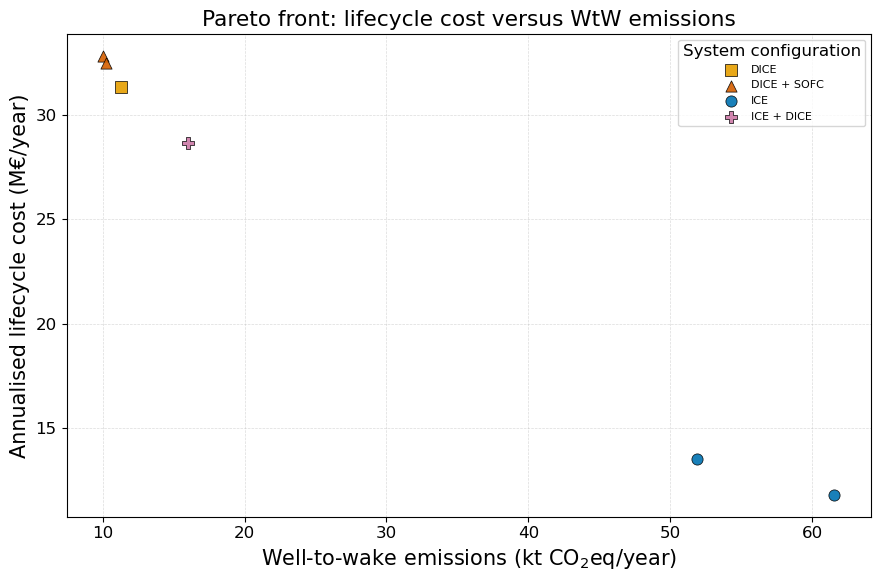

LaTeX table generated:
C:\Users\vicbol\OneDrive - Ab Yrkeshogskolan vid Abo Akademi\8. Working and final papers\3. Submitted and on final stage of preparation\MOSES special issue paper\pareto_results_table.tex

LaTeX output:
\begin{table*}[t]
\centering
\caption{Performance and characteristics of the Pareto-optimal energy-system configurations.}
\label{tab:pareto_results}
\footnotesize
\setlength{\tabcolsep}{5pt}
\renewcommand{\arraystretch}{1.5}
\begin{tabularx}{\textwidth}{
@{}
>{\centering\arraybackslash}m{0.045\textwidth}
>{\centering\arraybackslash}m{0.105\textwidth}
>{\centering\arraybackslash}m{0.085\textwidth}
>{\centering\arraybackslash}m{0.105\textwidth}
>{\raggedright\arraybackslash}m{0.105\textwidth}
>{\raggedright\arraybackslash}m{0.145\textwidth}
>{\raggedright\arraybackslash}X
@{}
}
\toprule
& \multicolumn{3}{c}{\textbf{Performance indicators}}
& \multicolumn{2}{c}{\textbf{Fuel profile}}
& \textbf{Energy system} \\
\cmidrule(lr){2-4}
\cmidrule(lr){5-6}
\cmidrule(lr){7-7}

In [170]:

# ================================================================
# COMPLETE PARETO FIGURE + COMBINED LATEX TABLE
# Requires: tax_df DataFrame from your optimisation analysis
# ================================================================

import ast
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ----------------------- USER SETTINGS ---------------------------

OUTPUT_DIR = Path(".")
FIGURE_NAME = "pareto_front.png"
LATEX_NAME = "pareto_results_table.tex"

# Original data units assumed:
# true_lcc_cost: €/year
# emissions: kg CO2eq/year
# carbontax: €/kg CO2eq
# fuel_quantities: kg/year

ANNOTATE_POINTS = False
FIGSIZE = (9, 6)
DPI = 400

# Conversion factors
LCC_DIVISOR = 1e6
EMISSIONS_DIVISOR = 1e6
FUEL_DIVISOR = 1e6

# ----------------------- VALIDATION ------------------------------

if "tax_df" not in globals():
    raise NameError(
        "tax_df does not exist. Run the optimisation/data preparation "
        "cell first, then run this cell."
    )

required_columns = [
    "carbontax", "true_lcc_cost", "emissions",
    "selected_fuels", "fuel_quantities",
    "ICE_units", "ICE_sizes",
    "DICE_units", "DICE_sizes",
    "MICE_units", "MICE_sizes",
    "PEMFC_units", "PEMFC_unit_size_kw",
    "SOFC_units", "SOFC_unit_size_kw"
]

missing = [c for c in required_columns if c not in tax_df.columns]

if missing:
    raise KeyError(f"Missing columns in tax_df: {missing}")

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

df = tax_df.copy()

for col in ["carbontax", "true_lcc_cost", "emissions"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df = df.dropna(subset=["true_lcc_cost", "emissions"]).copy()

if df.empty:
    raise ValueError("No valid numerical LCC/emissions data found.")

# ----------------------- HELPERS ---------------------------------

def safe_float(value, default=0):
    if value is None:
        return default
    try:
        if pd.isna(value):
            return default
    except (ValueError, TypeError):
        pass
    try:
        return float(value)
    except (ValueError, TypeError):
        return default


def is_missing(value):
    if value is None:
        return True
    if isinstance(value, (dict, list, tuple, np.ndarray)):
        return False
    try:
        return bool(pd.isna(value))
    except (ValueError, TypeError):
        return False


def latex_escape(value):
    replacements = {
        "\\": r"\textbackslash{}",
        "&": r"\&",
        "%": r"\%",
        "$": r"\$",
        "#": r"\#",
        "_": r"\_",
        "{": r"\{",
        "}": r"\}",
        "~": r"\textasciitilde{}",
        "^": r"\textasciicircum{}",
    }
    return "".join(replacements.get(c, c) for c in str(value))


def fmt(value, decimals=2):
    number = safe_float(value, np.nan)
    if not np.isfinite(number):
        return "—"
    return f"{number:,.{decimals}f}"


# ---------------- TECHNOLOGY CLASSIFICATION ---------------------

def classify_technology(row):
    technologies = []

    for col, label in [
        ("ICE_units", "ICE"),
        ("DICE_units", "DICE"),
        ("MICE_units", "MICE"),
        ("PEMFC_units", "PEMFC"),
        ("SOFC_units", "SOFC")
    ]:
        if safe_float(row[col]) > 0:
            technologies.append(label)

    return " + ".join(technologies) if technologies else "No machinery"


df["technology"] = df.apply(classify_technology, axis=1)

# Use the existing TECH_STYLE dictionary if available.
# Otherwise, generate a default mapping.
if "TECH_STYLE" not in globals():
    labels = sorted(df["technology"].unique())
    markers = ["o", "s", "^", "D", "v", "P", "X", "<", ">", "*", "h"]
    colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]

    TECH_STYLE = {
        label: {
            "marker": markers[i % len(markers)],
            "color": colors[i % len(colors)]
        }
        for i, label in enumerate(labels)
    }

# Ensure every observed configuration has a style.
markers = ["o", "s", "^", "D", "v", "P", "X", "<", ">", "*", "h"]
colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]

for i, label in enumerate(sorted(df["technology"].unique())):
    if label not in TECH_STYLE:
        TECH_STYLE[label] = {
            "marker": markers[i % len(markers)],
            "color": colors[i % len(colors)]
        }


def get_style(label):
    style = TECH_STYLE[label]

    if isinstance(style, dict):
        return style.get("marker", "o"), style.get("color", "C0")

    if isinstance(style, (tuple, list)) and len(style) >= 2:
        return style[0], style[1]

    return "o", "C0"


# ----------------------- PARETO FIGURE ---------------------------

fig, ax = plt.subplots(figsize=FIGSIZE)

for technology in sorted(df["technology"].unique()):
    subset = df[df["technology"] == technology]
    marker, color = get_style(technology)

    ax.scatter(
        subset["emissions"] / EMISSIONS_DIVISOR,
        subset["true_lcc_cost"] / LCC_DIVISOR,
        marker=marker,
        color=color,
        s=65,
        edgecolors="black",
        linewidths=0.55,
        alpha=0.9,
        label=technology,
        zorder=3
    )

if ANNOTATE_POINTS and "sweep_index" in df.columns:
    for _, row in df.iterrows():
        ax.annotate(
            str(row["sweep_index"]),
            (
                row["emissions"] / EMISSIONS_DIVISOR,
                row["true_lcc_cost"] / LCC_DIVISOR
            ),
            xytext=(4, 4),
            textcoords="offset points",
            fontsize=7
        )

ax.set_xlabel(r"Well-to-wake emissions (kt CO$_2$eq/year)")
ax.set_ylabel("Annualised lifecycle cost (M€/year)")
ax.set_title("Pareto front: lifecycle cost versus WtW emissions")

ax.grid(True, linestyle="--", linewidth=0.5, alpha=0.45)
ax.legend(title="System configuration", fontsize=8)
fig.tight_layout()

figure_path = OUTPUT_DIR / FIGURE_NAME
fig.savefig(figure_path, dpi=DPI, bbox_inches="tight")
plt.show()
plt.close(fig)

# ----------------------- FUEL FORMATTING -------------------------

def format_fuel_quantities(value):
    """
    Convert fuel quantities from kg/year to kt/year.

    Handles dictionaries, lists of pairs, lists of dictionaries,
    Python dictionary/list strings, and common 'fuel: quantity' strings.
    """

    if is_missing(value):
        return "—"

    parsed = value

    if isinstance(value, str):
        try:
            parsed = ast.literal_eval(value.strip())
        except (ValueError, SyntaxError):
            parsed = None

    entries = []

    if isinstance(parsed, dict):
        entries = list(parsed.items())

    elif isinstance(parsed, (list, tuple)):
        for item in parsed:
            if isinstance(item, dict):
                fuel = item.get("fuel", item.get("name", item.get("type")))
                quantity = item.get(
                    "quantity",
                    item.get("value", item.get("consumption"))
                )
                if fuel is not None and quantity is not None:
                    entries.append((fuel, quantity))

            elif isinstance(item, (list, tuple)) and len(item) >= 2:
                entries.append((item[0], item[1]))

    elif isinstance(value, str):
        # Example: MGO: 123456, LNG: 456789
        pattern = re.compile(
            r"([A-Za-z][A-Za-z0-9 _+./()-]*?)\s*[:=]\s*"
            r"([-+]?\d[\d,]*(?:\.\d+)?)"
        )

        matches = pattern.findall(value)

        if matches:
            entries = [
                (name.strip(), quantity.replace(",", ""))
                for name, quantity in matches
            ]
        else:
            print(
                "WARNING: Fuel quantity string could not be parsed. "
                "Check this row before interpreting its units:\n",
                value
            )
            return latex_escape(value)

    else:
        number = safe_float(value, np.nan)
        if np.isfinite(number):
            return f"{number / FUEL_DIVISOR:.3f}"
        return latex_escape(value)

    if not entries:
        return "—"

    formatted = []

    for fuel, quantity in entries:
        number = safe_float(quantity, np.nan)

        if np.isfinite(number):
            formatted.append(
                f"{latex_escape(fuel)}: {number / FUEL_DIVISOR:.3f}"
            )
        else:
            formatted.append(
                f"{latex_escape(fuel)}: {latex_escape(quantity)}"
            )

    return "; ".join(formatted)


# ---------------- SYSTEM CONFIGURATION --------------------------

def format_size(value):
    if is_missing(value):
        return None

    if isinstance(value, np.ndarray):
        value = value.tolist()

    if isinstance(value, (list, tuple)):
        values = [format_size(v) for v in value]
        values = [v for v in values if v is not None]
        return ", ".join(values) if values else None

    number = safe_float(value, np.nan)

    if np.isfinite(number):
        return fmt(number, 0)

    return str(value)


def machinery_component(row, unit_col, size_col, label):
    units = safe_float(row[unit_col])

    if units <= 0:
        return None

    size = format_size(row[size_col])

    if size:
        return (
            f"{label}: {fmt(units, 0)} units "
            f"({latex_escape(size)} kW)"
        )

    return f"{label}: {fmt(units, 0)} units"


def format_system_configuration(row):
    components = [
        machinery_component(row, "ICE_units", "ICE_sizes", "ICE"),
        machinery_component(row, "DICE_units", "DICE_sizes", "DICE"),
        machinery_component(row, "MICE_units", "MICE_sizes", "MICE"),
        machinery_component(
            row, "PEMFC_units", "PEMFC_unit_size_kw", "PEMFC"
        ),
        machinery_component(
            row, "SOFC_units", "SOFC_unit_size_kw", "SOFC"
        )
    ]

    components = [x for x in components if x]

    return "; ".join(components) if components else "—"


def format_selected_fuels(value):
    if is_missing(value):
        return "—"

    if isinstance(value, (list, tuple, set)):
        return ", ".join(latex_escape(v) for v in value)

    if isinstance(value, dict):
        return ", ".join(latex_escape(k) for k in value.keys())

    return latex_escape(value)



# ================================================================
# PUBLICATION-STYLE LATEX TABLE
# Uses the existing table_df created in the previous code
# ================================================================


# ================================================================
# LATEX TABLE — MATCHING THE USER'S REFERENCE LAYOUT
# Requires the existing table_df DataFrame
# ================================================================

from pathlib import Path
import re

OUTPUT_DIR = Path(".")
LATEX_NAME = "pareto_results_table.tex"


def split_entries(value):
    """Split semicolon-separated entries into individual components."""
    if value is None or str(value).strip() in ("", "—", "nan"):
        return []

    return [
        item.strip()
        for item in str(value).split(";")
        if item.strip()
    ]


def make_cell(value, max_chars=None):
    """
    Create a multiline LaTeX cell.
    Long entries are wrapped at sensible word boundaries.
    """

    if value is None or str(value).strip() in ("", "—", "nan"):
        return "--"

    text = str(value).strip()

    if max_chars is not None and len(text) > max_chars:
        words = text.split()
        lines = []
        current = ""

        for word in words:
            candidate = (current + " " + word).strip()

            if len(candidate) > max_chars and current:
                lines.append(current)
                current = word
            else:
                current = candidate

        if current:
            lines.append(current)

        text = r"\\ ".join(lines)

    return text


def fuel_cell(value):
    """One fuel per line."""
    entries = split_entries(value)

    if not entries:
        return "--"

    return r"\makecell[l]{" + r" \\ ".join(
        make_cell(entry, 23) for entry in entries
    ) + "}"


def selected_fuels_cell(value):
    """Display selected fuels on separate lines when appropriate."""
    if value is None or str(value).strip() in ("", "—", "nan"):
        return "--"

    text = str(value).strip()

    if isinstance(value, (list, tuple, set)):
        entries = [str(x).strip() for x in value]
    else:
        entries = [
            x.strip() for x in re.split(r",\s*|;\s*", text)
            if x.strip()
        ]

    if len(entries) > 1:
        return r"\makecell[l]{" + r" \\ ".join(entries) + "}"

    return entries[0]


def configuration_cell(value):
    """
    One machinery component per line.
    Long machinery descriptions are wrapped where possible.
    """
    entries = split_entries(value)

    if not entries:
        return "--"

    return r"\makecell[l]{" + r" \\ ".join(
        make_cell(entry, 34) for entry in entries
    ) + "}"


# ---------------- LATEX TABLE STRUCTURE --------------------------

latex_lines = [
    r"\begin{table*}[t]",
    r"\centering",
    r"\caption{Performance and characteristics of the Pareto-optimal "
    r"energy-system configurations.}",
    r"\label{tab:pareto_results}",

    r"\footnotesize",
    r"\setlength{\tabcolsep}{5pt}",
    r"\renewcommand{\arraystretch}{1.5}",

    r"\begin{tabularx}{\textwidth}{",
    r"@{}",
    r">{\centering\arraybackslash}m{0.045\textwidth}",
    r">{\centering\arraybackslash}m{0.105\textwidth}",
    r">{\centering\arraybackslash}m{0.085\textwidth}",
    r">{\centering\arraybackslash}m{0.105\textwidth}",
    r">{\raggedright\arraybackslash}m{0.105\textwidth}",
    r">{\raggedright\arraybackslash}m{0.145\textwidth}",
    r">{\raggedright\arraybackslash}X",
    r"@{}",
    r"}",

    r"\toprule",

    r"& \multicolumn{3}{c}{\textbf{Performance indicators}}",
    r"& \multicolumn{2}{c}{\textbf{Fuel profile}}",
    r"& \textbf{Energy system} \\",

    r"\cmidrule(lr){2-4}",
    r"\cmidrule(lr){5-6}",
    r"\cmidrule(lr){7-7}",

    r"\textbf{Sol.}",
    r"& \makecell[c]{\textbf{Carbon tax}\\(€/kg CO$_2$eq)}",
    r"& \makecell[c]{\textbf{LCC}\\(M€/year)}",
    r"& \makecell[c]{\textbf{WtW emissions}\\(kt CO$_2$eq/year)}",
    r"& \textbf{Selected fuels}",
    r"& \makecell[l]{\textbf{Consumption}\\(kt/year)}",
    r"& \makecell[l]{\textbf{Installed capacity}\\(kW)} \\",

    r"\midrule"
]

# ---------------- ADD DATA ROWS ----------------------------------

for _, row in table_df.iterrows():

    solution = str(row["Solution"])
    carbon_tax = str(row["Carbon tax"])
    lcc = str(row["LCC"])
    emissions = str(row["WtW emissions"])

    fuels = selected_fuels_cell(row["Selected fuels"])
    consumption = fuel_cell(row["Fuel consumption"])
    configuration = configuration_cell(
        row["System configuration"]
    )

    latex_lines.append(
        f"{solution} & "
        f"{carbon_tax} & "
        f"{lcc} & "
        f"{emissions} & "
        f"{fuels} & "
        f"{consumption} & "
        f"{configuration} \\\\"
    )

# ---------------- CLOSE TABLE ------------------------------------

latex_lines.extend([
    r"\bottomrule",
    r"\end{tabularx}",
    r"\end{table*}"
])

latex_content = "\n".join(latex_lines)

latex_path = OUTPUT_DIR / LATEX_NAME
latex_path.write_text(latex_content, encoding="utf-8")

print("LaTeX table generated:")
print(latex_path.resolve())

print("\nLaTeX output:")
print(latex_content)



## Restricted Pathway Analysis

In [56]:

# =========================================================
# TABLE B - FUEL-TECHNOLOGY PATHWAY DEFINITIONS
# Reviewer M7
# =========================================================

restricted_pathways = [

    # -----------------------------------------------------
    # Methanol / MICE
    # -----------------------------------------------------
    {
        "pathway": "Methanol / MICE",
        "fuel_edge": ("MOH", "MOHconv"),
        "internal_edge": ("MOH_LHV", "fuel_MICE"),
        "technology_prefix": "engine_MICE_",
        "lhv_mj_kg": LHV_MOH,
        "exclude_fuel_edges": []
    },

    # -----------------------------------------------------
    # LNG and bioLNG / DICE
    # -----------------------------------------------------
    {
        "pathway": "LNG / DICE",
        "fuel_edge": ("LNG", "LNGconv_DICE"),
        "internal_edge": ("LNG_DICE_LHV", "gas_LHV"),
        "technology_prefix": "engine_DICE_",
        "lhv_mj_kg": LHV_LNG,
        "exclude_fuel_edges": [
            ("bioLNG", "bioLNGconv_DICE")
        ]
    },
    {
        "pathway": "bioLNG / DICE",
        "fuel_edge": ("bioLNG", "bioLNGconv_DICE"),
        "internal_edge": ("bioLNG_DICE_LHV", "gas_LHV"),
        "technology_prefix": "engine_DICE_",
        "lhv_mj_kg": LHV_LNG,
        "exclude_fuel_edges": [
            ("LNG", "LNGconv_DICE")
        ]
    },

    # -----------------------------------------------------
    # LNG and bioLNG / SOFC
    # -----------------------------------------------------
    {
        "pathway": "LNG / SOFC",
        "fuel_edge": ("LNG", "LNGconv_SOFC"),
        "internal_edge": ("LNG_SOFC_LHV", "SOFC_LHV"),
        "technology_node": "SOFC_1",
        "lhv_mj_kg": LHV_LNG,
        "exclude_fuel_edges": [
            ("bioLNG", "bioLNGconv_SOFC")
        ]
    },
    {
        "pathway": "bioLNG / SOFC",
        "fuel_edge": ("bioLNG", "bioLNGconv_SOFC"),
        "internal_edge": ("bioLNG_SOFC_LHV", "SOFC_LHV"),
        "technology_node": "SOFC_1",
        "lhv_mj_kg": LHV_LNG,
        "exclude_fuel_edges": [
            ("LNG", "LNGconv_SOFC")
        ]
    },

    # -----------------------------------------------------
    # LH2 and reLH2 / PEMFC
    # -----------------------------------------------------
    {
        "pathway": "LH2 / PEMFC",
        "fuel_edge": ("LH2", "LH2conv_PEMFC"),
        "internal_edge": ("LH2_PEMFC_LHV", "PEMFC_LHV"),
        "technology_node": "PEMFC_1",
        "lhv_mj_kg": LHV_LH2,
        "exclude_fuel_edges": [
            ("reLH2", "reLH2conv_PEMFC")
        ]
    },
    {
        "pathway": "reLH2 / PEMFC",
        "fuel_edge": ("reLH2", "reLH2conv_PEMFC"),
        "internal_edge": ("reLH2_PEMFC_LHV", "PEMFC_LHV"),
        "technology_node": "PEMFC_1",
        "lhv_mj_kg": LHV_LH2,
        "exclude_fuel_edges": [
            ("LH2", "LH2conv_PEMFC")
        ]
    },

    # -----------------------------------------------------
    # LH2 and reLH2 / SOFC
    # -----------------------------------------------------
    {
        "pathway": "LH2 / SOFC",
        "fuel_edge": ("LH2", "LH2conv_SOFC"),
        "internal_edge": ("LH2_SOFC_LHV", "SOFC_LHV"),
        "technology_node": "SOFC_1",
        "lhv_mj_kg": LHV_LH2,
        "exclude_fuel_edges": [
            ("reLH2", "reLH2conv_SOFC")
        ]
    },
    {
        "pathway": "reLH2 / SOFC",
        "fuel_edge": ("reLH2", "reLH2conv_SOFC"),
        "internal_edge": ("reLH2_SOFC_LHV", "SOFC_LHV"),
        "technology_node": "SOFC_1",
        "lhv_mj_kg": LHV_LH2,
        "exclude_fuel_edges": [
            ("LH2", "LH2conv_SOFC")
        ]
    },

    # -----------------------------------------------------
    # NH3 and reNH3 / SOFC
    # -----------------------------------------------------
    {
        "pathway": "NH3 / SOFC",
        "fuel_edge": ("NH3", "NH3conv"),
        "internal_edge": ("NH3_LHV", "SOFC_LHV"),
        "technology_node": "SOFC_1",
        "lhv_mj_kg": LHV_NH3,
        "exclude_fuel_edges": [
            ("reNH3", "reNH3conv")
        ]
    },
    {
        "pathway": "reNH3 / SOFC",
        "fuel_edge": ("reNH3", "reNH3conv"),
        "internal_edge": ("NH3_LHV", "SOFC_LHV"),
        "technology_node": "SOFC_1",
        "lhv_mj_kg": LHV_NH3,
        "exclude_fuel_edges": [
            ("NH3", "NH3conv")
        ]
    }
]

print(f"Defined {len(restricted_pathways)} fuel-technology pathways.")


Defined 11 fuel-technology pathways.


In [57]:

# =============================================================================
# CELL — FUEL EXTRACTION AND TECHNOLOGY ATTRIBUTION HELPERS
# Based on the actual edges defined in shipmodel()
# =============================================================================

import numpy as np
import pandas as pd


def _edge_annual_value(post_edges, source, target, tol=1e-6):
    """
    Extract annual flow [kg/year] from a fuel-source -> converter edge.

    The edge values are summed across operational scenarios.
    """

    mask = (
        (post_edges["source"] == source) &
        (post_edges["target"] == target)
    )

    if not mask.any():
        return 0.0

    total_quantity = 0.0

    for values in post_edges.loc[mask, "value"]:

        if isinstance(
            values,
            (list, tuple, np.ndarray, pd.Series)
        ):
            quantity = float(
                np.nansum(np.asarray(values, dtype=float))
            )

        elif pd.notna(values):
            quantity = float(values)

        else:
            quantity = 0.0

        total_quantity += quantity

    return total_quantity if total_quantity > tol else 0.0


def extract_fuel_mix_by_technology(post_edges, tol=1e-6):
    """
    Extract annual fuel consumption [kg/year] by technology.

    Fuel attribution is based on the actual fuel-source -> converter
    edges in shipmodel().

    Technologies:
        DICE
        MICE
        PEMFC
        SOFC
        Boiler

    Important:
        VLSFO and MGO are not allocated individually to ICE or Boiler.
        Their energy flows merge through FO_LHV / GO_LHV before reaching
        downstream consumers. The current graph therefore does not
        preserve their final technology-specific allocation.
    """

    # Exact fuel-source -> converter edges from shipmodel().
    technology_fuel_edges = {

        "DICE": {
            "LNG": ("LNG", "LNGconv_DICE"),
            "bioLNG": ("bioLNG", "bioLNGconv_DICE"),
        },

        "MICE": {
            "Methanol": ("MOH", "MOHconv"),
        },

        "PEMFC": {
            "LH2": ("LH2", "LH2conv_PEMFC"),
            "reLH2": ("reLH2", "reLH2conv_PEMFC"),
        },

        "SOFC": {
            "LNG": ("LNG", "LNGconv_SOFC"),
            "bioLNG": ("bioLNG", "bioLNGconv_SOFC"),
            "LH2": ("LH2", "LH2conv_SOFC"),
            "reLH2": ("reLH2", "reLH2conv_SOFC"),
            "NH3": ("NH3", "NH3conv"),
            "reNH3": ("reNH3", "reNH3conv"),
        },

        "Boiler": {
            "LNG": ("LNG", "LNGconv_boiler"),
            "bioLNG": ("bioLNG", "bioLNGconv_boiler"),
        },
    }

    fuel_mix = {}

    for technology, fuel_edges in technology_fuel_edges.items():

        technology_mix = {}

        for fuel, (source, target) in fuel_edges.items():

            quantity = _edge_annual_value(
                post_edges=post_edges,
                source=source,
                target=target,
                tol=tol
            )

            if quantity > tol:
                technology_mix[fuel] = quantity

        fuel_mix[technology] = technology_mix

    return fuel_mix


print("Fuel extraction helper functions defined successfully.")


Fuel extraction helper functions defined successfully.


In [58]:
# =========================================================
# EXCLUSIVE PATHWAY ANALYSIS - OPTION A
# Reviewer M7 analysis
# =========================================================

import pandas as pd
import numpy as np

exclusive_baseline_results = {}
exclusive_results = []

tax_levels_exclusive = [0.0, 0.073, 0.150]

# ---------------------------------------------------------
# 1. Unrestricted baselines
# ---------------------------------------------------------

for tax in tax_levels_exclusive:

    print(f"\nBaseline optimisation: tax = {tax:.3f}")

    baseline = solve_one_case_for_pareto(
        df=df,
        carbontax=tax,
        emissions_cap=None,
        forced_pathway=None,
        exclusive_pathway=False
    )

    exclusive_baseline_results[tax] = baseline


# ---------------------------------------------------------
# 2. Exclusive pathway runs
# ---------------------------------------------------------

for tax in tax_levels_exclusive:

    baseline = exclusive_baseline_results[tax]

    Z_base = float(baseline["cost"])
    E_base = float(baseline["emissions"])

    LCC_base = (
        Z_base
    )

    print("\n" + "=" * 90)
    print(f"EXCLUSIVE PATHWAY ANALYSIS: TAX = {tax:.3f}")
    print("=" * 90)

    for pathway in restricted_pathways:

        print(f"\nRunning exclusive pathway: {pathway['pathway']}")

        try:

            result = solve_one_case_for_pareto(
                df=df,
                carbontax=tax,
                emissions_cap=None,
                forced_pathway=pathway,
                min_pathway_share=0.01,
                exclusive_pathway=True
            )

            Z = float(result["cost"])
            E = float(result["emissions"])

            LCC = Z 

            objective_gap = Z - Z_base

            objective_gap_pct = (
                100 * objective_gap / abs(Z_base)
                if abs(Z_base) > 1e-12 else np.nan
            )

            emissions_change_pct = (
                100 * (E - E_base) / abs(E_base)
                if abs(E_base) > 1e-12 else np.nan
            )

            fuel_mix = extract_selected_fuels(
                result["post_edges"]
            )

            technology_mix = extract_fuel_mix_by_technology(
                result["post_edges"]
            )

            exclusive_results.append({

                "Carbon tax [EUR/kgCO2eq]": tax,

                "Pathway": pathway["pathway"],

                "Baseline objective [EUR/year]": Z_base,

                "Exclusive objective [EUR/year]": Z,

                "Objective gap [EUR/year]": objective_gap,

                "Objective gap [%]": objective_gap_pct,

                "Baseline LCC [EUR/year]": LCC_base,

                "Exclusive LCC [EUR/year]": LCC,

                "LCC gap [%]": (
                    100 * (LCC - LCC_base) / abs(LCC_base)
                    if abs(LCC_base) > 1e-12 else np.nan
                ),

                "Baseline emissions [kgCO2eq/year]": E_base,

                "Exclusive emissions [kgCO2eq/year]": E,

                "Emissions change [%]": emissions_change_pct,

                "Solver status": result["solver_status"],

                "MIP gap": result["mip_gap"],

                "Fuel mix": fuel_mix,

                "Fuel mix by technology": technology_mix,

                "Result": result
            })

            print(f"  Objective: {Z:,.2f} EUR/year")
            print(f"  LCC:       {LCC:,.2f} EUR/year")
            print(f"  Emissions: {E:,.2f} kgCO2eq/year")
            print(f"  Gap:       {objective_gap_pct:.2f}%")
            print(f"  Solver:    {result['solver_status']}")
            print(f"  MIP gap:   {result['mip_gap']:.5f}")

        except Exception as exc:

            print(
                f"  FAILED: {pathway['pathway']} | {exc}"
            )

            exclusive_results.append({

                "Carbon tax [EUR/kgCO2eq]": tax,

                "Pathway": pathway["pathway"],

                "Solver status": "Failed",

                "Error": str(exc)
            })


# ---------------------------------------------------------
# 3. Create results table
# ---------------------------------------------------------

exclusive_table = pd.DataFrame(exclusive_results)

display(
    exclusive_table.drop(
        columns=["Result", "Fuel mix by technology"],
        errors="ignore"
    )
)

print("\nNumber of exclusive pathway cases:", len(exclusive_results))


Baseline optimisation: tax = 0.000
[optigraph] start build, scenarios=4
[optigraph] building scenario 1/4
[optigraph] scenario 1: edge vars created
[optigraph] scenario 1: node constraints created
[optigraph] building scenario 2/4
[optigraph] scenario 2: edge vars created
[optigraph] scenario 2: node constraints created
[optigraph] building scenario 3/4
[optigraph] scenario 3: edge vars created
[optigraph] scenario 3: node constraints created
[optigraph] building scenario 4/4
[optigraph] scenario 4: edge vars created
[optigraph] scenario 4: node constraints created
[optigraph] model built: vars=9077, constrs=7684
OptimizationStatus.OPTIMAL 11821364.758155301
[optigraph] solver finished

Baseline optimisation: tax = 0.073
[optigraph] start build, scenarios=4
[optigraph] building scenario 1/4
[optigraph] scenario 1: edge vars created
[optigraph] scenario 1: node constraints created
[optigraph] building scenario 2/4
[optigraph] scenario 2: edge vars created
[optigraph] scenario 2: node c

,Carbon tax [EUR/kgCO2eq],Pathway,Baseline objective [EUR/year],Exclusive objective [EUR/year],Objective gap [EUR/year],Objective gap [%],Baseline LCC [EUR/year],Exclusive LCC [EUR/year],LCC gap [%],Baseline emissions [kgCO2eq/year],Exclusive emissions [kgCO2eq/year],Emissions change [%],Solver status,MIP gap,Fuel mix
0,0.000,Methanol / MICE,1.182136e+07,2.105835e+07,9.236982e+06,78.138031,1.182136e+07,2.105835e+07,78.138031,61580000.0,67810000.0,10.116921,OptimizationStatus.OPTIMAL,0.000000e+00,"{'VLSFO': {'by_scenario': [443400.0, 1103000.0..."
1,0.000,LNG / DICE,1.182136e+07,1.865677e+07,6.835405e+06,57.822472,1.182136e+07,1.865677e+07,57.822472,61580000.0,60250000.0,-2.159792,OptimizationStatus.OPTIMAL,0.000000e+00,"{'VLSFO': {'by_scenario': [538400.0, 925500.0,..."
2,0.000,bioLNG / DICE,1.182136e+07,2.934350e+07,1.752214e+07,148.224309,1.182136e+07,2.934350e+07,148.224309,61580000.0,23703000.0,-61.508607,OptimizationStatus.OPTIMAL,1.269545e-16,"{'VLSFO': {'by_scenario': [535400.0, 1103000.0..."
3,0.000,LNG / SOFC,1.182136e+07,3.136356e+07,1.954220e+07,165.312517,1.182136e+07,3.136356e+07,165.312517,61580000.0,61490000.0,-0.146151,OptimizationStatus.OPTIMAL,0.000000e+00,"{'VLSFO': {'by_scenario': [670900.0, 1103000.0..."
4,0.000,bioLNG / SOFC,1.182136e+07,4.169851e+07,2.987715e+07,252.738579,1.182136e+07,4.169851e+07,252.738579,61580000.0,26196000.0,-57.460214,OptimizationStatus.OPTIMAL,0.000000e+00,"{'VLSFO': {'by_scenario': [670900.0, 1103000.0..."
5,0.000,LH2 / PEMFC,1.182136e+07,3.400878e+07,2.218741e+07,187.689096,1.182136e+07,3.400878e+07,187.689096,61580000.0,90690000.0,47.271842,OptimizationStatus.OPTIMAL,0.000000e+00,"{'VLSFO': {'by_scenario': [670900.0, 1103000.0..."
6,0.000,reLH2 / PEMFC,1.182136e+07,4.936251e+07,3.754114e+07,317.570277,1.182136e+07,4.936251e+07,317.570277,61580000.0,31219000.0,-49.303345,OptimizationStatus.OPTIMAL,0.000000e+00,"{'VLSFO': {'by_scenario': [670900.0, 1103000.0..."
7,0.000,LH2 / SOFC,1.182136e+07,3.647544e+07,2.465408e+07,208.555254,1.182136e+07,3.647544e+07,208.555254,61580000.0,79870000.0,29.701202,OptimizationStatus.OPTIMAL,0.000000e+00,"{'VLSFO': {'by_scenario': [670900.0, 1103000.0..."
8,0.000,reLH2 / SOFC,1.182136e+07,4.946167e+07,3.764030e+07,318.409097,1.182136e+07,4.946167e+07,318.409097,61580000.0,29582000.0,-51.961676,OptimizationStatus.OPTIMAL,0.000000e+00,"{'VLSFO': {'by_scenario': [670900.0, 1103000.0..."
9,0.000,NH3 / SOFC,1.182136e+07,3.067468e+07,1.885331e+07,159.485093,1.182136e+07,3.067468e+07,159.485093,61580000.0,74940000.0,21.695356,OptimizationStatus.OPTIMAL,0.000000e+00,"{'VLSFO': {'by_scenario': [670900.0, 1103000.0..."



Number of exclusive pathway cases: 33


In [59]:

# ============================================================
# CELL - AUTOMATIC EXCLUSIVE PATHWAY COMPARISON TABLE
# Complete version with explicit units and appropriate scales
# ============================================================

import pandas as pd
import numpy as np
from collections import Counter

# ------------------------------------------------------------
# 1. Configuration extraction
# ------------------------------------------------------------

def format_exclusive_configuration(result):

    components = []

    # Conventional engines
    for family in ["ICE", "DICE", "MICE"]:

        n_units = int(result.get(f"{family}_units", 0) or 0)
        sizes = result.get(f"{family}_sizes", []) or []

        if n_units > 0 and len(sizes) > 0:

            counts = Counter(
                round(float(s) / 1000, 2)
                for s in sizes
            )

            description = " + ".join(
                f"{n}x{size:g} MW"
                for size, n in sorted(
                    counts.items(), reverse=True
                )
            )

            components.append(f"{family}: {description}")

    # Fuel cells
    for family in ["PEMFC", "SOFC"]:

        n_units = int(result.get(f"{family}_units", 0) or 0)

        if n_units > 0:

            unit_size = (
                float(result.get(f"{family}_unit_size_kw", 0))
                / 1000
            )

            components.append(
                f"{family}: {n_units}x{unit_size:g} MW"
            )

    if not components:
        return "No machinery identified"

    return " | ".join(components)


# ------------------------------------------------------------
# 2. Define output metrics
# ------------------------------------------------------------

metrics = [
    "Emissions change",
    "Objective gap",
    "Objective gap (%)",
    "LCC change",
    "LCC change (%)",
    "Power plant configuration",
    "Total installed capacity",
    "N-1 feasible",
    "Solver status",
    "MIP gap"
]

tax_levels = sorted(tax_levels_exclusive)


# ------------------------------------------------------------
# 3. Extract results for each pathway and carbon tax
# ------------------------------------------------------------

wide_rows = []

for pathway_definition in restricted_pathways:

    pathway_name = pathway_definition["pathway"]

    output_row = {"Pathway": pathway_name}

    for tax in tax_levels:

        # Find corresponding optimisation result
        matching = [
            r for r in exclusive_results
            if r.get("Pathway") == pathway_name
            and np.isclose(
                r.get("Carbon tax [EUR/kgCO2eq]", np.nan),
                tax
            )
        ]

        if not matching:

            for metric in metrics:
                output_row[(tax, metric)] = np.nan

            continue

        row = matching[0]
        result = row.get("Result")

        if not isinstance(result, dict):

            for metric in metrics:
                output_row[(tax, metric)] = np.nan

            continue

        # ----------------------------------------------------
        # 3.1 WtW emissions change
        # Negative = reduction
        # Positive = increase
        # Original unit: kg CO2eq/year
        # ----------------------------------------------------

        baseline_emissions = float(
            row["Baseline emissions [kgCO2eq/year]"]
        )

        exclusive_emissions = float(
            row["Exclusive emissions [kgCO2eq/year]"]
        )

        emissions_change_kg = (
            exclusive_emissions - baseline_emissions
        )

        # Convert kg to tonnes
        emissions_change_t = emissions_change_kg / 1000

        emissions_change_pct = (
            100 * emissions_change_kg / abs(baseline_emissions)
            if abs(baseline_emissions) > 1e-12
            else np.nan
        )

        # ----------------------------------------------------
        # 3.2 Objective gap
        # Positive = restricted pathway has higher objective
        # ----------------------------------------------------

        objective_gap = float(
            row["Objective gap [EUR/year]"]
        )

        objective_gap_pct = float(
            row["Objective gap [%]"]
        )

        # ----------------------------------------------------
        # 3.3 Annualised LCC change
        # Positive = more expensive
        # Negative = cost saving
        # Original unit: EUR/year
        # ----------------------------------------------------

        baseline_lcc = float(
            row["Baseline LCC [EUR/year]"]
        )

        exclusive_lcc = float(
            row["Exclusive LCC [EUR/year]"]
        )

        lcc_change_eur = (
            exclusive_lcc - baseline_lcc
        )

        # Convert EUR to million EUR
        lcc_change_meur = lcc_change_eur / 1e6

        lcc_change_pct = (
            100 * lcc_change_eur / abs(baseline_lcc)
            if abs(baseline_lcc) > 1e-12
            else np.nan
        )

        # ----------------------------------------------------
        # 3.4 Machinery configuration
        # ----------------------------------------------------

        configuration = format_exclusive_configuration(
            result
        )

        total_capacity = (
            float(result.get("P_sup_kW", np.nan)) / 1000
        )

        n1_feasible = result.get(
            "N1_feasible", np.nan
        )

        solver_status = row.get(
            "Solver status", "Unknown"
        )

        mip_gap = row.get("MIP gap", np.nan)

        # ----------------------------------------------------
        # 3.5 Save formatted results
        # ----------------------------------------------------

        output_row[(tax, "Emissions change")] = (
            f"{emissions_change_t:+,.0f} "
            f"({emissions_change_pct:+.1f}%)"
        )

        output_row[(tax, "Objective gap")] = (
            f"{objective_gap / 1e6:+.3f} M€/year"
        )

        output_row[(tax, "Objective gap (%)")] = (
            f"{objective_gap_pct:+.2f}%"
        )

        output_row[(tax, "LCC change")] = (
            f"{lcc_change_meur:+.3f} "
            f"({lcc_change_pct:+.1f}%)"
        )

        output_row[(tax, "LCC change (%)")] = (
            f"{lcc_change_pct:+.2f}%"
        )

        output_row[(tax, "Power plant configuration")] = (
            configuration
        )

        output_row[(tax, "Total installed capacity")] = (
            f"{total_capacity:.2f} MW"
            if pd.notna(total_capacity) else "--"
        )

        output_row[(tax, "N-1 feasible")] = n1_feasible

        output_row[(tax, "Solver status")] = solver_status

        output_row[(tax, "MIP gap")] = mip_gap

    wide_rows.append(output_row)


# ------------------------------------------------------------
# 4. Construct full comparison table
# ------------------------------------------------------------

exclusive_comparison_table = pd.DataFrame(wide_rows)

exclusive_comparison_table = (
    exclusive_comparison_table.set_index("Pathway")
)

column_order = pd.MultiIndex.from_product(
    [tax_levels, metrics],
    names=[
        "Carbon tax [EUR/kgCO2eq]",
        "Metric"
    ]
)

exclusive_comparison_table = (
    exclusive_comparison_table.reindex(
        columns=column_order
    )
)

print("\n" + "=" * 110)
print("EXCLUSIVE FUEL-TECHNOLOGY PATHWAY COMPARISON")
print("=" * 110)

display(exclusive_comparison_table)


# ------------------------------------------------------------
# 5. Create compact manuscript table
# ------------------------------------------------------------

compact_metrics = [
    "Emissions change",
    "LCC change",
    "Power plant configuration"
]

compact_table = exclusive_comparison_table.loc[
    :, pd.IndexSlice[:, compact_metrics]
].copy()


# ------------------------------------------------------------
# 5.1 Rename metric headers and specify units
# ------------------------------------------------------------

metric_labels = {
    "Emissions change":
        "WtW emissions change [t CO2eq/year]",

    "LCC change":
        "Annualised LCC change [M€/year]",

    "Power plant configuration":
        "Installed machinery configuration [MW]"
}

compact_table.columns = pd.MultiIndex.from_tuples(
    [
        (tax, metric_labels[metric])
        for tax, metric in compact_table.columns
    ],
    names=[
        "Carbon tax [€/t CO2eq]",
        "Performance indicator"
    ]
)


# ------------------------------------------------------------
# 5.2 Convert carbon-tax headings
# Original: EUR/kg CO2eq
# New: EUR/t CO2eq
# ------------------------------------------------------------

compact_table.columns = pd.MultiIndex.from_tuples(
    [
        (f"{float(tax) * 1000:g}", metric)
        for tax, metric in compact_table.columns
    ],
    names=[
        "Carbon tax [€/t CO2eq]",
        "Performance indicator"
    ]
)


print("\n" + "=" * 110)
print("COMPACT MANUSCRIPT TABLE")
print("=" * 110)

display(compact_table)


# ------------------------------------------------------------
# 6. Export full and compact tables to Excel
# ------------------------------------------------------------

output_file = "Exclusive_Pathway_Comparison_Automatic.xlsx"

with pd.ExcelWriter(
    output_file,
    engine="openpyxl"
) as writer:

    exclusive_comparison_table.to_excel(
        writer,
        sheet_name="Full_Comparison"
    )

    compact_table.to_excel(
        writer,
        sheet_name="Manuscript_Table"
    )

print(f"\nResults exported to: {output_file}")


# ------------------------------------------------------------
# 7. Export compact table to LaTeX
# ------------------------------------------------------------

latex_table = compact_table.to_latex(
    escape=False,
    multicolumn=True,
    multirow=True,
    index=True,
    column_format="l" + "c" * len(compact_table.columns)
)

with open(
    "Exclusive_Pathway_Comparison.tex",
    "w",
    encoding="utf-8"
) as f:

    f.write(latex_table)

print("LaTeX table exported successfully.")



EXCLUSIVE FUEL-TECHNOLOGY PATHWAY COMPARISON


Carbon tax [EUR/kgCO2eq]              0.00                                     \
Metric                    Emissions change    Objective gap Objective gap (%)   
Pathway                                                                         
Methanol / MICE            +6,230 (+10.1%)   +9.237 M€/year           +78.14%   
LNG / DICE                  -1,330 (-2.2%)   +6.835 M€/year           +57.82%   
bioLNG / DICE             -37,877 (-61.5%)  +17.522 M€/year          +148.22%   
LNG / SOFC                     -90 (-0.1%)  +19.542 M€/year          +165.31%   
bioLNG / SOFC             -35,384 (-57.5%)  +29.877 M€/year          +252.74%   
LH2 / PEMFC               +29,110 (+47.3%)  +22.187 M€/year          +187.69%   
reLH2 / PEMFC             -30,361 (-49.3%)  +37.541 M€/year          +317.57%   
LH2 / SOFC                +18,290 (+29.7%)  +24.654 M€/year          +208.56%   
reLH2 / SOFC              -31,998 (-52.0%)  +37.640 M€/year          +318.41%   
NH3 / SOFC                +13,360 (+21.7%)  +18.853 M€/year          +159.49%   
reNH3 / SOFC              -29,124 (-47.3%)  +22.822 M€/year          +193.06%   

Carbon tax [EUR/kgCO2eq]                                    \
Metric                           LCC change LCC change (%)   
Pathway                                                      
Methanol / MICE             +9.237 (+78.1%)        +78.14%   
LNG / DICE                  +6.835 (+57.8%)        +57.82%   
bioLNG / DICE             +17.522 (+148.2%)       +148.22%   
LNG / SOFC                +19.542 (+165.3%)       +165.31%   
bioLNG / SOFC             +29.877 (+252.7%)       +252.74%   
LH2 / PEMFC               +22.187 (+187.7%)       +187.69%   
reLH2 / PEMFC             +37.541 (+317.6%)       +317.57%   
LH2 / SOFC                +24.654 (+208.6%)       +208.56%   
reLH2 / SOFC              +37.640 (+318.4%)       +318.41%   
NH3 / SOFC                +18.853 (+159.5%)       +159.49%   
reNH3 / SOFC              +22.822 (+193.1%)       +193.06%   

Carbon tax [EUR/kgCO2eq]                                      \
Metric                             Power plant configuration   
Pathway                                                        
Methanol / MICE           MICE: 2x6.5 MW + 2x5 MW + 2x3.5 MW   
LNG / DICE                    DICE: 2x8 MW + 2x5 MW + 2x2 MW   
bioLNG / DICE             DICE: 2x6.5 MW + 2x5 MW + 2x3.5 MW   
LNG / SOFC                                      SOFC: 6x5 MW   
bioLNG / SOFC                                   SOFC: 6x5 MW   
LH2 / PEMFC                                    PEMFC: 6x5 MW   
reLH2 / PEMFC                                  PEMFC: 6x5 MW   
LH2 / SOFC                                      SOFC: 6x5 MW   
reLH2 / SOFC                                    SOFC: 6x5 MW   
NH3 / SOFC                                      SOFC: 6x5 MW   
reNH3 / SOFC                                    SOFC: 6x5 MW   

Carbon tax [EUR/kgCO2eq]                                        \
Metric                   Total installed capacity N-1 feasible   
Pathway                                                          
Methanol / MICE                          30.00 MW         True   
LNG / DICE                               30.00 MW         True   
bioLNG / DICE                            30.00 MW         True   
LNG / SOFC                               30.00 MW         True   
bioLNG / SOFC                            30.00 MW         True   
LH2 / PEMFC                              30.00 MW         True   
reLH2 / PEMFC                            30.00 MW         True   
LH2 / SOFC                               30.00 MW         True   
reLH2 / SOFC                             30.00 MW         True   
NH3 / SOFC                               30.00 MW         True   
reNH3 / SOFC                             30.00 MW         True   

Carbon tax [EUR/kgCO2eq]                                            ...  \
Metric                                 Solver status       MIP gap  ...   
Pathway                 


COMPACT MANUSCRIPT TABLE


Carbon tax [€/t CO2eq],0,73,150,0,73,150,0,73,150
Performance indicator,WtW emissions change [t CO2eq/year],WtW emissions change [t CO2eq/year],WtW emissions change [t CO2eq/year],Annualised LCC change [M€/year],Annualised LCC change [M€/year],Annualised LCC change [M€/year],Installed machinery configuration [MW],Installed machinery configuration [MW],Installed machinery configuration [MW]
Pathway,,,,,,,,,
Methanol / MICE,"+6,230 (+10.1%)","-2,300 (-3.7%)","-2,300 (-3.7%)",+9.237 (+78.1%),+9.366 (+57.4%),+9.189 (+43.6%),MICE: 2x6.5 MW + 2x5 MW + 2x3.5 MW,MICE: 2x6.5 MW + 2x5 MW + 2x3.5 MW,MICE: 2x6.5 MW + 2x5 MW + 2x3.5 MW
LNG / DICE,"-1,330 (-2.2%)","-10,280 (-16.7%)","-10,280 (-16.7%)",+6.835 (+57.8%),+6.492 (+39.8%),+5.700 (+27.1%),DICE: 2x8 MW + 2x5 MW + 2x2 MW,DICE: 2x6.5 MW + 2x5 MW + 2x3.5 MW,DICE: 2x6.5 MW + 2x5 MW + 2x3.5 MW
bioLNG / DICE,"-37,877 (-61.5%)","-46,407 (-75.4%)","-46,407 (-75.4%)",+17.522 (+148.2%),+14.431 (+88.4%),+10.858 (+51.6%),DICE: 2x6.5 MW + 2x5 MW + 2x3.5 MW,DICE: 2x6.5 MW + 2x5 MW + 2x3.5 MW,DICE: 2x6.5 MW + 2x5 MW + 2x3.5 MW
LNG / SOFC,-90 (-0.1%),"-8,620 (-14.0%)","-8,620 (-14.0%)",+19.542 (+165.3%),+19.210 (+117.7%),+18.547 (+88.1%),SOFC: 6x5 MW,SOFC: 6x5 MW,SOFC: 6x5 MW
bioLNG / SOFC,"-35,384 (-57.5%)","-43,914 (-71.3%)","-43,914 (-71.3%)",+29.877 (+252.7%),+26.968 (+165.3%),+23.587 (+112.0%),SOFC: 6x5 MW,SOFC: 6x5 MW,SOFC: 6x5 MW
LH2 / PEMFC,"+29,110 (+47.3%)","+20,580 (+33.4%)","+20,580 (+33.4%)",+22.187 (+187.7%),+23.986 (+147.0%),+25.571 (+121.4%),PEMFC: 6x5 MW,PEMFC: 6x5 MW,PEMFC: 6x5 MW
reLH2 / PEMFC,"-30,361 (-49.3%)","-38,891 (-63.2%)","-38,891 (-63.2%)",+37.541 (+317.6%),+34.999 (+214.5%),+32.005 (+152.0%),PEMFC: 6x5 MW,PEMFC: 6x5 MW,PEMFC: 6x5 MW
LH2 / SOFC,"+18,290 (+29.7%)","+9,760 (+15.8%)","+9,760 (+15.8%)",+24.654 (+208.6%),+25.664 (+157.3%),+26.417 (+125.4%),SOFC: 6x5 MW,SOFC: 6x5 MW,SOFC: 6x5 MW



Results exported to: Exclusive_Pathway_Comparison_Automatic.xlsx
LaTeX table exported successfully.


# Scenario Matrix Analysis

## Supporting functions

In [158]:
# ============================================================
# 1) Helpers
# ============================================================
carbontax = 0.073
@contextmanager
def temporary_globals(overrides):
    """
    Temporarily override notebook global variables, then restore them.
    """
    g = globals()
    old_vals = {}
    missing = set()

    for k, v in overrides.items():
        if k in g:
            old_vals[k] = g[k]
        else:
            missing.add(k)
        g[k] = v

    try:
        yield
    finally:
        for k in overrides:
            if k in old_vals:
                g[k] = old_vals[k]
            elif k in missing and k in g:
                del g[k]


def recompute_lng_ttw(ch4_lng):
    return (CO2_LNG + ch4_lng * GHG_CH4 + N2O_LNG * GHG_N2O) / LHV_LNG

def recompute_biolng_ttw(ch4_lng):
    return (CO2_LNG + ch4_lng * GHG_CH4 + N2O_LNG * GHG_N2O - 60e-3) / LHV_LNG

def scenario_to_overrides(case_name):
    """
    Define all scenario assumptions here.
    """
    base_tax = carbontax

    scenarios = {
        "base case": {
            "global_overrides": {},
            "load_multiplier": 1.00,
            "emissions_cap_factor": None
        },

        "high energy prices": {
            "global_overrides": {
                "cost_VLSFO": cost_VLSFO * 1.30,
                "cost_MGO": cost_MGO * 1.30,
                "cost_LNG": cost_LNG * 1.30,
                "cost_bioLNG": cost_bioLNG * 1.30,
                "cost_NH3": cost_NH3 * 1.30,
                "cost_reNH3": cost_reNH3 * 1.30,
                "cost_MOH": cost_MOH * 1.30,
                "cost_LH2": cost_LH2 * 1.30,
                "cost_reLH2": cost_reLH2 * 1.30,
                "cost_mixEL": cost_mixEL * 1.30,
                "cost_reEL": cost_reEL * 1.30,
            },
            "load_multiplier": 1.00,
            "emissions_cap_factor": None
        },

        
        "low energy prices": {
            "global_overrides": {
                # 30% reduction in conventional and alternative fuels
                "cost_VLSFO": cost_VLSFO * 0.70,
                "cost_MGO": cost_MGO * 0.70,
                "cost_LNG": cost_LNG * 0.70,
                "cost_bioLNG": cost_bioLNG * 0.70,
                "cost_NH3": cost_NH3 * 0.70,
                "cost_reNH3": cost_reNH3 * 0.70,
                "cost_MOH": cost_MOH * 0.70,
                "cost_LH2": cost_LH2 * 0.70,
                "cost_reLH2": cost_reLH2 * 0.70,

                # 30% reduction in electricity prices
                "cost_mixEL": cost_mixEL * 0.70,
                "cost_reEL": cost_reEL * 0.70,
            },
            "load_multiplier": 1.00,
            "emissions_cap_factor": None
        },
        
        "high carbon tax": {
            "global_overrides": {
                "carbontax": base_tax * 5.0
            },
            "load_multiplier": 1.00,
            "emissions_cap_factor": None
        },

        "strict decarbonisation": {
            "global_overrides": {
                "carbontax": base_tax * 3.0
            },
            "load_multiplier": 1.00,
            "emissions_cap_factor": 0.50
        },

        "cheap fuel-cell technologies and renewables": {
            "global_overrides": {
                "capex_PEMFC": capex_PEMFC * 0.70,
                "capex_SOFC": capex_SOFC * 0.70,
                "cost_reNH3": cost_reNH3 * 0.70,
                "cost_reLH2": cost_reLH2 * 0.70,
                "cost_reEL": cost_reEL * 0.70,
            },
            "load_multiplier": 1.00,
            "emissions_cap_factor": None
        },

        "higher power demand": {
            "global_overrides": {},
            "load_multiplier": 1.15,
            "emissions_cap_factor": None
        },

        "lower power demand": {
            "global_overrides": {},
            "load_multiplier": 0.85,
            "emissions_cap_factor": None
        },

        "favourable LNG": {
            "global_overrides": {
                # Carbon tax: 0.15 €/kgCO2eq
                "carbontax": 0.15,

                # Cheaper LNG
                "cost_LNG": cost_LNG * 0.75,

                # Lower LNG engine CAPEX (DICE = LNG engine in your model)
                "capex_DICE": capex_DICE * 0.75,

            },
            "load_multiplier": 1.00,
            "emissions_cap_factor": None
        }
    }

    return scenarios[case_name]
    
# ============================================================
# COMMON FUEL EXTRACTION FOR SCENARIO ANALYSIS
# Uses exactly the same extraction function as the tax sweep
# and restricted-pathway analysis.
# ============================================================

def get_scenario_fuel_summary(post_edges):
    """
    Extract fuel consumption using the same boundary-edge
    logic as the tax sweep and restricted-pathway analysis.
    """

    fuel_mix = extract_selected_fuels(post_edges)

    selected_fuels = (
        ", ".join(fuel_mix.keys())
        if fuel_mix
        else "No fuel flow identified"
    )

    fuel_quantities = []
    fuel_columns = {}

    for fuel, data in fuel_mix.items():

        total_quantity = float(data["total_across_scenarios"])

        fuel_columns[f"{fuel}_kg_year"] = total_quantity

        fuel_quantities.append(
            f"{fuel}: {total_quantity:,.2f} kg/year"
        )

    return {
        "fuel_mix": fuel_mix,
        "selected_fuels": selected_fuels,
        "fuel_quantities": "; ".join(fuel_quantities),
        **fuel_columns
    }

    
def solve_case_from_arrays(
    ELcases,
    ROTcases,
    WATERcases,
    STEAMcases,
    hours,
    portmode,
    carbontax_value,
    emissions_cap=None
):
    """
    Solve one scenario and extract fuel consumption using
    the common fuel-extraction helper.
    """

    n_scenarios = len(hours)

    peak_required_power = max(
        el + rot / MOTOR_EFFICIENCY
        for el, rot in zip(ELcases, ROTcases)
    )

    nodes, edges = shipmodel(
        ELcases=ELcases,
        ROTcases=ROTcases,
        WATERcases=WATERcases,
        STEAMcases=STEAMcases,
        hours=hours,
        portmode=portmode,
        carbontax=carbontax_value
    )

    m, post_nodes, post_edges, solve_time = run_optimization_with_monitor(
        nodes=nodes,
        edges=edges,
        hours=hours,
        n_scenarios=n_scenarios,
        peak_required_power=peak_required_power,
        emissions_cap=emissions_cap
    )

    total_cost = float(m.objective_value)
    total_emissions = get_total_wtw_emissions(post_edges)
    tech_summary = get_solution_summary(post_nodes)

    # Use the same fuel-extraction helper as every other analysis
    fuel_summary = get_scenario_fuel_summary(post_edges)

    result = {
        "objective_cost": total_cost,
        "wtw_emissions": total_emissions,
        "solve_time_s": solve_time,
        "peak_required_power_kW": peak_required_power,
        **fuel_summary,
        **tech_summary
    }

    return m, post_nodes, post_edges, result

# ============================================================
# 2) Main runner
# ============================================================

def run_scenario_analysis(df, indices=slice(None)):
    """
    Runs the requested scenario cases on the current dataset slice.
    Returns:
        results_df, detailed_results
    """

    # -------------------------
    # Base arrays from dataframe
    # -------------------------
    EL_base, ROT_base, DG_base = calculate_power_loads(df, indices)
    WATER_base = df.iloc[indices]["Potable water consumption (m3/h)"].to_list()
    STEAM_base = np.abs(df.iloc[indices]["heat (kW)"]).to_list()
    hours = np.array((df.iloc[indices]["count"] / df.iloc[indices]["count"].sum() * 24 * 365).to_list())
    portmode = np.array(df.iloc[indices]["mode"].to_list())

    scenario_names = [
        "base case",
        "high energy prices",
        "low energy prices",
        "high carbon tax",
        "strict decarbonisation",
        "cheap fuel-cell technologies and renewables",
        "higher power demand",
        "lower power demand",
        "favourable LNG"
    ]

    results = []
    detailed_results = {}

    # --------------------------------------------------
    # First solve base case once to create a reference
    # for any emissions-cap-based cases
    # --------------------------------------------------
    print("=" * 80)
    print("Running reference base case for scenario analysis...")
    print("=" * 80)

    with temporary_globals({}):
        m_base, post_nodes_base, post_edges_base, base_result = solve_case_from_arrays(
            ELcases=EL_base,
            ROTcases=ROT_base,
            WATERcases=WATER_base,
            STEAMcases=STEAM_base,
            hours=hours,
            portmode=portmode,
            carbontax_value=carbontax,
            emissions_cap=None
        )

    base_emissions = base_result["wtw_emissions"]

    results.append({
        "scenario": "base case",
        **base_result
    })
    detailed_results["base case"] = {
        "model": m_base,
        "post_nodes": post_nodes_base,
        "post_edges": post_edges_base,
        "fuel_mix": base_result["fuel_mix"],
        "fuel_quantities": base_result["fuel_quantities"]
    }
    # -------------------------
    # Run remaining scenarios
    # -------------------------
    for case_name in scenario_names[1:]:
        print("\n" + "=" * 80)
        print(f"Running scenario: {case_name}")
        print("=" * 80)

        cfg = scenario_to_overrides(case_name)

        load_multiplier = cfg["load_multiplier"]
        global_overrides = copy.deepcopy(cfg["global_overrides"])
        emissions_cap_factor = cfg["emissions_cap_factor"]

        # Apply load scaling only to power-related demands
        ELcases = [x * load_multiplier for x in EL_base]
        ROTcases = [x * load_multiplier for x in ROT_base]

        # Keep these unchanged unless you explicitly want them scaled too
        WATERcases = WATER_base.copy()
        STEAMcases = STEAM_base.copy()

        emissions_cap = None
        if emissions_cap_factor is not None:
            emissions_cap = base_emissions * emissions_cap_factor

        # carbontax passed into shipmodel should reflect any override
        carbontax_value = global_overrides.get("carbontax", carbontax)

        with temporary_globals(global_overrides):
            try:
                # NOTE:
                # Your current run_optimization_with_monitor() does not pass emissions_cap
                # into optigraph_scenarios(). For strict decarbonisation, we therefore call
                # the model directly in this branch.
                if emissions_cap is None:
                    m, post_nodes, post_edges, case_result = solve_case_from_arrays(
                        ELcases=ELcases,
                        ROTcases=ROTcases,
                        WATERcases=WATERcases,
                        STEAMcases=STEAMcases,
                        hours=hours,
                        portmode=portmode,
                        carbontax_value=carbontax_value,
                        emissions_cap=None
                    )
                else:
                    n_scenarios = len(hours)
                    peak_required_power = max(
    el + rot / MOTOR_EFFICIENCY
    for el, rot in zip(ELcases, ROTcases)
)

                    nodes, edges = shipmodel(
                        ELcases=ELcases,
                        ROTcases=ROTcases,
                        WATERcases=WATERcases,
                        STEAMcases=STEAMcases,
                        hours=hours,
                        portmode=portmode,
                        carbontax=carbontax_value
                    )

                    print("=" * 75, flush=True)
                    print(f"Preparing optimization run with emissions cap", flush=True)
                    print(f"Scenario: {case_name}", flush=True)
                    print(f"Number of scenarios: {n_scenarios}", flush=True)
                    print(f"Peak required power: {peak_required_power:,.2f} kW", flush=True)
                    print(f"Emissions cap: {emissions_cap:,.2f}", flush=True)

                    t0 = time.time()
                    m, post_nodes, post_edges = optigraph_scenarios(
                        nodes=nodes,
                        edges=edges,
                        hours=hours,
                        n_scenarios=n_scenarios,
                        peak_required_power=peak_required_power,
                        emissions_cap=emissions_cap
                    )
                    solve_time = time.time() - t0

                    total_cost = float(m.objective_value)
                    total_emissions = get_total_wtw_emissions(post_edges)
                    tech_summary = get_solution_summary(post_nodes)
                    
                    # Same fuel extraction as all other analyses
                    fuel_summary = get_scenario_fuel_summary(post_edges)
                    
                    case_result = {
                        "objective_cost": total_cost,
                        "wtw_emissions": total_emissions,
                        "solve_time_s": solve_time,
                        "peak_required_power_kW": peak_required_power,
                        **fuel_summary,
                        **tech_summary
                    }

                results.append({
                    "scenario": case_name,
                    **case_result
                })

                detailed_results[case_name] = {
                    "model": m,
                    "post_nodes": post_nodes,
                    "post_edges": post_edges,
                    "fuel_mix": case_result["fuel_mix"],
                    "fuel_quantities": case_result["fuel_quantities"]
                }

            except Exception as e:
                print(f"Scenario failed: {case_name} -> {e}")
                results.append({
                    "scenario": case_name,
                    "objective_cost": np.nan,
                    "wtw_emissions": np.nan,
                    "solve_time_s": np.nan,
                    "peak_required_power_kW": np.nan,
                    "selected_fuels": "failed",
                    "ICE_kW": np.nan,
                    "MICE_kW": np.nan,
                    "DICE_kW": np.nan,
                    "PEMFC_kW": np.nan,
                    "SOFC_kW": np.nan,
                    "motor": np.nan,
                    "generator": np.nan,
                    "fuel_DICE": np.nan,
                    "reverseosmosis": np.nan,
                    "boiler": np.nan,
                    "EGB": np.nan,
                    "DCAC": np.nan,
                    "error": str(e)
                })

    results_df = pandas.DataFrame(results)

    # Add relative changes vs base
    base_cost = results_df.loc[results_df["scenario"] == "base case", "objective_cost"].iloc[0]
    base_em = results_df.loc[results_df["scenario"] == "base case", "wtw_emissions"].iloc[0]

    results_df["cost_change_%"] = 100 * (results_df["objective_cost"] - base_cost) / base_cost
    results_df["emissions_change_%"] = 100 * (results_df["wtw_emissions"] - base_em) / base_em

    return results_df, detailed_results

## Scenarios running and plot

In [159]:
scenario_results, scenario_details = run_scenario_analysis(df)


Running reference base case for scenario analysis...
Preparing optimization run #5
Number of scenarios: 4
Peak required power: 25,130.00 kW
Building model and calling solver...
[optigraph] start build, scenarios=4
[optigraph] building scenario 1/4
[optigraph] scenario 1: edge vars created
[optigraph] scenario 1: node constraints created
[optigraph] building scenario 2/4
[optigraph] scenario 2: edge vars created
[optigraph] scenario 2: node constraints created
[optigraph] building scenario 3/4
[optigraph] scenario 3: edge vars created
[optigraph] scenario 3: node constraints created
[optigraph] building scenario 4/4
[optigraph] scenario 4: edge vars created
[optigraph] scenario 4: node constraints created
[optigraph] model built: vars=9077, constrs=7684
OptimizationStatus.OPTIMAL 16316488.300217273
[optigraph] solver finished
Optimization run #5 finished.
Time spent in this run: 126.33 s
Cumulative optimization time: 968.81 s
Average time per run: 193.76 s/run
Solver status: Optimizatio

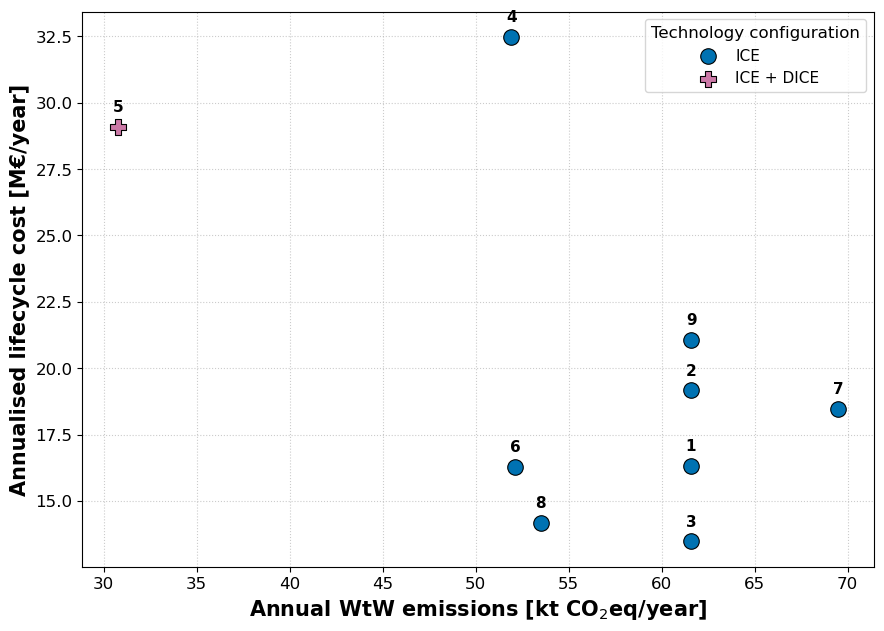


Overleaf table generated successfully.


\begin{table*}[t]
\centering
\caption{Performance and characteristics of the optimal energy-system
configurations under the scenario matrix analysis.}
\label{tab:scenario_matrix_results}
\footnotesize
\setlength{\tabcolsep}{5pt}
\renewcommand{\arraystretch}{1.5}
\begin{tabularx}{\textwidth}{
@{}
>{\centering\arraybackslash}m{0.035\textwidth}
>{\raggedright\arraybackslash}m{0.145\textwidth}
>{\centering\arraybackslash}m{0.095\textwidth}
>{\centering\arraybackslash}m{0.095\textwidth}
>{\raggedright\arraybackslash}m{0.09\textwidth}
>{\raggedright\arraybackslash}m{0.115\textwidth}
>{\raggedright\arraybackslash}X
@{}
}
\toprule
& & \multicolumn{2}{c}{\textbf{Performance indicators}}
& \multicolumn{2}{c}{\textbf{Fuel profile}}
& \textbf{Energy system} \\

\cmidrule(lr){3-4}
\cmidrule(lr){5-6}
\cmidrule(lr){7-7}

\textbf{Sc.}
& \textbf{Scenario}
& \makecell[c]{\textbf{LCC}\\(M€/year)}
& \makecell[c]{\textbf{WtW}\\(kt CO$_2$eq/year)}
& \textbf{Selected

In [172]:

# =============================================================================
# SCENARIO MATRIX ANALYSIS
# 1. Standalone cost-emissions figure
# 2. Publication-ready Overleaf table
# All nine scenario IDs and existing optimisation results retained
# =============================================================================

import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import re

# -----------------------------------------------------------------------------
# 1. Sort results by scenario ID
# -----------------------------------------------------------------------------

scenario_plot_df = (
    scenario_plot_df
    .sort_values("scenario_id")
    .reset_index(drop=True)
)

# One row per scenario
scenario_table_df = (
    scenario_plot_df
    .drop_duplicates(subset="scenario_id")
    .sort_values("scenario_id")
    .reset_index(drop=True)
)

# Verify nine scenarios
assert set(scenario_table_df["scenario_id"]) == set(range(1, 10)), \
    "Expected exactly nine scenarios."

# -----------------------------------------------------------------------------
# 2. Standalone cost-emissions scatter plot
# -----------------------------------------------------------------------------

plt.rcParams.update({
    "font.size": 12,
    "axes.labelsize": 15,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "legend.fontsize": 11,
})

fig, ax = plt.subplots(figsize=(9, 6.5))

# Preserve existing technology-specific marker and colour assignments
unique_combos = scenario_table_df["tech_combo"].unique()

for combo in unique_combos:

    sub = scenario_table_df[
        scenario_table_df["tech_combo"] == combo
    ]

    ax.scatter(
        sub["wtw_emissions"] / 1e6,
        sub["objective_cost"] / 1e6,
        marker=TECH_STYLE[combo]["marker"],
        color=TECH_STYLE[combo]["color"],
        s=125,
        edgecolors="black",
        linewidths=0.8,
        label=combo,
        zorder=3
    )

# Scenario numbers
for _, row in scenario_table_df.iterrows():

    ax.annotate(
        str(int(row["scenario_id"])),
        (
            row["wtw_emissions"] / 1e6,
            row["objective_cost"] / 1e6
        ),
        xytext=(0, 9),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold"
    )

# Axes
ax.set_xlabel(
    "Annual WtW emissions [kt CO$_2$eq/year]",
    fontweight="bold"
)

ax.set_ylabel(
    "Annualised lifecycle cost [M€/year]",
    fontweight="bold"
)

ax.grid(
    True,
    linestyle=":",
    alpha=0.65
)

ax.legend(
    title="Technology configuration",
    frameon=True,
    loc="best"
)

fig.tight_layout()

plt.savefig(
    "Scenario_Matrix_Analysis.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# -----------------------------------------------------------------------------
# 3. Helper functions for Overleaf table
# -----------------------------------------------------------------------------

def latex_escape(value):

    value = str(value)

    replacements = {
        "&": r"\&",
        "%": r"\%",
        "$": r"\$",
        "#": r"\#",
        "_": r"\_",
        "{": r"\{",
        "}": r"\}",
    }

    for old, new in replacements.items():
        value = value.replace(old, new)

    return value


def machinery_to_latex(row):

    machinery = []

    for tech in ["ICE", "DICE", "MICE", "PEMFC", "SOFC"]:

        units = int(row.get(f"{tech}_units", 0) or 0)

        if units <= 0:
            continue

        sizes = row.get(f"{tech}_sizes", [])

        if sizes is None:
            sizes = []

        sizes = [
            float(x) for x in sizes
            if pd.notna(x) and float(x) > 0
        ]

        if sizes:

            size_text = ", ".join(
                f"{x:,.0f}" for x in sizes
            )

            machinery.append(
                f"{tech}: {units} units "
                f"({size_text} kW)"
            )

        else:

            machinery.append(
                f"{tech}: {units} units"
            )

    return r" \\ ".join(machinery)


def fuel_profile_to_latex(scenario_key):

    details = scenario_details_lookup[scenario_key]

    fuel_mix = extract_selected_fuels(
        details["post_edges"]
    )

    fuel_names = []
    fuel_consumption = []

    for fuel, data in fuel_mix.items():

        fuel_kg = float(
            np.sum(
                np.asarray(
                    data["by_scenario"],
                    dtype=float
                )
            )
        )

        if fuel_kg > 1e-6:

            # kg/year -> kt/year
            fuel_kt = fuel_kg / 1e6

            fuel_names.append(
                latex_escape(fuel)
            )

            fuel_consumption.append(
                f"{latex_escape(fuel)}: {fuel_kt:.3f}"
            )

    fuels = r" \\ ".join(fuel_names) if fuel_names else "--"

    consumption = (
        r" \\ ".join(fuel_consumption)
        if fuel_consumption else "--"
    )

    return fuels, consumption


# -----------------------------------------------------------------------------
# 4. Generate Overleaf table rows
# -----------------------------------------------------------------------------

table_rows = []

for _, row in scenario_table_df.iterrows():

    scenario_id = int(row["scenario_id"])

    scenario_name = latex_escape(
        row["scenario_name"]
    )

    # Cost: M€/year
    cost = row["objective_cost"] / 1e6

    # Emissions: kt CO2eq/year
    emissions = row["wtw_emissions"] / 1e3

    # Machinery
    machinery = machinery_to_latex(row)

    # Fuel profile
    fuels, consumption = fuel_profile_to_latex(
        row["scenario_key"]
    )

    # Format multiline cells
    machinery_cell = (
        r"\makecell[l]{" + machinery + "}"
    )

    fuel_cell = (
        r"\makecell[l]{" + fuels + "}"
    )

    consumption_cell = (
        r"\makecell[l]{" + consumption + "}"
    )

    scenario_cell = latex_escape(scenario_name)

    table_row = (
        f"{scenario_id} "
        f"& {scenario_cell} "
        f"& {cost:.3f} "
        f"& {emissions:.3f} "
        f"& {fuel_cell} "
        f"& {consumption_cell} "
        f"& {machinery_cell} "
        r"\\"
    )

    table_rows.append(table_row)

# -----------------------------------------------------------------------------
# 5. Complete Overleaf table
# -----------------------------------------------------------------------------

latex_table = r"""
\begin{table*}[t]
\centering
\caption{Performance and characteristics of the optimal energy-system
configurations under the scenario matrix analysis.}
\label{tab:scenario_matrix_results}
\footnotesize
\setlength{\tabcolsep}{5pt}
\renewcommand{\arraystretch}{1.5}
\begin{tabularx}{\textwidth}{
@{}
>{\centering\arraybackslash}m{0.035\textwidth}
>{\raggedright\arraybackslash}m{0.145\textwidth}
>{\centering\arraybackslash}m{0.095\textwidth}
>{\centering\arraybackslash}m{0.095\textwidth}
>{\raggedright\arraybackslash}m{0.09\textwidth}
>{\raggedright\arraybackslash}m{0.115\textwidth}
>{\raggedright\arraybackslash}X
@{}
}
\toprule
& & \multicolumn{2}{c}{\textbf{Performance indicators}}
& \multicolumn{2}{c}{\textbf{Fuel profile}}
& \textbf{Energy system} \\

\cmidrule(lr){3-4}
\cmidrule(lr){5-6}
\cmidrule(lr){7-7}

\textbf{Sc.}
& \textbf{Scenario}
& \makecell[c]{\textbf{LCC}\\(M€/year)}
& \makecell[c]{\textbf{WtW}\\(kt CO$_2$eq/year)}
& \textbf{Selected fuels}
& \makecell[l]{\textbf{Consumption}\\(kt/year)}
& \makecell[l]{\textbf{Installed capacity}\\(kW)} \\

\midrule
"""

latex_table += "\n".join(table_rows)

latex_table += r"""
\bottomrule
\end{tabularx}
\end{table*}
"""

# -----------------------------------------------------------------------------
# 6. Save LaTeX table
# -----------------------------------------------------------------------------

with open(
    "scenario_matrix_table.tex",
    "w",
    encoding="utf-8"
) as f:

    f.write(latex_table)

print("\nOverleaf table generated successfully.")
print("\n" + latex_table)

# -----------------------------------------------------------------------------
# 7. Save numerical results for verification
# -----------------------------------------------------------------------------

scenario_table_df.to_csv(
    "scenario_matrix_results.csv",
    index=False
)

print("\nGenerated files:")
print(" - Scenario_Matrix_Analysis.png")
print(" - scenario_matrix_table.tex")
print(" - scenario_matrix_results.csv")


In [161]:

# ============================================================
# DIAGNOSTIC: FAVOURABLE LNG SCENARIO
# Inspect all fuel-source boundary edges
# ============================================================

details = scenario_details_lookup["favourable lng"]
post_edges_9 = details["post_edges"]

fuel_edges = [
    ("VLSFO", "VLSFOconv"),
    ("MGO", "MGOconv"),
    ("LNG", "LNGconv_DICE"),
    ("LNG", "LNGconv_SOFC"),
    ("LNG", "LNGconv_boiler"),
    ("bioLNG", "bioLNGconv_DICE"),
    ("bioLNG", "bioLNGconv_SOFC"),
    ("bioLNG", "bioLNGconv_boiler"),
    ("NH3", "NH3conv"),
    ("reNH3", "reNH3conv"),
    ("MOH", "MOHconv"),
    ("LH2", "LH2conv_PEMFC"),
    ("LH2", "LH2conv_SOFC"),
    ("reLH2", "reLH2conv_PEMFC"),
    ("reLH2", "reLH2conv_SOFC")
]

diagnostic = []

for source, target in fuel_edges:

    mask = (
        (post_edges_9["source"] == source) &
        (post_edges_9["target"] == target)
    )

    if mask.any():

        values = post_edges_9.loc[mask, "value"]

        total = sum(
            float(np.nansum(np.asarray(v, dtype=float)))
            if isinstance(v, (list, tuple, np.ndarray, pd.Series))
            else float(v) if pd.notna(v) else 0.0
            for v in values
        )

        diagnostic.append({
            "Fuel": source,
            "Converter": target,
            "Consumption (tonnes/year)": total / 1000
        })

diagnostic_df = pd.DataFrame(diagnostic)

print("SCENARIO 9: FUEL CONSUMPTION BY CONVERTER")
display(diagnostic_df.round(2))

print("\nSCENARIO 9: INSTALLED MACHINERY")

display(
    details["post_nodes"][
        details["post_nodes"]["installed"] > 0
    ][["name", "installed"]]
)

print("\nSCENARIO 9: EMISSIONS")
print(
    f"{scenario_results.loc[
        scenario_results['scenario'].str.lower() == 'favourable lng',
        'wtw_emissions'
    ].iloc[0]:,.2f} kgCO2eq/year"
)


SCENARIO 9: FUEL CONSUMPTION BY CONVERTER


,Fuel,Converter,Consumption (tonnes/year)
0,VLSFO,VLSFOconv,15845.0
1,MGO,MGOconv,0.0
2,LNG,LNGconv_DICE,0.0
3,LNG,LNGconv_SOFC,0.0
4,LNG,LNGconv_boiler,0.0
5,bioLNG,bioLNGconv_DICE,0.0
6,bioLNG,bioLNGconv_SOFC,0.0
7,bioLNG,bioLNGconv_boiler,0.0
8,NH3,NH3conv,0.0
9,reNH3,reNH3conv,0.0



SCENARIO 9: INSTALLED MACHINERY


,name,installed
1,luboilconv,11980.0
2,tankheater,210.5
5,VLSFOconv,5506000.0
64,EGB,22550.0
66,boiler,1412.0
75,shaft,20700.0
77,generator,4593.0
81,reverseosmosis,26.0
87,engine_ICE_1_6500,6500.0
97,engine_ICE_2_6500,6500.0



SCENARIO 9: EMISSIONS
61,580,000.00 kgCO2eq/year


In [162]:

# ============================================================
# SCENARIO 9: TRACE THE COMPLETE DICE ENERGY PATHWAY
# ============================================================

details = scenario_details_lookup["favourable lng"]
pe = details["post_edges"]
pn = details["post_nodes"]

edges_to_check = [
    ("LNG", "LNGconv_DICE"),
    ("bioLNG", "bioLNGconv_DICE"),
    ("LNGconv_DICE", "LNG_DICE_LHV"),
    ("bioLNGconv_DICE", "bioLNG_DICE_LHV"),
    ("LNG_DICE_LHV", "gas_LHV"),
    ("bioLNG_DICE_LHV", "gas_LHV"),
    ("gas_LHV", "fuel_DICE"),
    ("FO_LHV", "oil_LHV"),
    ("GO_LHV", "oil_LHV"),
    ("oil_LHV", "fuel_DICE"),
    ("fuel_DICE", "main_LHV_DICE"),
]

def show_edge_flow(post_edges, source, target):
    mask = (
        (post_edges["source"] == source) &
        (post_edges["target"] == target)
    )

    if not mask.any():
        return "EDGE NOT FOUND"

    values = post_edges.loc[mask, "value"].tolist()
    return values

print("DICE FUEL PATHWAY")
for source, target in edges_to_check:
    print(f"{source:25s} -> {target:25s}: "
          f"{show_edge_flow(pe, source, target)}")

print("\nDICE ENGINE OUTPUT")
mask = pe["source"].astype(str).str.startswith("engine_DICE_")
mask &= pe["target"].isin(["engine_rotation", "exhaustheat"])

display(pe.loc[mask, ["source", "target", "value"]])

print("\nDICE ENGINE INSTALLED CAPACITY")
display(
    pn.loc[
        pn["name"].astype(str).str.startswith("engine_DICE_") &
        (pn["installed"].fillna(0) > 0),
        ["name", "installed"]
    ]
)

print("\nMAIN ENERGY FLOWS")
for source, target in [
    ("engine_rotation", "shaft"),
    ("engine_rotation", "generator"),
    ("generator", "electricity"),
    ("reELconv", "EL"),
    ("EL", "shoreconnection"),
    ("shoreconnection", "electricity"),
]:
    print(f"{source:25s} -> {target:25s}: "
          f"{show_edge_flow(pe, source, target)}")


DICE FUEL PATHWAY
LNG                       -> LNGconv_DICE             : [[0.0, 0.0, 0.0, 0.0]]
bioLNG                    -> bioLNGconv_DICE          : [[0.0, 0.0, 0.0, 0.0]]
LNGconv_DICE              -> LNG_DICE_LHV             : [[0.0, 0.0, 0.0, 0.0]]
bioLNGconv_DICE           -> bioLNG_DICE_LHV          : [[0.0, 0.0, 0.0, 0.0]]
LNG_DICE_LHV              -> gas_LHV                  : [[0.0, 0.0, 0.0, 0.0]]
bioLNG_DICE_LHV           -> gas_LHV                  : [[0.0, 0.0, 0.0, 0.0]]
gas_LHV                   -> fuel_DICE                : [[0.0, 0.0, 0.0, 0.0]]
FO_LHV                    -> oil_LHV                  : [[49690.0, 9062.0, 18570.0, 34790.0]]
GO_LHV                    -> oil_LHV                  : [[0.0, 0.0, 0.0, 0.0]]
oil_LHV                   -> fuel_DICE                : [[0.0, 0.0, 0.0, 0.0]]
fuel_DICE                 -> main_LHV_DICE            : [[0.0, 0.0, 0.0, 0.0]]

DICE ENGINE OUTPUT


,source,target,value
364,engine_DICE_1_2000,engine_rotation,"[0.0, 0.0, 0.0, 0.0]"
365,engine_DICE_1_2000,exhaustheat,"[0.0, 0.0, 0.0, 0.0]"
368,engine_DICE_1_3500,engine_rotation,"[0.0, 0.0, 0.0, 0.0]"
369,engine_DICE_1_3500,exhaustheat,"[0.0, 0.0, 0.0, 0.0]"
372,engine_DICE_1_5000,engine_rotation,"[0.0, 0.0, 0.0, 0.0]"
373,engine_DICE_1_5000,exhaustheat,"[0.0, 0.0, 0.0, 0.0]"
376,engine_DICE_1_6500,engine_rotation,"[0.0, 0.0, 0.0, 0.0]"
377,engine_DICE_1_6500,exhaustheat,"[0.0, 0.0, 0.0, 0.0]"
380,engine_DICE_1_8000,engine_rotation,"[0.0, 0.0, 0.0, 0.0]"
381,engine_DICE_1_8000,exhaustheat,"[0.0, 0.0, 0.0, 0.0]"



DICE ENGINE INSTALLED CAPACITY


,name,installed



MAIN ENERGY FLOWS
engine_rotation           -> shaft                    : [[20700.0, 0.0, 4731.0, 13810.0]]
engine_rotation           -> generator                : [[4047.0, 4517.0, 4593.0, 3650.0]]
generator                 -> electricity              : [[3845.0, 4292.0, 4363.0, 3468.0]]
reELconv                  -> EL                       : [[0.0, 0.0, 0.0, 0.0]]
EL                        -> shoreconnection          : [[0.0, 0.0, 0.0, 0.0]]
shoreconnection           -> electricity              : [[0.0, 0.0, 0.0, 0.0]]
